# 11 · The final design

**The final step of the project plan, after experiments E1 to E6: choose every dial, run the final design on the test, and package it for the
report and for BOING.** Experiments E2, E3 and E4 each chose some dials on the practice quiz, with the other dials left at notebook 06's values.
This notebook:

1. gathers the chosen dials into one design, `br.FINAL_CONFIG`, and says where each comes from (section 1);
2. checks on the practice quiz that the choices still hold when every dial is on at once, and makes the choices left to it, each by a rule
   written down before the run (section 2): "small" from the members who count, the number of public topic clusters, ε (a finer grid, five
   practice quizzes, 20 fresh noise draws on each) and the hybrid's weights, in rounds until the weights hold; and whether the recent activity
   can get noise too;
3. runs the final design on the test: the headline table, what each value costs, new members and new groups, fake accounts, the hard rules and
   whether each reason is true (sections 3 to 7), what the privacy guarantee covers and what it does not (section 8), and user 1's lists (section 9);
4. draws the before-and-after figure (section 10), writes the test cases for BOING's JavaScript port (section 11) and the final configuration
   file (section 12), and gathers every number the report quotes into `results/summary.json` and `results/SUMMARY.md` (section 13).

**After the first review (1 November).** An independent review found claims broader than the code. The first fix judged "small" from the
member count Discover shows instead of the recommender's own noisy counts, applied R9 to posts, likes and friends too, re-chose ε on a finer
grid with 20 draws, said exactly what the privacy noise covers and measured the rest, checked each reason for being true and not only faithful to
the score, measured the topic cap against the hidden topics, and re-checked the weights with every rule on (they changed, and ε with them). The
design before the first review (`br.FINAL_CONFIG_BEFORE_REVIEW`: ε = 5, "small" from its own counts, R9 on joins only) stays as a row of every
table.

**After the second review (1 November).** A second review found four things, fixed here. (1) The first fix judged "small" from the count
Discover shows, which counts every account, so cheap fake accounts could push rival small groups over the line and lift another group: "small"
now counts only the accounts R9 counts, and section 6 tests that attack. (2) ε = 1 passed the rule only on one practice quiz, with the draws
that had also picked the weights: stage 2 now runs on five practice quizzes with fresh draws, and the same rule picks ε = 1.5 (and
8 topic clusters). (3) A "true" reason could state a count far from the truth: counts must now be close, personalised and default
lists are reported apart, and with the noise on a reason states no count. (4) The checker tests more (notebook 10), and the report's documents
are rebuilt from this run's results (section 13).

Run notebooks 01 to 10 first (and `report/figures.py` for the report's three drawings; section 13 runs it if they are missing). The code shared
by all notebooks is in `boingrec.py`, in this folder. It takes about 50 minutes; section 2 runs 6 processes at once, and each half of each
round has its own cell (about 2 to 15 minutes each). Run it with a cell time limit of at least 30 minutes.

## 0 · Settings and data

`FINAL` is the final design. The other designs are steps towards it, so that each value's cost can be measured on its own: the hybrid (no
re-ranking), the E2 design (fair re-ranking, notebook 07), the same with "small" from the count Discover shows, the final design without
privacy, with clipping only, with ε = 0.5, 2 and 5, and the final design before the first review.

In [1]:
# Colab only: upload sim_v1.zip and sim_v1_split.zip (from notebooks 01 and 02), boingrec.py (from the notebooks folder) and
# results.zip (the results folder, from notebooks 03 to 10), all at once. Locally this cell does nothing.
import sys, zipfile
from pathlib import Path
if 'google.colab' in sys.modules and not Path('boingrec.py').exists():
    from google.colab import files
    for fname in files.upload():
        if fname.endswith('.zip'):
            with zipfile.ZipFile(fname) as z:
                z.extractall('results' if fname.startswith('results') else 'data')

In [2]:
import itertools
import json
import math
import os
import subprocess
import sys
import time
from dataclasses import asdict, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from joblib import Parallel, delayed     # runs several practice-quiz runs at once (joblib comes with scikit-learn), as notebook 09 does
from scipy import stats as sps
from sklearn.cluster import KMeans
import boingrec as br

SEED, K = br.SEED, br.K                      # 0 and 5, the same in every notebook
br.use_style()
pd.set_option('display.max_colwidth', 100)

FINAL = br.FINAL_CONFIG                      # the final design: section 1 says where each value comes from
BEFORE = br.FINAL_CONFIG_BEFORE_REVIEW       # the final design before the review (epsilon 5, "small" from its own counts, R9 on joins only)
EXACT = replace(FINAL, eps=None, m=None)     # the same design without R10 (no clipping, no noise)
CLIP = replace(FINAL, eps=None)              # clipping only, no noise: the setting of most test cases (section 11)
EPS05 = replace(FINAL, eps=0.5)              # stronger privacy than the final design (it fails the rule of section 2)
EPS2 = replace(FINAL, eps=2.0)               # weaker privacy: E3's choice for notebook 06's design
EPS5 = replace(FINAL, eps=5.0)               # weaker still: the first version's choice
OFF = replace(FINAL, personal=False)         # personalisation off: what every member sees by default (R1)
PUBLIC_SMALL = replace(FINAL, small_from='public')   # "small" from the count Discover shows: the first review's fix (section 6 shows its flaw)
E2_DESIGN = br.Config(c=0.05, lam=0.8)       # after E2: fair re-ranking with E2's dials, before R9 and R10
E2_PUBLIC = replace(E2_DESIGN, small_from='public', clusters=FINAL.clusters)   # the same, "small" from the count Discover shows, the final clusters
E2_W = replace(E2_PUBLIC, alpha=FINAL.alpha, beta=FINAL.beta, gamma=FINAL.gamma, delta=FINAL.delta)   # and the final weights
HYBRID = br.Config(q=0, c=None, n=None, lam=1.0)   # the hybrid without re-ranking (E1)
DRAWS = range(10)          # noise draws (noise_seed 0 to 9) behind every test number with noise on, as in E3
QUIZ_DRAWS = range(5)      # noise draws per setting on notebook 08's grid (stage 1 of the epsilon rule)
ROBUST_DRAWS = range(20)   # noise draws per setting for the decisions (stage 2, the activity, and the weights use QUIZ_DRAWS)
KEEP = 0.9                 # E3's rule: privacy may cost at most 10% of the accuracy and of the newcomer slots
Z95 = 1.96                 # 95% Monte-Carlo range: mean +- 1.96 x sd / sqrt(draws)

vis = br.load_visible()          # what a recommender may read: no test file, no hidden column
ans = br.load_answers()          # the answer key: only the scoring code reads it
tested = sorted(int(u) for u in ans.test.user_id.unique())
fit, val = br.val_split(vis)     # the practice quiz, carved from the training data (notebooks 04 to 10)
val_users = sorted(int(u) for u in val.user_id.unique())
everyone = sorted(int(u) for u in vis.users.user_id[vis.users.suspended == 0])
CL = {}


def cl_of(c):
    # each design's public topic clusters (KMeans on the group texts), made once per number of clusters
    if c.clusters not in CL:
        CL[c.clusters] = br.topic_clusters(vis, c.clusters)
    return CL[c.clusters]


clusters = cl_of(FINAL)                              # the final design's public topic clusters: the same as recommend() makes
sim = br.description_similarity(vis)                 # how alike two groups' descriptions are (for list diversity)
name = vis.groups.set_index('group_id').name
size = br.group_sizes(vis)
created = vis.groups.set_index('group_id').created_day
read_json = lambda f: json.loads((br.RESULTS / f).read_text(encoding='utf-8'))
need = math.ceil(FINAL.q * K - 1e-9)                 # newcomer slots each list must hold


def jsonable(x):
    # numpy numbers, NaN and tuples -> plain JSON values (floats rounded to 6 decimals)
    if isinstance(x, dict):
        return {str(k): jsonable(v) for k, v in x.items()}
    if isinstance(x, (list, tuple, np.ndarray)):
        return [jsonable(v) for v in x]
    if isinstance(x, (bool, np.bool_)):
        return bool(x)
    if isinstance(x, (int, np.integer)):
        return int(x)
    if isinstance(x, (float, np.floating)):
        return None if np.isnan(x) else round(float(x), 6)
    return x


def mc_range(values):
    # mean and 95% Monte-Carlo range of a measure over noise draws
    v = np.asarray(values, dtype=float)
    half = Z95 * v.std(ddof=1) / math.sqrt(len(v)) if len(v) > 1 else 0.0
    return v.mean(), v.mean() - half, v.mean() + half


print(f'{len(vis.train)} visible memberships, {len(ans.test)} hidden ones, {len(tested)} members to test, '
      f'{len(val_users)} on the practice quiz, {len(everyone)} members in all (not suspended)')

6428 visible memberships, 1531 hidden ones, 1406 members to test, 1090 on the practice quiz, 1983 members in all (not suspended)


## 1 · The final dials, and where each comes from

Every value was chosen on the practice quiz (a validation split of the training data), never on the test, in the notebook named below.
`br.FINAL_CONFIG` holds them; `br.Config()`'s own defaults stay notebook 06's, so the earlier notebooks' results do not move.

BOING turns personalisation **off** for every member by default (rule R1): they get `replace(FINAL_CONFIG, personal=False)`, the same
statistics and re-ranking without a profile. A member who switches personalisation on gets `FINAL_CONFIG`.

In [3]:
e2_rec, e3_rec, e4_rec = (read_json(f) for f in ['e2_recommendation.json', 'e3_recommendation.json', 'e4_recommendation.json'])
hyb = pd.read_csv(br.RESULTS / 'hybrid_validation.csv').iloc[0]            # the best mix of the four scores (rank 1)
t9 = pd.read_csv(br.RESULTS / 't9_validation.csv', index_col=0)['ndcg@5']    # NDCG@5 by number of tastes
DEFAULT = br.Config()
WHERE = {   # setting -> (where it was chosen, the file that records it, the value chosen there)
    # the weights: notebook 06 chose them without noise; section 2 re-checks them under the final statistics, in rounds (section 14 checks that
    # the rounds end on FINAL_CONFIG's mix)
    **{w: ("notebook 06, re-chosen in notebook 11 (section 2) under the final statistics", 'final_rounds.csv', getattr(FINAL, w))
       for w in ['alpha', 'beta', 'gamma', 'delta']},
    'k': ('notebook 05: the AI model', 't9_validation.csv', int(t9.idxmax().split()[0])),
    'topic_weight': ('notebook 04: similar descriptions', 't6_validation.csv', DEFAULT.topic_weight),
    'off_new_w': ('notebook 06: personalisation off', 'off_validation.csv', DEFAULT.off_new_w),
    **{d: ('E2, notebook 07: fair exposure and variety', 'e2_recommendation.json', e2_rec['recommended'][d]) for d in ['q', 'c', 'n', 'lam']},
    'small_from': ('notebook 11, sections 2 and 6: "small" from the member count, of the accounts R9 counts', 'final_config.json', 'r9'),
    'clusters': ('notebook 11, section 2: the number of public topic clusters', 'final_topic_clusters.csv', FINAL.clusters),
    **{d: ('E4, notebook 09: fake accounts', 'e4_recommendation.json', e4_rec[d]) for d in ['L', 'burst_w', 'young_days', 'r9_scope']},
    **{d: ("E3, notebook 08: privacy, for notebook 06's design", 'e3_recommendation.json', e3_rec[d]) for d in ['eps', 'm', 'size_share']},
    'act_eps': ('notebook 11, section 2: privacy for the recent activity (none passed the rule)', 'final_activity_privacy.csv', None),
    'count_under_noise': ('notebook 11, section 3: with the noise on, reasons name the group without the noisy count', 'final_reasons.csv', False),
}
dials = pd.DataFrame([{'setting': d, 'final': getattr(FINAL, d), 'chosen there': v, 'chosen in': where, 'file': f,
                       'what it does': br.CONFIG_MEANING[d]} for d, (where, f, v) in WHERE.items()]).set_index('setting')
dials['same'] = [a == b for a, b in zip(dials.final, dials['chosen there'])]
moved = list(dials.index[~dials.same])
print('Settings that differ from what their experiment chose:', ', '.join(moved) or 'none')
dials

Settings that differ from what their experiment chose: eps, size_share


,final,chosen there,chosen in,file,what it does,same
setting,,,,,,
alpha,0.2,0.2,"notebook 06, re-chosen in notebook 11 (section 2) under the final statistics",final_rounds.csv,"weight of ""also joined"" (collaborative filtering)",True
beta,0.2,0.2,"notebook 06, re-chosen in notebook 11 (section 2) under the final statistics",final_rounds.csv,weight of similar descriptions (TF-IDF),True
gamma,0.3,0.3,"notebook 06, re-chosen in notebook 11 (section 2) under the final statistics",final_rounds.csv,weight of friends (public friends who are members),True
delta,0.3,0.3,"notebook 06, re-chosen in notebook 11 (section 2) under the final statistics",final_rounds.csv,weight of hidden tastes (the AI model),True
k,10,10,notebook 05: the AI model,t9_validation.csv,the AI model's number of hidden tastes,True
topic_weight,0.0,0.0,notebook 04: similar descriptions,t6_validation.csv,how much a member's chosen topics count in similar descriptions,True
off_new_w,0.5,0.5,notebook 06: personalisation off,off_validation.csv,personalisation off: weight of newness (the rest is recent activity),True
q,0.2,0.2,"E2, notebook 07: fair exposure and variety",e2_recommendation.json,R4: at least ceil(q x 5) slots of each list go to new or small groups,True
c,0.05,0.05,"E2, notebook 07: fair exposure and variety",e2_recommendation.json,R4: no group gets more than c of all slots (null: no cap),True


Every dial is its experiment's choice except **ε and the share of it spent on the group sizes** (`size_share`): E3 chose ε = 2 and 25% for
notebook 06's design, where the noisy sizes also decided which groups count as small. Section 2 applies E3's rule again to the combined design.
It also makes the choices that only this notebook can make (the member count that decides "small", the number of topic clusters, privacy for
the activity, whether a reason states a noisy count), and re-checks notebook 06's weights under the final statistics, where they change (notebook 06's mix: 0.4, 0.1, 0.3, 0.2). An
account is young for 30 days, and the seed is 0.

## 2 · Do the choices still hold together? And the choices left to this notebook (practice quiz)

Each experiment chose its dials with the others at notebook 06's values. Switched on together they could interact, so we check each choice
again on the practice quiz, with every other dial at its final value, still without looking at the test. Each rule is written here before its run.

- **"Small" from a member count.** Before the first review the quota trusted the recommender's own counts, which clipping (R10) and R9
  shrink, so mid-sized groups looked small and many lists held no truly new or small group. The first fix used the member count Discover shows.
  But that count includes every account, so fake accounts that R9 ignores everywhere else could push a rival small group over the line
  (section 6). So "small" now counts only the accounts R9 counts: level 3 or more, at least 30 days old (`small_from = 'r9'`). It needs no noise
  either (section 8 says what that means for privacy). *Rule: use it if the design still keeps E2's budget (95% of the hybrid's NDCG@5, with the
  same weights).*
- **The topic clusters (R5).** The topic cap (at most n = 2 groups of one cluster) acts on public clusters of the group texts. *Rule: the number
  of clusters (5 to 30) whose lists hold 3 or more groups sharing a member-chosen topic least often, among those that keep E2's budget, both on
  average over five practice quizzes (below).* A group's member-chosen topic is the topic its training members most often chose to share
  (`topics.csv`, public), never the hidden topic.
- **ε (R10), in two stages.** Stage 1 is notebook 08's grid (ε in 0.1, 0.5, 1, 2, 5; m in 3, 5, 8; 10%, 25% or 50% of the budget on the sizes;
  5 draws each, on the practice quiz): it picks m and the split, the most accurate on average. Stage 2 tries ε from 0.5 to 5 in steps of 0.5
  (and 4, 5). *Rule (unchanged): a setting passes when the lower end of its 95% range keeps at least 90% of the accuracy (NDCG@5) and of the
  newcomer slots of the design without privacy; a range that straddles the bar does not pass (we want to be confident, not to win a coin toss).
  The smallest passing ε is chosen.* **What changed after the second review is the range.** The first version used one practice quiz and 20
  noise draws, and its range covered only the noise; those draws had also been used to pick the weights. Now stage 2 runs on **five practice
  quizzes** (five random splits of the training data, `br.val_split` seeds 0 to 4; quiz 0 is the one of notebooks 04 to 10) with **20 fresh
  noise draws on each** (draws 100 to 119, never used for anything else). The range is over the five quizzes (each the mean of its 20 draws; a
  t-range with 4 degrees of freedom), so it covers which members happen to be on the quiz as well as the noise. We also report what one release
  does: the share of single runs that keep less than 90%.
- **The hybrid's weights.** Notebook 06 chose them with no clipping and no noise. *Rule: notebook 06's protocol again (all 286 mixes, top 5 by
  the hybrid score) under the statistics just chosen, 5 noise draws; keep the mix unless another beats it by more than its 95% Monte-Carlo
  range, and then take the best one.*
- **Rounds.** The clusters and ε depend on the weights, and the weights on the noise. So the three choices above form a round; if the round's
  re-check changes the weights, the round runs again with the new weights, until the weights hold.
- **The recent activity.** The default list ranks by recent activity, which the noise did not cover. Can it get noise too (`act_eps`: the members
  who posted, each in at most m groups, plus Laplace noise)? *Rule: the same as stage 2, for the default list, against the default list without
  this noise; if no budget passes, the activity stays outside the noise and section 8 says so.*
- **E2's budget and R9's price,** at the end, with the final weights: the final design without privacy must keep at least 95% of the hybrid's
  NDCG@5, and R9 may cost accuracy only within noise.

In [4]:
WEIGHTS = ['alpha', 'beta', 'gamma', 'delta']
MIXES = [w for w in itertools.product(np.round(np.arange(0, 1.01, 0.1), 1), repeat=4) if abs(sum(w) - 1) < 1e-9]   # notebook 06's 286 mixes
K_GRID = [5, 8, 10, 15, 20, 25, 30]
EPS_GRID, M_GRID, SHARE_GRID = [0.1, 0.5, 1.0, 2.0, 5.0], [3, 5, 8], [0.1, 0.25, 0.5]     # notebook 08's grid (stage 1)
FINE = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0]                                    # stage 2
QUIZ_SEEDS = [0, 1, 2, 3, 4]       # five practice quizzes (br.val_split seeds); quiz 0 is the one of notebooks 04 to 10
STAGE2_DRAWS = range(100, 120)     # stage 2's noise draws: 20 on each quiz, none of them the draws 0 to 4 that stage 1 and the weights use
N_JOBS = min(6, os.cpu_count() or 1)                 # practice-quiz runs done at once (joblib processes, as in notebook 09)
T95 = float(sps.t.ppf(0.975, len(QUIZ_SEEDS) - 1))   # 95% range over 5 quizzes: mean +- 2.78 x sd / sqrt(5)
mixed = lambda c, w: replace(c, **dict(zip(WEIGHTS, w)))                                # a design with the hybrid's weights w


def chosen_topics(f):
    # each group's member-chosen topic: the topic its training members most often chose to share (public: topics.csv); ties alphabetical
    picked = f.train.merge(vis.topics, on='user_id')
    return picked.groupby('group_id').topic.agg(lambda s: s.value_counts().sort_index().idxmax())


QUIZZES = {}                       # quiz seed -> (training part, hidden part, its members, member-chosen topics)
for s in QUIZ_SEEDS:
    f_, v_ = br.val_split(vis, seed=s)
    QUIZZES[s] = (f_, v_, sorted(int(u) for u in v_.user_id.unique()), chosen_topics(f_))
assert QUIZZES[0][0].train.equals(fit.train) and QUIZZES[0][2] == val_users, 'quiz 0 is the practice quiz of notebooks 04 to 10'
CHOSEN_TOPIC = QUIZZES[0][3]


def pile_share(lists, chosen=None):
    # share of lists holding 3 or more groups that share a member-chosen topic (groups no member labelled are left out)
    chosen = CHOSEN_TOPIC if chosen is None else chosen
    return float(np.mean([pd.Series([chosen[g] for g in l if g in chosen.index]).value_counts().max() > 2
                          if any(g in chosen.index for g in l) else False for l in lists.values()]))


def below_quota(lists, v, c=None):
    # lists holding fewer than ceil(q x 5) groups that are new or small: by the member count Discover shows (c None), or by
    # the members who count under R9 (c = FINAL: the final design's own definition, br.newcomer_groups(v, FINAL))
    nc = br.newcomer_groups(v, c)
    return int(sum(len(l) >= need and sum(g in nc for g in l) < need for l in lists.values()))


def quiz_measures(recs, quiz):
    # E1's metrics of one run on a practice quiz, plus the quota both ways, the topic piles and how often a rule was relaxed
    f_, v_, users_, chosen_ = quiz
    lists = br.lists_from(recs)
    r = br.evaluate(lists, v_, f_)
    r['lists below the quota (members who count)'] = below_quota(lists, f_, FINAL)
    r['lists below the quota (count Discover shows)'] = below_quota(lists, f_)
    r['lists with 3+ of one chosen topic'] = pile_share(lists, chosen_)
    r['relaxed'] = sum(recs.attrs['relaxed'].values())
    return r


def on_quiz(c, stats=None, users=None, cl=None, quiz=0):
    # One run on a practice quiz (quiz 0 unless said): (metrics, each member's NDCG@5, how many times a rule was relaxed)
    f_, v_, users_, chosen_ = QUIZZES[quiz]
    recs = br.recommend(users_ if users is None else users, f_, c, stats, clusters=cl_of(c) if cl is None else cl)
    r = quiz_measures(recs, QUIZZES[quiz])
    return r, br.relevance_per_user(br.lists_from(recs), v_)['ndcg@5'], r['relaxed']


def quiz_batch(configs, quiz, clusters_by_k):
    # Runs in a worker process: one practice-quiz run per design in configs, all on one quiz -> a list of dicts of measures
    return [dict(quiz_measures(br.recommend(quiz[2], quiz[0], c, clusters=clusters_by_k[c.clusters]), quiz)) for c in configs]


def run_many(tasks):
    # tasks: [(quiz seed, [designs])] -> for each task, the measures of each design, in order; N_JOBS processes at once.
    # Every run is seeded, so the numbers are the same as one run after another in this kernel.
    cls = {k_: cl_of(br.Config(clusters=k_)) for k_ in sorted({c.clusters for _, cs in tasks for c in cs})}
    return Parallel(n_jobs=N_JOBS, max_nbytes=None)(delayed(quiz_batch)(cs, QUIZZES[s], cls) for s, cs in tasks)


def across(per_quiz):
    # the mean over the quizzes (each quiz: the mean of its runs) and its 95% range (t, 4 degrees of freedom): it covers which members
    # are on the quiz as well as the noise
    m = np.array([np.mean(v) for v in per_quiz])
    half = T95 * m.std(ddof=1) / math.sqrt(len(m))
    return m.mean(), m.mean() - half, m.mean() + half


# for the weights: NDCG@5 of br.top_k's lists for many mixes at once (quiz 0, as in notebook 06)
gids = br.group_ids(vis)
hidden = np.zeros((len(val_users), len(gids)), dtype=bool)
hidden[pd.Index(val_users).get_indexer(val.user_id), np.searchsorted(gids, val.group_id)] = True
ideal = np.array([sum(1 / np.log2(i + 2) for i in range(min(n_, K))) for n_ in hidden.sum(axis=1)])
allowed_quiz = br.candidate_mask(fit, val_users).to_numpy()


def quick_ndcg(scores):
    # NDCG@5 of br.top_k's lists (candidates only, highest score first, ties by the smaller group id), in one go
    s = np.where(allowed_quiz, np.round(scores, 10), -np.inf)
    top = np.argsort(-s, axis=1, kind='stable')[:, :K]
    hits = hidden[np.arange(len(val_users))[:, None], top]
    return float(np.mean((hits / np.log2(np.arange(K) + 2)).sum(axis=1) / ideal))


is_mix = lambda t, w: (t[WEIGHTS].to_numpy() == np.array(w)).all(axis=1)       # rows of table t holding mix w
CLUSTER_COLS = ['ndcg@5', "share of the hybrid's NDCG@5", 'lists with 3+ of one chosen topic']


def round_a(w):
    # The first half of a round with the hybrid's weights w: the topic clusters (five quizzes), then stage 1 of epsilon (quiz 0).
    # round_b() does the second half: stage 2 of epsilon (five quizzes) and the re-check of the weights (quiz 0).
    t0 = time.time()
    out = {'weights': tuple(w)}
    hybrid_w, exact_w = mixed(HYBRID, w), mixed(EXACT, w)
    # the topic clusters, on every quiz (no noise): candidates 5 to 30 clusters, and no topic cap for comparison
    res = run_many([(s, [hybrid_w] + [replace(exact_w, clusters=k_) for k_ in K_GRID] + [replace(exact_w, n=None)]) for s in QUIZ_SEEDS])
    rows = []
    for s, r_ in zip(QUIZ_SEEDS, res):
        labels = [str(k_) for k_ in K_GRID] + ['no topic cap (n = None)']
        rows += [{'quiz': s, 'clusters': lab, 'ndcg@5': x['ndcg@5'], "share of the hybrid's NDCG@5": x['ndcg@5'] / r_[0]['ndcg@5'],
                  'lists with 3+ of one chosen topic': x['lists with 3+ of one chosen topic'], 'relaxed': x['relaxed'], 'hybrid': r_[0]['ndcg@5']}
                 for lab, x in zip(labels, r_[1:])]
        # clusters learned from the AI model's tastes (from the counts, not public text): for comparison only
        f_, v_, users_, chosen_ = QUIZZES[s]
        tastes_ = br.stats_for(f_, exact_w).tastes.to_numpy()
        tastes_ = tastes_ / np.maximum(np.linalg.norm(tastes_, axis=1, keepdims=True), 1e-12)
        tcl = pd.Series(KMeans(n_clusters=10, random_state=SEED, n_init=10).fit_predict(tastes_), index=pd.Index(gids, name='group_id'))
        x = quiz_measures(br.recommend(users_, f_, exact_w, clusters=tcl), QUIZZES[s])
        rows.append({'quiz': s, 'clusters': "10 from the AI model's tastes", 'ndcg@5': x['ndcg@5'], "share of the hybrid's NDCG@5": x['ndcg@5'] / r_[0]['ndcg@5'],
                     'lists with 3+ of one chosen topic': x['lists with 3+ of one chosen topic'], 'relaxed': x['relaxed'], 'hybrid': r_[0]['ndcg@5']})
    runs_c = pd.DataFrame(rows)
    ct = runs_c.groupby('clusters', sort=False)[CLUSTER_COLS].mean()
    ct['relaxed'] = runs_c.groupby('clusters', sort=False).relaxed.sum()
    ct['candidate'] = [c_.isdigit() for c_ in ct.index]
    best_on = {}                                       # what the rule would pick on each quiz alone (for the record)
    for s, d_ in runs_c[runs_c.clusters.str.isdigit()].groupby('quiz'):
        ok_s = d_[d_["share of the hybrid's NDCG@5"] >= 0.95]
        best_on[s] = int(ok_s.assign(k=ok_s.clusters.astype(int)).sort_values(['lists with 3+ of one chosen topic', 'k']).clusters.iloc[0]) if len(ok_s) else None
    for s in QUIZ_SEEDS:
        ct[f'piles, quiz {s}'] = runs_c[runs_c.quiz == s].set_index('clusters').reindex(ct.index)['lists with 3+ of one chosen topic']
    ok_ = ct[ct.candidate & (ct["share of the hybrid's NDCG@5"] >= 0.95)]
    out['clusters'] = int(ok_.assign(k=ok_.index.astype(int)).sort_values(['lists with 3+ of one chosen topic', 'k']).index[0])
    out['cluster_table'], out['cluster_runs'], out['clusters_each_quiz'] = ct, runs_c, best_on
    exact_w = replace(exact_w, clusters=out['clusters'])
    # stage 1: notebook 08's grid on quiz 0, 5 draws (0 to 4)
    configs1 = [replace(exact_w, eps=eps, m=m, size_share=share, noise_seed=d) for share in SHARE_GRID for eps in EPS_GRID for m in M_GRID
                for d in QUIZ_DRAWS]
    res = run_many([(0, [exact_w])] + [(0, configs1[i:i + len(QUIZ_DRAWS)]) for i in range(0, len(configs1), len(QUIZ_DRAWS))])
    ref_ = res[0][0]
    out['ref'] = ref_
    runs1 = pd.DataFrame([{'size_share': c.size_share, 'eps': c.eps, 'm': c.m, 'draw': c.noise_seed, 'ndcg@5': x['ndcg@5'],
                           'newcomer_share': x['newcomer_share'], 'relaxed': x['relaxed']}
                          for c, x in zip(configs1, [x for chunk in res[1:] for x in chunk])])
    g1 = runs1.groupby(['size_share', 'eps', 'm'])
    grid_ = g1[['ndcg@5', 'newcomer_share']].mean()
    grid_['ndcg@5 sd'], grid_['runs'] = g1['ndcg@5'].std(ddof=1), g1.size()
    grid_['accuracy kept'] = grid_['ndcg@5'] / ref_['ndcg@5']
    grid_['newcomer slots kept'] = grid_['newcomer_share'] / ref_['newcomer_share']
    grid_ = grid_.reset_index()
    s1 = grid_.groupby(['size_share', 'm'])['ndcg@5'].mean().idxmax()          # the most accurate (split, m), on average over epsilon
    out['stage1'] = {'size_share': float(s1[0]), 'm': int(s1[1])}
    out['grid'], out['grid_runs'] = grid_, runs1
    out['minutes'] = (time.time() - t0) / 60
    return out


def round_b(out):
    # The second half of a round (after round_a): stage 2 of epsilon on the five quizzes, 20 fresh draws each, and the rule with a 95%
    # range over the quizzes; then the re-check of the weights under the statistics just chosen. Adds its results to out.
    t0 = time.time()
    w = out['weights']
    exact_w = replace(mixed(EXACT, w), clusters=out['clusters'])
    tasks = [(s, [exact_w]) for s in QUIZ_SEEDS]
    keys = [(s, eps) for s in QUIZ_SEEDS for eps in FINE]
    tasks += [(s, [replace(exact_w, eps=eps, noise_seed=d, **out['stage1']) for d in STAGE2_DRAWS]) for s, eps in keys]
    res = run_many(tasks)
    refs = {s: res[i][0] for i, s in enumerate(QUIZ_SEEDS)}
    runs2 = pd.DataFrame([{'quiz': s, 'eps': eps, 'draw': d, 'ndcg@5': x['ndcg@5'], 'newcomer_share': x['newcomer_share'],
                           'accuracy kept': x['ndcg@5'] / refs[s]['ndcg@5'], 'newcomer slots kept': x['newcomer_share'] / refs[s]['newcomer_share'],
                           'lists below the quota (members who count)': x['lists below the quota (members who count)'],
                           'lists below the quota (count Discover shows)': x['lists below the quota (count Discover shows)'], 'relaxed': x['relaxed']}
                          for (s, eps), chunk in zip(keys, res[len(QUIZ_SEEDS):]) for d, x in zip(STAGE2_DRAWS, chunk)])
    rows = []
    for eps, d_ in runs2.groupby('eps'):
        row = {'eps': eps, 'quizzes': d_.quiz.nunique(), 'runs': len(d_), 'ndcg@5': d_['ndcg@5'].mean(), 'newcomer_share': d_['newcomer_share'].mean()}
        for col in ['accuracy kept', 'newcomer slots kept']:
            row[col], row[f'{col} low'], row[f'{col} high'] = across([q_[col].to_numpy() for _, q_ in d_.groupby('quiz')])
        row['passes'] = row['accuracy kept low'] >= KEEP and row['newcomer slots kept low'] >= KEEP
        row['straddles the bar'] = (not row['passes']) and (row['accuracy kept high'] >= KEEP and row['newcomer slots kept high'] >= KEEP)
        # the first version's rule on each quiz alone (a Monte-Carlo range over that quiz's 20 draws only), and single releases
        row['quizzes passing alone'] = int(sum(mc_range(q_['accuracy kept'])[1] >= KEEP and mc_range(q_['newcomer slots kept'])[1] >= KEEP
                                               for _, q_ in d_.groupby('quiz')))
        row['single releases below 90%'] = float((d_['accuracy kept'] < KEEP).mean())
        for s, q_ in d_.groupby('quiz'):
            row[f'accuracy kept, quiz {s}'] = q_['accuracy kept'].mean()
        rows.append(row)
    fine_ = pd.DataFrame(rows).set_index('eps')
    out['eps'] = float(fine_.index[fine_.passes][0]) if fine_.passes.any() else None
    out['fine'], out['fine_runs'], out['refs'] = fine_, runs2, refs
    # the re-check of the weights under the statistics just chosen (quiz 0, draws 0 to 4, as notebook 06's protocol)
    chosen_c = replace(FINAL, clusters=out['clusters'], eps=out['eps'], **out['stage1'])
    rows = []
    for d in QUIZ_DRAWS:
        st = br.stats_for(fit, replace(chosen_c, noise_seed=d))
        parts = {p: v.to_numpy() for p, v in br.hybrid_parts(fit, val_users, chosen_c, st).items()}
        for mix in MIXES:
            rows.append({**dict(zip(WEIGHTS, mix)), 'draw': d, 'ndcg@5': quick_ndcg(sum(wi * parts[p] for wi, p in zip(mix, br.PARTS)))})
    wr = pd.DataFrame(rows)
    wt = wr.groupby(WEIGHTS)['ndcg@5'].agg(['mean', 'std']).sort_values('mean', ascending=False).reset_index()
    wt.insert(0, 'rank', np.arange(1, len(wt) + 1))
    best = tuple(float(x) for x in wt.iloc[0][WEIGHTS])
    piv = wr.pivot_table(index='draw', columns=WEIGHTS, values='ndcg@5')
    gap_ = mc_range(piv[best] - piv[tuple(w)]) if best != tuple(w) else (0.0, 0.0, 0.0)
    out.update(weights_table=wt, best=best, gap=gap_, rank=int(wt[is_mix(wt, w)]['rank'].iloc[0]), keep=gap_[1] <= 0)
    # the fast scoring is exact: this round's mix, draw 0, through br.top_k and br.relevance_per_user
    st0_ = br.stats_for(fit, replace(chosen_c, noise_seed=0))
    slow_ = br.relevance_per_user(br.top_k(br.hybrid_scores(br.hybrid_parts(fit, val_users, chosen_c, st0_), weights=w), fit,
                                           user_ids=val_users), val)['ndcg@5'].mean()
    out['exact_shortcut'] = abs(slow_ - wr[(wr.draw == 0).to_numpy() & is_mix(wr, w)]['ndcg@5'].iloc[0]) < 1e-12
    out['minutes'] += (time.time() - t0) / 60
    return out


def report(res, n):
    print(f"Round {n}: weights {res['weights']} -> {res['clusters']} clusters (the rule on each quiz alone: {res['clusters_each_quiz']}), "
          f"m = {res['stage1']['m']}, {res['stage1']['size_share']:.0%} on the sizes, epsilon = {res['eps']:g}; the mix ranks {res['rank']} of "
          f"{len(MIXES)}, the best {res['best']} beats it by {res['gap'][0]:.4f} (95% range {res['gap'][1]:.4f} to {res['gap'][2]:.4f}): "
          f"{'keep it' if res['keep'] else 'change it'} ({res['minutes']:.1f} minutes)")


def first_half(res, n):
    print(f"Round {n}, first half: weights {res['weights']} -> {res['clusters']} clusters (the rule on each quiz alone: "
          f"{res['clusters_each_quiz']}), m = {res['stage1']['m']}, {res['stage1']['size_share']:.0%} on the sizes ({res['minutes']:.1f} minutes)")


# Round 1 starts from notebook 06's mix. Each half of a round has its own cell (about 2 to 15 minutes each, with 6 processes; longer when the
# computer is busy).
rounds = [round_a((br.Config().alpha, br.Config().beta, br.Config().gamma, br.Config().delta))]
first_half(rounds[-1], 1)

Round 1, first half: weights (0.4, 0.1, 0.3, 0.2) -> 8 clusters (the rule on each quiz alone: {0: 5, 1: 25, 2: 20, 3: None, 4: 10}), m = 3, 10% on the sizes (1.7 minutes)


In [5]:
# Round 1, second half: stage 2 of epsilon and the re-check of the weights
round_b(rounds[-1])
report(rounds[-1], 1)

Round 1: weights (0.4, 0.1, 0.3, 0.2) -> 8 clusters (the rule on each quiz alone: {0: 5, 1: 25, 2: 20, 3: None, 4: 10}), m = 3, 10% on the sizes, epsilon = 2; the mix ranks 14 of 286, the best (0.2, 0.2, 0.3, 0.3) beats it by 0.0121 (95% range 0.0062 to 0.0180): change it (5.8 minutes)


In [6]:
# Round 2, first half, only if round 1's re-check changed the weights
if not rounds[-1]['keep']:
    rounds.append(round_a(rounds[-1]['best']))
    first_half(rounds[-1], 2)
else:
    print('Round 1 kept the weights: no round 2.')

Round 2, first half: weights (0.2, 0.2, 0.3, 0.3) -> 8 clusters (the rule on each quiz alone: {0: 15, 1: None, 2: 10, 3: 25, 4: 5}), m = 3, 10% on the sizes (1.3 minutes)


In [7]:
# Round 2, second half
if len(rounds) == 2 and 'keep' not in rounds[-1]:
    round_b(rounds[-1])
    report(rounds[-1], 2)
else:
    print('No round 2.')

Round 2: weights (0.2, 0.2, 0.3, 0.3) -> 8 clusters (the rule on each quiz alone: {0: 15, 1: None, 2: 10, 3: 25, 4: 5}), m = 3, 10% on the sizes, epsilon = 1.5; the mix ranks 1 of 286, the best (0.2, 0.2, 0.3, 0.3) beats it by 0.0000 (95% range 0.0000 to 0.0000): keep it (5.3 minutes)


In [8]:
# Round 3 (the last one allowed), only if round 2 changed the weights again
if len(rounds) == 2 and not rounds[-1]['keep']:
    rounds.append(round_a(rounds[-1]['best']))
    first_half(rounds[-1], 3)
    round_b(rounds[-1])
    report(rounds[-1], 3)
else:
    print('No round 3: the weights held.')

No round 3: the weights held.


In [9]:
last = rounds[-1]
CHOSEN = {'weights': last['weights'], 'clusters': last['clusters'], 'eps': last['eps'], **last['stage1']}
ref, grid, grid_runs, fine, fine_runs = last['ref'], last['grid'], last['grid_runs'], last['fine'], last['fine_runs']
cluster_table, weights_table = last['cluster_table'], last['weights_table']
K_CHOSEN, STAGE1, KEEP_WEIGHTS = last['clusters'], last['stage1'], last['keep']
chosen_rank, best_w, (gap_mean, gap_low, gap_high) = last['rank'], last['best'], last['gap']
round_rows = [{'round': i + 1, **dict(zip(WEIGHTS, r_['weights'])), 'clusters': r_['clusters'], 'm': r_['stage1']['m'],
               'size_share': r_['stage1']['size_share'], 'eps': r_['eps'], 'accuracy kept low (eps)': r_['fine'].loc[r_['eps'], 'accuracy kept low'],
               'rank of the mix': r_['rank'], 'best mix': str(r_['best']), 'best minus the mix': r_['gap'][0],
               'best minus the mix, low': r_['gap'][1], 'best minus the mix, high': r_['gap'][2], 'keep the mix': r_['keep'],
               'minutes': r_['minutes']}
              for i, r_ in enumerate(rounds)]
round_table = pd.DataFrame(round_rows).set_index('round')
br.save_table(round_table, 'final_rounds.csv', decimals=4)
br.save_table(cluster_table, 'final_topic_clusters.csv', decimals=4)
br.save_table(grid.set_index(['size_share', 'eps', 'm']), 'final_validation.csv', decimals=4)
br.save_table(fine, 'final_eps_fine.csv', decimals=4)
br.save_table(fine_runs.set_index(['quiz', 'eps', 'draw']), 'final_eps_runs.csv', decimals=4)
br.save_table(weights_table.set_index('rank'), 'final_weights.csv', decimals=4)
if len(rounds) > 1:                                  # the first round's tables, for the record
    br.save_table(rounds[0]['fine'], 'final_round1_eps_fine.csv', decimals=4)
    br.save_table(rounds[0]['weights_table'].set_index('rank'), 'final_round1_weights.csv', decimals=4)
    br.save_table(rounds[0]['cluster_table'], 'final_round1_topic_clusters.csv', decimals=4)
F = lambda eps, col: fine.loc[eps, col]
print(f'The rounds pick: {CHOSEN} (br.FINAL_CONFIG: weights {(FINAL.alpha, FINAL.beta, FINAL.gamma, FINAL.delta)}, {FINAL.clusters} clusters, '
      f'epsilon {FINAL.eps:g}, m {FINAL.m}, size_share {FINAL.size_share}).')
round_table.round(4)

The rounds pick: {'weights': (0.2, 0.2, 0.3, 0.3), 'clusters': 8, 'eps': 1.5, 'size_share': 0.1, 'm': 3} (br.FINAL_CONFIG: weights (0.2, 0.2, 0.3, 0.3), 8 clusters, epsilon 1.5, m 3, size_share 0.1).


,alpha,beta,gamma,delta,clusters,m,size_share,eps,accuracy kept low (eps),rank of the mix,best mix,best minus the mix,"best minus the mix, low","best minus the mix, high",keep the mix,minutes
round,,,,,,,,,,,,,,,,
1,0.4,0.1,0.3,0.2,8,3,0.1,2.0,0.9083,14,"(0.2, 0.2, 0.3, 0.3)",0.0121,0.0062,0.018,False,5.8187
2,0.2,0.2,0.3,0.3,8,3,0.1,1.5,0.9192,1,"(0.2, 0.2, 0.3, 0.3)",0.0000,0.0000,0.000,True,5.3222


The last round in detail. **The topic clusters** (the final design without privacy, the mean over the five quizzes, then each quiz's own
share of lists with a pile; for comparison only, not candidates: no topic cap at all, and clusters learned from the AI model's tastes, which come
from the private counts so they cost no extra privacy, but are not public text):

In [10]:
cluster_table.round(3)

,ndcg@5,share of the hybrid's NDCG@5,lists with 3+ of one chosen topic,relaxed,candidate,"piles, quiz 0","piles, quiz 1","piles, quiz 2","piles, quiz 3","piles, quiz 4"
clusters,,,,,,,,,,
5,0.438,0.947,0.563,0.0,True,0.549,0.561,0.558,0.581,0.565
8,0.442,0.956,0.583,0.0,True,0.587,0.580,0.574,0.575,0.597
10,0.441,0.954,0.585,0.0,True,0.583,0.587,0.574,0.580,0.602
15,0.439,0.949,0.547,0.0,True,0.530,0.555,0.539,0.536,0.575
20,0.442,0.956,0.594,0.0,True,0.589,0.602,0.579,0.588,0.612
25,0.442,0.956,0.594,0.0,True,0.584,0.599,0.587,0.585,0.613
30,0.443,0.958,0.600,0.0,True,0.596,0.601,0.590,0.592,0.623
no topic cap (n = None),0.445,0.962,0.602,0.0,False,0.593,0.602,0.594,0.594,0.629
10 from the AI model's tastes,0.426,0.922,0.201,0.0,False,0.164,0.100,0.253,0.237,0.253


**ε, stage 1** (notebook 08's grid, 5 draws each): the most accurate setting at each ε.

In [11]:
best_each = grid.loc[grid.groupby('eps')['ndcg@5'].idxmax()]
print(f"Stage 1 picks m = {STAGE1['m']} and {STAGE1['size_share']:.0%} of the budget on the sizes (the most accurate on average); "
      f"it is the most accurate at {int(((best_each.m == STAGE1['m']) & (best_each.size_share == STAGE1['size_share'])).sum())} of the {len(EPS_GRID)} values of epsilon; "
      f"{len(grid_runs)} runs, a rule was relaxed {int(grid_runs.relaxed.sum())} times.")
best_each.set_index('eps')[['size_share', 'm', 'ndcg@5', 'accuracy kept', 'newcomer slots kept']].round(3)

Stage 1 picks m = 3 and 10% of the budget on the sizes (the most accurate on average); it is the most accurate at 3 of the 5 values of epsilon; 225 runs, a rule was relaxed 0 times.


,size_share,m,ndcg@5,accuracy kept,newcomer slots kept
eps,,,,,
0.1,0.10,3,0.314,0.687,1.251
0.5,0.25,3,0.382,0.838,1.057
1.0,0.10,3,0.419,0.918,1.037
2.0,0.10,3,0.435,0.954,1.024
5.0,0.25,3,0.449,0.984,1.033


**ε, stage 2** (five quizzes, 20 fresh draws on each; the range is over the quizzes). The last columns: on how many quizzes the first
version's rule (a range over that quiz's 20 draws only) would pass; the share of single runs (one quiz, one draw: one release) that keep less
than 90% of the accuracy; and each quiz's mean:

In [12]:
fine.round(4)

,quizzes,runs,ndcg@5,newcomer_share,accuracy kept,accuracy kept low,accuracy kept high,newcomer slots kept,newcomer slots kept low,newcomer slots kept high,passes,straddles the bar,quizzes passing alone,single releases below 90%,"accuracy kept, quiz 0","accuracy kept, quiz 1","accuracy kept, quiz 2","accuracy kept, quiz 3","accuracy kept, quiz 4"
eps,,,,,,,,,,,,,,,,,,,
0.5,5,100,0.3584,0.2173,0.8103,0.7954,0.8252,1.0862,1.0773,1.0951,False,False,0,1.00,0.8132,0.7925,0.8160,0.8242,0.8054
1.0,5,100,0.3967,0.2098,0.8969,0.8872,0.9067,1.0482,1.0441,1.0523,False,True,0,0.59,0.8986,0.8886,0.9035,0.9051,0.8889
1.5,5,100,0.4107,0.2060,0.9284,0.9192,0.9376,1.0293,1.0278,1.0308,True,False,5,0.08,0.9352,0.9232,0.9315,0.9341,0.9182
2.0,5,100,0.4176,0.2048,0.9440,0.9355,0.9525,1.0233,1.0218,1.0249,True,False,5,0.00,0.9516,0.9420,0.9442,0.9485,0.9338
2.5,5,100,0.4219,0.2042,0.9538,0.9462,0.9614,1.0204,1.0175,1.0233,True,False,5,0.00,0.9613,0.9506,0.9536,0.9578,0.9455
3.0,5,100,0.4243,0.2037,0.9593,0.9507,0.9680,1.0179,1.0155,1.0204,True,False,5,0.00,0.9686,0.9562,0.9559,0.9645,0.9515
3.5,5,100,0.4259,0.2034,0.9628,0.9552,0.9704,1.0163,1.0144,1.0182,True,False,5,0.00,0.9703,0.9583,0.9600,0.9683,0.9569
4.0,5,100,0.4271,0.2033,0.9657,0.9588,0.9727,1.0159,1.0150,1.0167,True,False,5,0.00,0.9722,0.9623,0.9616,0.9714,0.9611
5.0,5,100,0.4288,0.2030,0.9694,0.9607,0.9781,1.0144,1.0131,1.0157,True,False,5,0.00,0.9771,0.9668,0.9615,0.9766,0.9652


**The weights** under the final statistics (the 10 best mixes of 286, mean NDCG@5 over 5 noise draws):

In [13]:
weights_table.head(10).round(4)

,rank,alpha,beta,gamma,delta,mean,std
0,1,0.2,0.2,0.3,0.3,0.4497,0.0055
1,2,0.3,0.2,0.3,0.2,0.4456,0.0057
2,3,0.2,0.2,0.4,0.2,0.4436,0.0061
3,4,0.1,0.2,0.3,0.4,0.4424,0.0066
4,5,0.3,0.1,0.3,0.3,0.4417,0.0062
5,6,0.1,0.2,0.4,0.3,0.4413,0.0048
6,7,0.2,0.1,0.4,0.3,0.4404,0.0043
7,8,0.2,0.1,0.3,0.4,0.4404,0.0031
8,9,0.2,0.3,0.3,0.2,0.4401,0.0031
9,10,0.3,0.1,0.4,0.2,0.4380,0.0052


**What the rounds found.** **Round 1** (notebook 06's weights 0.4, 0.1, 0.3, 0.2) picks 8 clusters, puts 10%
of the budget on the sizes (with "small" from a member count, the noisy sizes matter less, so more goes to the pair counts) and **ε = 2**.
But its re-check of the weights under those noisy statistics finds a better mix, (0.2, 0.2, 0.3, 0.3), which beats notebook 06's by 0.0121 NDCG@5 (95% range
0.0062 to 0.0180): "also joined" divides each overlap by two noisy group sizes, so it suffers most from the noise, and the new mix leans
on it less. **Round 2**, with that mix, picks 8 clusters, the same m and split, and **ε = 1.5**: on average over the five
quizzes it keeps 92.8% of the accuracy (95% range 91.9% to 93.8%) and 103% of the newcomer slots. ε = 1 keeps
89.7% (range 88.7% to 90.7%) and fails. The re-check then keeps the mix: the choices hold together.

**Why ε went from 1 to 1.5 (second review).** The first version of this section ran stage 2 on one practice quiz with draws 0 to 19: the
same quiz, and the same first draws, that had picked the weights. Its range covered only the noise, and there ε = 1 passed by a thin margin. On
five quizzes with fresh draws, ε = 1 keeps less than 90% on average. It would pass the first version's rule on 0 of
the 5 quizzes, and 59% of single releases (one quiz, one draw) keep less than 90% of the accuracy. At ε = 1.5, 8%
do. The rule did not change; the evidence behind it did. The promise at ε = 1.5: one member changes the odds of any result by at most
e^1.5 ≈ 4.5 times (ε = 1: 2.7; ε = 2: 7.4; ε = 5, the first version's choice: 148), for one release of the counts.

**The topic clusters are a close call.** On average over the five quizzes, 8 clusters give the fewest lists with 3 or more
groups of one member-chosen topic (58%) among the numbers that keep E2's budget. 15 clusters, the first version's choice on one quiz,
give 55% but keep only 94.9% of the hybrid's accuracy on average, under the 95% budget. On each quiz alone the rule picks
15, none, 10, 25, 5 (quizzes 0 to 4; "none": no number keeps the budget there): the differences between numbers of clusters are within the noise.

**Privacy for the recent activity too?** The default list (personalisation off) ranks by recent activity and newness. With `act_eps`, the
activity becomes the number of members who posted in the group in the last 30 days, each counted in at most m = 3 groups, plus Laplace noise
(likes are left out: a like hangs on another member's post, so one member's rows could change many counts). We try the definition alone
(no noise) and five budgets, 20 draws each, against the default list without this noise.

In [14]:
ACT_EPS = [0.5, 1.0, 2.0, 5.0, 10.0]
act_ref = on_quiz(OFF)[0]
act_rows = [{'act_eps': 'none (activity as before: posts and likes, no noise)', 'ndcg@5': act_ref['ndcg@5'], 'newcomer_share': act_ref['newcomer_share'],
             'accuracy kept': 1.0, 'accuracy kept low': 1.0, 'newcomer slots kept': 1.0, 'newcomer slots kept low': 1.0, 'passes': None}]
act_res = run_many([(0, [replace(OFF, act_eps=1e9)])] + [(0, [replace(OFF, act_eps=ae, noise_seed=d) for d in ROBUST_DRAWS]) for ae in ACT_EPS])
r = act_res[0][0]
act_rows.append({'act_eps': 'the definition alone (members who posted, clipped; no noise)', 'ndcg@5': r['ndcg@5'], 'newcomer_share': r['newcomer_share'],
                 'accuracy kept': r['ndcg@5'] / act_ref['ndcg@5'], 'accuracy kept low': r['ndcg@5'] / act_ref['ndcg@5'],
                 'newcomer slots kept': r['newcomer_share'] / act_ref['newcomer_share'],
                 'newcomer slots kept low': r['newcomer_share'] / act_ref['newcomer_share'], 'passes': None})
for ae, rs in zip(ACT_EPS, act_res[1:]):
    acc, acc_lo, _ = mc_range([x['ndcg@5'] / act_ref['ndcg@5'] for x in rs])
    new, new_lo, _ = mc_range([x['newcomer_share'] / act_ref['newcomer_share'] for x in rs])
    act_rows.append({'act_eps': f'{ae:g}', 'ndcg@5': np.mean([x['ndcg@5'] for x in rs]), 'newcomer_share': np.mean([x['newcomer_share'] for x in rs]),
                     'accuracy kept': acc, 'accuracy kept low': acc_lo, 'newcomer slots kept': new, 'newcomer slots kept low': new_lo,
                     'passes': bool(acc_lo >= KEEP and new_lo >= KEEP)})
act_table = pd.DataFrame(act_rows).set_index('act_eps')
ACT_CHOSEN = next((float(i) for i, p in act_table.passes.items() if p is True), None)
br.save_table(act_table, 'final_activity_privacy.csv', decimals=4)
print('The rule picks act_eps =', ACT_CHOSEN, '(br.FINAL_CONFIG has', FINAL.act_eps, ')')
act_table.round(3)

The rule picks act_eps = None (br.FINAL_CONFIG has None )


,ndcg@5,newcomer_share,accuracy kept,accuracy kept low,newcomer slots kept,newcomer slots kept low,passes
act_eps,,,,,,,
"none (activity as before: posts and likes, no noise)",0.062,0.517,1.000,1.000,1.000,1.000,None
"the definition alone (members who posted, clipped; no noise)",0.034,0.499,0.544,0.544,0.965,0.965,None
0.5,0.011,0.718,0.185,0.147,1.389,1.324,False
1,0.012,0.703,0.201,0.167,1.360,1.292,False
2,0.021,0.611,0.345,0.296,1.183,1.120,False
5,0.032,0.528,0.513,0.455,1.021,0.942,False
10,0.034,0.508,0.545,0.490,0.982,0.925,False


**No budget passes**, and not only because of the noise: counting the members who posted, rather than posts and likes, already costs the
default list a large part of its (small) accuracy. So the activity stays outside the noise, and the privacy claim is narrowed to what the noise
covers (section 8). In BOING, an open group's posts and like counts are shown to anyone who opens the group; if BOING ever kept them to members
only, this table is the price of protecting them.

**E2's budget, R9's price, and "small" (with the final weights).**

In [15]:
FINAL_W = (FINAL.alpha, FINAL.beta, FINAL.gamma, FINAL.delta)
quiz_ref = {label_: on_quiz(c) for label_, c in [('Hybrid, no re-ranking (final weights)', mixed(HYBRID, FINAL_W)),
                                                 ('E2 design (fair re-ranking)', E2_DESIGN),
                                                 ('E2 design, "small" from the count Discover shows, final clusters and weights', E2_W),
                                                 ('Final design without privacy', EXACT)]}
hybrid_quiz = quiz_ref['Hybrid, no re-ranking (final weights)'][0]['ndcg@5']
budget_share = quiz_ref['Final design without privacy'][0]['ndcg@5'] / hybrid_quiz
r9_quiz = quiz_ref['E2 design, "small" from the count Discover shows, final clusters and weights'][1] - quiz_ref['Final design without privacy'][1]
r9_quiz_low, r9_quiz_high = br.bootstrap_ci(r9_quiz)
# "small": the recommender's own counts (before the first review), the count Discover shows (the first fix) and the members who count (final),
# with the final privacy, 5 draws each
QUOTA_COLS = ['lists below the quota (members who count)', 'lists below the quota (count Discover shows)']
small_rows = []
for label_, c in [("its own counts (before the first review)", replace(FINAL, small_from='counted')),
                  ('the count Discover shows (the first fix)', PUBLIC_SMALL), ('the members who count (final)', FINAL)]:
    for d in QUIZ_DRAWS:
        r, _, _ = on_quiz(replace(c, noise_seed=d))
        small_rows.append({'"small" judged from': label_, 'draw': d, 'ndcg@5': r['ndcg@5'], 'newcomer_share': r['newcomer_share'],
                           **{col: r[col] for col in QUOTA_COLS}})
small_quiz = pd.DataFrame(small_rows).groupby('"small" judged from', sort=False)[['ndcg@5', 'newcomer_share'] + QUOTA_COLS].mean()
display(pd.DataFrame({k: v[0] for k, v in quiz_ref.items()}).T[['ndcg@5', 'hit_rate', 'newcomer_share'] + QUOTA_COLS + ['gini', 'coverage']].round(4))
display(small_quiz.round(4))
print(f"E2's budget: the final design without privacy keeps {budget_share:.2%} of the hybrid's NDCG@5 (same weights; 95% needed).")
print(f"R9's price on the quiz: {r9_quiz.mean():.4f} NDCG@5 (95% range {r9_quiz_low:.4f} to {r9_quiz_high:.4f}).")

,ndcg@5,hit_rate,newcomer_share,lists below the quota (members who count),lists below the quota (count Discover shows),gini,coverage
"Hybrid, no re-ranking (final weights)",0.4706,0.6294,0.0462,884.0,884.0,0.6247,116.0
E2 design (fair re-ranking),0.4640,0.6119,0.2006,0.0,0.0,0.5348,125.0
"E2 design, ""small"" from the count Discover shows, final clusters and weights",0.4575,0.5963,0.2033,0.0,0.0,0.5188,127.0
Final design without privacy,0.4564,0.5927,0.2031,0.0,0.0,0.5172,127.0


,ndcg@5,newcomer_share,lists below the quota (members who count),lists below the quota (count Discover shows)
"""small"" judged from",,,,
its own counts (before the first review),0.4346,0.1359,431.0,431.0
the count Discover shows (the first fix),0.4333,0.2082,0.0,0.0
the members who count (final),0.4333,0.2082,0.0,0.0


E2's budget: the final design without privacy keeps 96.98% of the hybrid's NDCG@5 (same weights; 95% needed).
R9's price on the quiz: 0.0011 NDCG@5 (95% range -0.0035 to 0.0058).


## 3 · The final design on the test: the headline table

The test set (1,406 members, notebook 02) is scored exactly as in E1. Rows with privacy noise are the mean of 10 noise draws (`noise_seed`
0 to 9), with their spread (sd) across the draws; the 95% range of NDCG@5 is over members (bootstrap), on each member's NDCG@5 averaged over the
draws.

- **Popularity** is BOING today (biggest groups first). **"Also joined"**, **the AI model** and **the hybrid** are E1's components, for context.
- **Hybrid + fair re-ranking (E2 dials)** adds rules R4 and R5; the next row judges "small" from the member count Discover shows (with the
  final topic clusters), the next uses the final weights; **the final design without privacy** adds R9 (which also makes "small" count only
  the members R9 counts); **the final design** adds R10 (m = 3 and the chosen ε).
- **Clipping only** is the final design with the noise off (the setting of most test cases); **ε = 0.5**, **2** and **5** are the alternatives around
  the chosen ε; **before the review** is the first version's final design, before the first review (ε = 5, "small" from its own counts, R9 on
  joins only).
- **Personalisation off** is the list every member sees by default (R1), with the final dials.

Three extra columns: **lists below the quota**, the lists that hold no group that is new or small, measured two ways without noise: by the
**members who count** (the final design's own definition: accounts at level 3 or more, at least 30 days old) and by the **count Discover shows**
(every account); and **lists with 3+ of one hidden topic**, a scoring-side measure of the topic cap (R5) that uses the answer key. The newcomer
share (as in every notebook) uses the count Discover shows.

In [16]:
topic = ans.group_topic          # the hidden topics: scoring only (topics per list, and the topic cap against the real topics)
ROWS = {
    'popularity': 'Popularity (BOING today)',
    'also_joined': '"Also joined" (component)',
    'hidden_tastes': 'Hidden tastes, the AI model (component)',
    'hybrid': 'Hybrid, no re-ranking (component)',
    'e2': 'Hybrid + fair re-ranking (E2 dials)',
    'e2_public': 'E2 dials, "small" from the count Discover shows, final clusters',
    'e2_w': 'The same with the final weights',
    'exact': 'Final design without privacy',
    'clip': 'Final design, clipping only (test cases)',
    'final': f'Final design (ε = {FINAL.eps:g}, m = {FINAL.m})',
    'eps05': 'Final design with ε = 0.5',
    'eps2': 'Final design with ε = 2',
    'eps5': 'Final design with ε = 5',
    'before': 'Final design before the review (ε = 5)',
    'off': 'Personalisation off (default list)',
}
CONFIGS = {'hybrid': HYBRID, 'e2': E2_DESIGN, 'e2_public': E2_PUBLIC, 'e2_w': E2_W, 'exact': EXACT, 'clip': CLIP, 'final': FINAL,
           'eps05': EPS05, 'eps2': EPS2, 'eps5': EPS5, 'before': BEFORE, 'off': OFF}
NOISY = {'final', 'eps05', 'eps2', 'eps5', 'before', 'off'}
METRICS = ['hit_rate', 'precision@5', 'recall@5', 'ndcg@5', 'newcomer_share', 'newcomer_share (members who count)', 'gini', 'coverage', 'largest_share',
           'topics_per_list', 'diversity'] + QUOTA_COLS + ['lists with 3+ of one hidden topic']


def hidden_pile(lists):
    # share of lists holding 3 or more groups of one hidden topic (scoring side: reads the answer key)
    return float(np.mean([pd.Series([topic[g] for g in l]).value_counts().max() > 2 for l in lists.values() if l]))


def score(lists, truth=ans.test, v=vis):
    # E1's metrics for one set of lists, plus intra-list diversity (R5), the quota both ways (R4) and the topic cap on the real topics
    row = br.evaluate(lists, truth, v, topic)
    mine = {u: lists[u] for u in sorted(truth.user_id.unique())}
    row['diversity'] = br.list_diversity(mine, sim)
    nc9 = br.newcomer_groups(v, FINAL)                # new or small by the members who count (the final design's definition)
    row['newcomer_share (members who count)'] = float(np.mean([g_ in nc9 for l in mine.values() for g_ in l]))
    row['lists below the quota (members who count)'] = below_quota(mine, v, FINAL)
    row['lists below the quota (count Discover shows)'] = below_quota(mine, v)
    row['lists with 3+ of one hidden topic'] = hidden_pile(mine)
    return row


start = time.time()
test_lists = {'popularity': [br.top_k(br.popularity_scores(vis, tested), vis)],
              'also_joined': [br.top_k(br.also_joined_scores(vis, tested), vis)],
              'hidden_tastes': [br.top_k(br.hidden_tastes_scores(vis, tested, k=FINAL.k), vis)]}
test_recs = {}
for key, c in CONFIGS.items():
    draws = list(DRAWS) if key in NOISY else [None]
    test_recs[key] = [br.recommend(tested, vis, c if d is None else replace(c, noise_seed=d), clusters=cl_of(c)) for d in draws]
    test_lists[key] = [br.lists_from(r) for r in test_recs[key]]
print(f'{sum(len(r) for r in test_recs.values())} recommend() runs in {(time.time() - start) / 60:.1f} minutes')

run_rows, per_user = [], {}
for key, runs in test_lists.items():
    for d, lists in enumerate(runs):
        run_rows.append({'design': ROWS[key], 'key': key, 'draw': d if key in NOISY else np.nan, **score(lists)})
    per_user[key] = sum(br.relevance_per_user(l, ans.test) for l in runs) / len(runs)   # each member, averaged over the draws
final_runs = pd.DataFrame(run_rows)
g = final_runs.groupby('key', sort=False)
table = g[['users'] + METRICS].mean()
table['runs'] = g.size()
table['ndcg@5 sd'] = g['ndcg@5'].std(ddof=1)
table['newcomer_share sd'] = g['newcomer_share'].std(ddof=1)
table['ndcg@5 low'], table['ndcg@5 high'] = np.nan, np.nan
for key in table.index:
    table.loc[key, ['ndcg@5 low', 'ndcg@5 high']] = br.bootstrap_ci(per_user[key]['ndcg@5'])
relaxed = {key: sum(sum(r.attrs['relaxed'].values()) for r in runs) for key, runs in test_recs.items()}
table.index = pd.Index([ROWS[k] for k in table.index], name='design')
table = table[['users', 'runs', 'hit_rate', 'precision@5', 'recall@5', 'ndcg@5', 'ndcg@5 low', 'ndcg@5 high', 'ndcg@5 sd',
               'newcomer_share', 'newcomer_share sd', 'newcomer_share (members who count)', 'gini', 'coverage', 'largest_share', 'topics_per_list', 'diversity',
               *QUOTA_COLS, 'lists with 3+ of one hidden topic']]
br.save_table(table, 'final_table.csv', decimals=4)
br.save_table(final_runs.drop(columns='key').set_index(['design', 'draw']), 'final_runs.csv', decimals=4)
print('Times a rule had to be relaxed, all runs:', relaxed)
T = lambda key, col: table.loc[ROWS[key], col]           # one number of the headline table
table.drop(columns=['users']).round(3)

66 recommend() runs in 1.5 minutes


Times a rule had to be relaxed, all runs: {'hybrid': 0, 'e2': 0, 'e2_public': 0, 'e2_w': 0, 'exact': 0, 'clip': 0, 'final': 0, 'eps05': 0, 'eps2': 0, 'eps5': 0, 'before': 0, 'off': 0}


,runs,hit_rate,precision@5,recall@5,ndcg@5,ndcg@5 low,ndcg@5 high,ndcg@5 sd,newcomer_share,newcomer_share sd,newcomer_share (members who count),gini,coverage,largest_share,topics_per_list,diversity,lists below the quota (members who count),lists below the quota (count Discover shows),lists with 3+ of one hidden topic
design,,,,,,,,,,,,,,,,,,,
Popularity (BOING today),1,0.220,0.044,0.207,0.131,0.117,0.146,NaN,0.000,NaN,0.000,0.953,10.0,0.174,3.228,0.912,1406.0,1406.0,0.107
"""Also joined"" (component)",1,0.640,0.136,0.621,0.499,0.476,0.522,NaN,0.027,NaN,0.027,0.599,94.0,0.031,2.037,0.881,1260.0,1262.0,0.857
"Hidden tastes, the AI model (component)",1,0.610,0.129,0.591,0.475,0.452,0.496,NaN,0.005,NaN,0.005,0.645,76.0,0.037,2.251,0.894,1370.0,1370.0,0.754
"Hybrid, no re-ranking (component)",1,0.687,0.146,0.668,0.541,0.517,0.563,NaN,0.020,NaN,0.021,0.640,106.0,0.038,2.555,0.901,1280.0,1284.0,0.667
Hybrid + fair re-ranking (E2 dials),1,0.654,0.137,0.632,0.526,0.502,0.549,NaN,0.201,NaN,0.201,0.523,126.0,0.032,2.591,0.949,0.0,0.0,0.684
"E2 dials, ""small"" from the count Discover shows, final clusters",1,0.643,0.135,0.622,0.521,0.497,0.544,NaN,0.201,NaN,0.201,0.529,126.0,0.033,2.607,0.949,0.0,0.0,0.671
The same with the final weights,1,0.644,0.135,0.622,0.519,0.495,0.542,NaN,0.203,NaN,0.204,0.497,127.0,0.032,2.639,0.944,0.0,0.0,0.672
Final design without privacy,1,0.637,0.134,0.616,0.515,0.491,0.539,NaN,0.197,NaN,0.204,0.495,127.0,0.032,2.635,0.942,0.0,47.0,0.676
"Final design, clipping only (test cases)",1,0.629,0.132,0.607,0.502,0.478,0.524,NaN,0.198,NaN,0.203,0.522,128.0,0.036,2.794,0.946,0.0,34.0,0.605


Read the table top to bottom as a story: today's BOING, the parts, the hybrid, then one value at a time. Section 4 measures each step's
cost member by member. The default list does not change with the noise at all (sd 0): it uses no pair counts, and "small" comes from a member
count, not from the noisy one.

**The quota now holds.** Before the first review, the recommender judged "small" from its own clipped, noisy counts, in which mid-sized groups
look small: 470 of the 1,406 lists held no group that is new or small by the count Discover shows, and they got 15.8% of the
slots. The final design judges "small" from the members who count under R9, with no clipping and no noise: by that count every list holds a new
or small group (0 lists below the quota). By the count Discover shows, which also counts young and low-level accounts,
55 lists hold none on average over the draws: their newcomer slot went to a group with 10 or more members on Discover but
fewer than 10 who count. New or small groups get 20.8% of the slots by the members who count, above the 20% quota, and
19.9% by the count Discover shows (the yardstick every notebook uses).

**The topic cap is weak against the real topics.** It caps public text clusters, which match the hidden topics poorly: without privacy noise
68% of the lists hold 3 or more groups of one hidden topic (the hybrid with no re-ranking: 67%); with the noise,
47%, because the noise scatters the lists, not because of the cap. Section 2 tried 5 to 30 text
clusters on five practice quizzes; none does much better. Clusters learned from the AI model's tastes would, at a price in accuracy beyond E2's budget
(`results/final_topic_clusters.csv`). We report "at most two groups of one topic **cluster**", not of one topic.

**The ceiling.** A hidden group in a closed group, or in one hidden by moderators, can never be suggested by any method (rule R8), yet the test
counts it. So no method can reach 1. Below: how many hidden memberships are out of reach, and the scores over the reachable ones only. The
comparisons between methods do not change; only the absolute numbers move up a little.

In [17]:
reachable = set(br.discover_groups(vis.groups))
reach_test = ans.test[ans.test.group_id.isin(reachable)]
only_out = sorted(set(ans.test.user_id) - set(reach_test.user_id))
reach_rows = []
for key in ['popularity', 'hybrid', 'final', 'off']:
    full = [br.evaluate(l, ans.test, vis) for l in test_lists[key]]
    part = [br.evaluate(l, reach_test, vis) for l in test_lists[key]]
    reach_rows.append({'design': ROWS[key], 'hit_rate': np.mean([r['hit_rate'] for r in full]), 'ndcg@5': np.mean([r['ndcg@5'] for r in full]),
                       'hit_rate (reachable hidden groups)': np.mean([r['hit_rate'] for r in part]),
                       'ndcg@5 (reachable hidden groups)': np.mean([r['ndcg@5'] for r in part])})
reach = pd.DataFrame(reach_rows).set_index('design')
reach.attrs = {}
reach_counts = {'hidden memberships': len(ans.test), 'out of reach (closed or hidden groups)': len(ans.test) - len(reach_test),
                'members': len(tested), 'members whose hidden groups are all out of reach': len(only_out),
                'best possible hit rate': 1 - len(only_out) / len(tested)}
reach.to_csv(br.RESULTS / 'final_reachable.csv', float_format='%.4f')
(br.RESULTS / 'final_reachable.json').write_text(json.dumps(jsonable(reach_counts), indent=2), encoding='utf-8')
print(reach_counts)
reach.round(3)

{'hidden memberships': 1531, 'out of reach (closed or hidden groups)': 79, 'members': 1406, 'members whose hidden groups are all out of reach': 66, 'best possible hit rate': 0.9530583214793741}


,hit_rate,ndcg@5,hit_rate (reachable hidden groups),ndcg@5 (reachable hidden groups)
design,,,,
Popularity (BOING today),0.220,0.131,0.231,0.138
"Hybrid, no re-ranking (component)",0.687,0.541,0.721,0.570
"Final design (ε = 1.5, m = 3)",0.613,0.488,0.643,0.514
Personalisation off (default list),0.105,0.058,0.110,0.061


## 4 · What each value costs, step by step

Each rule is added on top of the one before, and the cost in NDCG@5 is measured member by member (the same members on both sides, 95% range by
bootstrap). A negative cost is a gain.

In [18]:
STEPS = [   # (what is added, from, to)
    ("Personalisation: today's BOING -> the hybrid", 'popularity', 'hybrid'),
    ('Fair exposure and variety (R4, R5: q, c, n, lambda)', 'hybrid', 'e2'),
    ('"Small" from the member count Discover shows' + ('' if FINAL.clusters == E2_DESIGN.clusters else f' (and {FINAL.clusters} topic clusters)'),
     'e2', 'e2_public'),
    (f'The weights re-chosen for noisy statistics ({FINAL.alpha:g}, {FINAL.beta:g}, {FINAL.gamma:g}, {FINAL.delta:g}), here without noise',
     'e2_public', 'e2_w'),
    ('Fake-account resistance (R9: L = 3, young accounts wait 30 days; joins, posts, likes, friends and the "small" count)', 'e2_w', 'exact'),
    (f'Privacy (R10: m = 3, epsilon = {FINAL.eps:g})', 'exact', 'final'),
    ('Every rule together: the hybrid -> the final design', 'hybrid', 'final'),
    ('Stronger privacy instead: epsilon = 0.5', 'final', 'eps05'),
    ('Weaker privacy instead: epsilon = 2', 'final', 'eps2'),
    ('Weaker privacy instead: epsilon = 5', 'final', 'eps5'),
    ('The final design before the review, against the final design', 'final', 'before'),
    ("The final design against today's BOING", 'popularity', 'final'),
]
nd = {k: per_user[k]['ndcg@5'] for k in per_user}
cost_rows = []
for what, a, b in STEPS:
    diff = nd[a] - nd[b]
    low, high = br.bootstrap_ci(diff)
    cost_rows.append({'step': what, 'from': ROWS[a], 'to': ROWS[b], 'ndcg@5 before': nd[a].mean(), 'ndcg@5 after': nd[b].mean(),
                      'cost': diff.mean(), 'cost low': low, 'cost high': high, 'relative cost': diff.mean() / nd[a].mean(),
                      'newcomer share before': T(a, 'newcomer_share'), 'newcomer share after': T(b, 'newcomer_share'),
                      'gini before': T(a, 'gini'), 'gini after': T(b, 'gini')})
costs = pd.DataFrame(cost_rows).set_index('step')
br.save_table(costs, 'final_costs.csv', decimals=6)       # 6 decimals: costs are small differences
C = lambda i, col='cost': costs.iloc[i][col]               # one number of the cost table (by step number)
costs.drop(columns=['from', 'to']).round(4)

,ndcg@5 before,ndcg@5 after,cost,cost low,cost high,relative cost,newcomer share before,newcomer share after,gini before,gini after
step,,,,,,,,,,
Personalisation: today's BOING -> the hybrid,0.1311,0.5407,-0.4096,-0.4337,-0.3848,-3.1234,0.0000,0.0201,0.9534,0.6402
"Fair exposure and variety (R4, R5: q, c, n, lambda)",0.5407,0.5257,0.0150,0.0096,0.0203,0.0277,0.0201,0.2009,0.6402,0.5229
"""Small"" from the member count Discover shows (and 8 topic clusters)",0.5257,0.5209,0.0048,0.0022,0.0075,0.0091,0.2009,0.2010,0.5229,0.5285
"The weights re-chosen for noisy statistics (0.2, 0.2, 0.3, 0.3), here without noise",0.5209,0.5190,0.0020,-0.0044,0.0082,0.0038,0.2010,0.2034,0.5285,0.4970
"Fake-account resistance (R9: L = 3, young accounts wait 30 days; joins, posts, likes, friends and the ""small"" count)",0.5190,0.5146,0.0043,-0.0026,0.0116,0.0083,0.2034,0.1974,0.4970,0.4946
"Privacy (R10: m = 3, epsilon = 1.5)",0.5146,0.4882,0.0265,0.0184,0.0348,0.0514,0.1974,0.1994,0.4946,0.5319
Every rule together: the hybrid -> the final design,0.5407,0.4882,0.0525,0.0434,0.0615,0.0971,0.0201,0.1994,0.6402,0.5319
Stronger privacy instead: epsilon = 0.5,0.4882,0.4364,0.0517,0.0441,0.0592,0.1060,0.1994,0.2065,0.5319,0.5725
Weaker privacy instead: epsilon = 2,0.4882,0.4929,-0.0047,-0.0068,-0.0026,-0.0096,0.1994,0.1998,0.5319,0.5255


### Are the reasons true? Faithful to the score, and true to the data (R6 and R10)

Two different questions. **Faithful:** does each reason name what the recommender computed (the part that adds the most, a quota slot, or the
fact used)? Section 7 checks that for every member. **True:** is what the reason says true of the real data? With clipping and noise (R10) the
score rests on estimates, so a faithful reason can still say something false: "About 3 members of X are in it" when none are.
`br.check_facts()` reads every reason against the raw training data (every account, no clipping, no noise) and also checks the quota. After the
second review it is stricter: a number a reason states must be close to the truth (within a factor 2, or within 3), not only the two groups must
share someone; it reports personalised lists and the default list apart; and "small" is judged as the final design judges it (members who
count), with the count Discover shows next to it. Below, for each design: the mean over its noise draws, and for the share of "shared members"
reasons that name groups sharing nobody, the lowest and highest draw. For designs whose reasons drop the noisy count, one more column says how
close that count would have been.

In [19]:
x_all = br.membership_matrix(vis).to_numpy(dtype=float)
shared_true = x_all.T @ x_all                       # members two groups truly share (every account): only the scoring side reads this


def facts_of(recs, c, d):
    # Is each reason true of the raw data? br.check_facts, with "small" judged as the final design judges it (the members who count). For a
    # design whose reasons drop the noisy count (noise on, count_under_noise False): how close that count would have been (its draw d's table)
    f = br.check_facts(recs, vis, FINAL.q, FINAL)
    cnt, q_ = f.attrs['counts'], f.attrs['quota']
    mix = recs.reason_code.value_counts(normalize=True).reindex(br.REASON_CODES, fill_value=0.0)
    sm = recs[recs.reason_code == 'shared_members']
    would = np.nan
    if c.eps is not None and not math.isinf(c.eps) and not c.count_under_noise and len(sm):
        st = br.stats_for(vis, c if d is None else replace(c, noise_seed=d))
        pos = pd.Index(st.gids)
        i, j = pos.get_indexer(sm.reason_ref), pos.get_indexer(sm.group_id)
        would = float(np.mean(br.count_close(np.round(st.co.to_numpy()[i, j]), shared_true[i, j])))
    ratio = lambda a, b: a / b if b else np.nan
    act = ['active (this week)', 'active (this month)']
    return {**{f'share {c_}': mix[c_] for c_ in br.REASON_CODES},
            'reasons': int(f.shown.sum()), 'reasons true': int(f.true.sum()), 'share of reasons true': f.true.sum() / f.shown.sum(),
            'share true, personalised lists': ratio(f['true (personal)'].sum(), f['shown (personal)'].sum()),
            'share true, default lists': ratio(f['true (default)'].sum(), f['shown (default)'].sum()),
            'share naming groups that share nobody': ratio(cnt['shared-members reasons'] - cnt['the two groups share someone'], cnt['shared-members reasons']),
            'share of stated counts that are close': ratio(cnt['of them, the number is close'], cnt['shared-members reasons with a number']),
            'share of noisy counts that would be close': would,
            'quoted / true count (median)': cnt['stated / true number (median)'],
            'share of "small group" reasons true': f.loc['new_group (small)', 'share true'],
            'share of "small group" reasons true (count Discover shows)': ratio(f.attrs['small']['true by the count Discover shows'],
                                                                                f.attrs['small']['"small group" reasons']),
            'share of "active" reasons true': ratio(f.loc[act, 'true'].sum(), f.loc[act, 'shown'].sum()),
            'lists below the quota (members who count)': q_['lists below the quota'],
            'lists below the quota (count Discover shows)': q_['lists below the quota (count Discover shows)'],
            'quota slots in groups truly new or small': ratio(q_['quota slots in groups truly new or small'], q_['quota slots'])}


REASON_KEYS = ['e2', 'exact', 'clip', 'final', 'eps05', 'eps2', 'eps5', 'before', 'off']
reason_runs = {k: pd.DataFrame([facts_of(r, CONFIGS[k], d if k in NOISY else None) for d, r in zip(DRAWS, test_recs[k])]) for k in REASON_KEYS}
reasons = pd.DataFrame({ROWS[k]: reason_runs[k].mean() for k in REASON_KEYS}).T
for end_, how in [('lowest draw', 'min'), ('highest draw', 'max')]:
    reasons[f'share naming groups that share nobody, {end_}'] = [reason_runs[k]['share naming groups that share nobody'].agg(how)
                                                                 for k in REASON_KEYS]
reasons.index.name = 'design'
br.save_table(reasons, 'final_reasons.csv', decimals=4)
R = lambda key, col: reasons.loc[ROWS[key], col]
reasons.round(3).T

design,Hybrid + fair re-ranking (E2 dials),Final design without privacy,"Final design, clipping only (test cases)","Final design (ε = 1.5, m = 3)",Final design with ε = 0.5,Final design with ε = 2,Final design with ε = 5,Final design before the review (ε = 5),Personalisation off (default list)
share shared_members,0.543,0.023,0.036,0.059,0.079,0.055,0.044,0.530,0.000
share similar_group,0.010,0.376,0.340,0.332,0.337,0.330,0.335,0.023,0.000
share friend,0.263,0.431,0.451,0.453,0.452,0.455,0.454,0.309,0.000
share topic,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
share new_group,0.185,0.169,0.173,0.157,0.133,0.160,0.167,0.137,0.441
share active,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.559
share discover,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
reasons,7030.000,7030.000,7030.000,7030.000,7030.000,7030.000,7030.000,7030.000,7030.000
reasons true,7030.000,7030.000,6885.000,6862.100,6786.100,6881.800,6969.900,4352.700,7030.000
share of reasons true,1.000,1.000,0.979,0.976,0.965,0.979,0.991,0.619,1.000


**"Shared members" reasons are the weak point under noise.** The recommender picks the group with the largest noisy overlap, so it
selects the noise's extremes. In the final design, 41% of these reasons name two groups that share nobody (31% to
52% across the 10 draws; at ε = 5: 19%). The noisy count itself is rarely right: only 29% of those counts
would be close to the truth (within a factor 2, or within 3). So, after the second review, a reason no longer states the count when the noise is
on: it says "Members of X also joined it" (`count_under_noise = False`). Before the first review it said "About 17 members of X are in it": only
38% of those stated counts were close. Without noise every reason is true; with clipping only, the "About" counts are clipped, and
43% of them are close.

**Personalised and default lists apart.** On personalised lists, 97.3% of the reasons are true. On the default list all of them are
(100%): it states only facts it reads directly ("Active this week", "A new group"). "A small group" reasons are all true by the final
design's definition (fewer than 10 members who count), and 94% by the count Discover shows.

## 5 · New members and new groups (E5's measures, with the final design)

As in notebook 10: the test set has no new member, so a **newcomer quiz** hides one group of every member the test leaves out
(`br.newcomer_quiz`). Kinds of member: 3 or more groups and 2 groups (test), 1 group and no group yet (quiz), and new members, whose account is
under 30 days old (quiz). Groups: the share of all slots that go to new groups and to older small groups, and how many hidden test memberships in
them are found. Noise on: the mean of the 10 draws.

In [20]:
qvis, quiz = br.newcomer_quiz(vis, tested)        # tested: only the scoring code knows who they are
quiz_users = sorted(int(u) for u in quiz.user_id.unique())
n_train = vis.train.groupby('user_id').size()
n_left = qvis.train.groupby('user_id').size().reindex(quiz_users, fill_value=0)
joined_day = vis.users.set_index('user_id').created_day
new_member = lambda users: [u for u in users if joined_day[u] > br.TODAY - br.NEW_DAYS]
new_groups = set(created.index[created > br.TODAY - br.NEW_DAYS])
SEGMENTS = {   # who -> (which quiz, which members), as in notebook 10
    '3 or more groups': ('test', [u for u in tested if n_train[u] >= 3]),
    '2 groups': ('test', [u for u in tested if n_train[u] < 3]),
    '1 group': ('quiz', [u for u in quiz_users if n_left[u] == 1]),
    'No group yet': ('quiz', [u for u in quiz_users if n_left[u] == 0]),
    'New members': ('quiz', new_member(quiz_users)),
}
E5_KEYS = ['popularity', 'exact', 'final', 'off']
quiz_lists = {'popularity': [br.top_k(br.popularity_scores(qvis, quiz_users), qvis)]}
for key in ['exact', 'final', 'off']:
    draws = list(DRAWS) if key in NOISY else [None]
    quiz_lists[key] = [br.lists_from(br.recommend(quiz_users, qvis, CONFIGS[key] if d is None else replace(CONFIGS[key], noise_seed=d),
                                                  clusters=cl_of(CONFIGS[key]))) for d in draws]
quiz_per_user = {k: sum(br.relevance_per_user(l, quiz) for l in runs) / len(runs) for k, runs in quiz_lists.items()}

seg_rows = []
for who, (where, users) in SEGMENTS.items():
    for key in E5_KEYS:
        pu = (per_user if where == 'test' else quiz_per_user)[key].loc[users]
        low, high = br.bootstrap_ci(pu['ndcg@5'])
        seg_rows.append({'design': ROWS[key], 'who': who, 'quiz': where, 'members': len(users), 'ndcg@5': pu['ndcg@5'].mean(),
                         'ndcg@5 low': low, 'ndcg@5 high': high, 'hit_rate': pu.hit_rate.mean()})
segments = pd.DataFrame(seg_rows)

newcomer = br.newcomer_groups(vis)
small_older = newcomer - new_groups


def group_side(runs, truth=ans.test):
    # Averaged over the draws: shares of all slots for new groups and older small groups, and hidden memberships found in them
    in_new, in_nc = truth[truth.group_id.isin(new_groups)], truth[truth.group_id.isin(newcomer)]
    out = []
    for lists in runs:
        shown = [g_ for u in sorted(truth.user_id.unique()) for g_ in lists[u]]
        found = lambda t: sum(g_ in lists[u] for u, g_ in zip(t.user_id, t.group_id))
        out.append({'share new groups': np.mean([g_ in new_groups for g_ in shown]),
                    'share older small groups': np.mean([g_ in small_older for g_ in shown]),
                    'found in new groups': found(in_new), 'hidden in new groups': len(in_new),
                    'found in new or small groups': found(in_nc), 'hidden in new or small groups': len(in_nc)})
    return pd.DataFrame(out).mean()


short = {'3 or more groups': '3+ groups (test)', '2 groups': '2 groups (test)', '1 group': '1 group (quiz)',
         'No group yet': 'no group yet (quiz)', 'New members': 'new members (quiz)'}
seg = segments.set_index(['design', 'who'])
newcomers_table = pd.DataFrame(index=pd.Index([ROWS[k] for k in E5_KEYS], name='design'))
for who in SEGMENTS:
    newcomers_table[f'ndcg@5 {short[who]}'] = seg.xs(who, level='who')['ndcg@5']
    newcomers_table[f'hit {short[who]}'] = seg.xs(who, level='who')['hit_rate']
newcomers_table = newcomers_table.join(pd.DataFrame({ROWS[k]: group_side(test_lists[k]) for k in E5_KEYS}).T)
br.save_table(newcomers_table, 'final_newcomers.csv', decimals=4)
e5 = pd.read_csv(br.RESULTS / 'e5_newcomers.csv', index_col=0)
print('For comparison, E5 (notebook 10) with notebook 06\'s dials, the proposed design:')
display(e5.loc[['Hybrid + fair re-ranking'], [c for c in e5.columns if c.startswith('ndcg@5') and 'all' not in c]].round(3))
N = lambda key, col: newcomers_table.loc[ROWS[key], col]
newcomers_table.round(3).T

For comparison, E5 (notebook 10) with notebook 06's dials, the proposed design:


,ndcg@5 3+ groups (test),ndcg@5 2 groups (test),ndcg@5 1 group (quiz),ndcg@5 no group yet (quiz),ndcg@5 new members (quiz)
method,,,,,
Hybrid + fair re-ranking,0.546,0.465,0.4,0.326,0.343


design,Popularity (BOING today),Final design without privacy,"Final design (ε = 1.5, m = 3)",Personalisation off (default list)
ndcg@5 3+ groups (test),0.132,0.534,0.502,0.056
hit 3+ groups (test),0.225,0.659,0.627,0.103
ndcg@5 2 groups (test),0.127,0.448,0.441,0.066
hit 2 groups (test),0.206,0.563,0.566,0.111
ndcg@5 1 group (quiz),0.160,0.398,0.398,0.069
hit 1 group (quiz),0.275,0.521,0.534,0.109
ndcg@5 no group yet (quiz),0.150,0.341,0.340,0.048
hit no group yet (quiz),0.230,0.459,0.457,0.090
ndcg@5 new members (quiz),0.134,0.348,0.343,0.047
hit new members (quiz),0.213,0.475,0.473,0.084


## 6 · Fake accounts under the final design (E4's attacks)

E4's attack, rebuilt exactly as in notebook 09 (same seed, same accounts): *k* fake accounts join the target, *Calculus problem of the day*
(group 149: 1 member, 4 days old), and 1 to 3 of the three biggest groups, all in the last 2 days. Four attackers: **A** new accounts at level
1–2, **B** new but levelled up to 5–6, **C** a month old at level 1–2, **D** a month old and levelled up. Then notebook 09's second attack: the
fakes also **post once and like** a few posts in an older group that no default list shows, to push it into the default list.

With the final dials, A, B and C should leave **every statistic exactly as it was** (R9 keeps them out of memberships, posts, likes, friends and
the count that decides "small"), noise included: the clipping and the noise depend only on each member's own rows and the seed. D is R9's known
limit, and the global cap c (5% of the 5 × 1,406 slots) is its ceiling.

In [21]:
TARGET = e4_rec['target_group']['group_id']
BAIT = [b['group_id'] for b in e4_rec['bait_groups']]
OLD_TARGET = e4_rec['activity_attack']['target_group']['group_id']
ATTACKERS = {   # as in notebook 09: label, level range, extra age in days (0 = made in the last 7 days)
    'fresh':    {'label': 'A · New accounts, level 1-2', 'levels': (1, 2), 'age': 0},
    'levelled': {'label': 'B · New accounts, levelled up to 5-6', 'levels': (5, 6), 'age': 0},
    'aged':     {'label': 'C · A month old, level 1-2', 'levels': (1, 2), 'age': 31},
    'both':     {'label': 'D · A month old and levelled up', 'levels': (5, 6), 'age': 31},
}
MAX_K, FAKE_DAYS, BURST_DAYS = 200, 7, 2


def popular_groups(v, n=3):
    # The attacker's bait: the n biggest groups on Discover, from the member counts anyone can see
    s = br.group_sizes(v)[br.discover_groups(v.groups)]
    return s.sort_values(ascending=False, kind='stable').index[:n].to_numpy()


def add_fake_accounts(v, k, attacker, target=None):
    # Notebook 09's attack, unchanged: a copy of v with the first k of 200 fake accounts drawn with SEED (no is_fake column anywhere)
    target = TARGET if target is None else target
    a = ATTACKERS[attacker]
    popular = popular_groups(v)
    rng = np.random.default_rng(SEED)
    ids = np.arange(int(v.users.user_id.max()) + 1, int(v.users.user_id.max()) + 1 + MAX_K)
    days_old = a['age'] + rng.integers(0, FAKE_DAYS, MAX_K)
    level = a['levels'][0] + rng.integers(0, a['levels'][1] - a['levels'][0] + 1, MAX_K)
    n_bait = rng.integers(1, 4, MAX_K)                       # 1 to 3 bait groups each
    rows = []
    for i in range(MAX_K):
        for g_ in [target, *rng.choice(popular, size=n_bait[i], replace=False)]:
            burst_day = int(rng.integers(br.TODAY - BURST_DAYS + 1, br.TODAY + 1))
            rows.append((ids[i], int(g_), max(br.TODAY - int(days_old[i]), burst_day)))
    fakes = pd.DataFrame({'user_id': ids, 'created_day': br.TODAY - days_old, 'level': level,
                          'privacy': 'public', 'suspended': 0})[list(v.users.columns)].iloc[:k]
    joins = pd.DataFrame(rows, columns=['user_id', 'group_id', 'joined_day'])
    joins = joins[joins.user_id.isin(fakes.user_id)][list(v.train.columns)]
    return replace(v, users=pd.concat([v.users, fakes], ignore_index=True), train=pd.concat([v.train, joins], ignore_index=True))


def add_posting_fakes(v, k, attacker, target):
    # Notebook 09's second attack, unchanged: the same fakes, and each also posts once in the target and likes up to 5 other fakes' posts
    attacked = add_fake_accounts(v, k, attacker, target=target)
    ids = attacked.users.user_id.to_numpy()[len(v.users):]
    rng = np.random.default_rng(SEED + 1)
    made = attacked.users.set_index('user_id').created_day.reindex(ids).to_numpy()
    p0 = int(v.posts.post_id.max()) + 1
    posts = pd.DataFrame({'post_id': np.arange(p0, p0 + len(ids)), 'user_id': ids, 'group_id': target,
                          'day': np.maximum(made, rng.integers(br.TODAY - BURST_DAYS + 1, br.TODAY + 1, len(ids))),
                          'text': 'Come and join us!', 'likes': 0, 'hidden_by_mods': 0})
    likes = []
    for i, u in enumerate(ids):
        others = np.delete(posts.post_id.to_numpy(), i)
        likes += [(int(p), int(u)) for p in rng.choice(others, size=min(5, len(others)), replace=False)] if len(others) else []
    likes = pd.DataFrame(likes, columns=['post_id', 'user_id'])
    posts['likes'] = posts.post_id.map(likes.groupby('post_id').size()).fillna(0).astype(int)
    return replace(attacked, posts=pd.concat([v.posts, posts[list(v.posts.columns)]], ignore_index=True),
                   likes=pd.concat([v.likes, likes[list(v.likes.columns)]], ignore_index=True))


def same_stats(a, b):
    # True if two GroupStats hold exactly the same numbers about other members
    return (np.array_equal(a.co.to_numpy(), b.co.to_numpy()) and np.array_equal(a.tastes.to_numpy(), b.tastes.to_numpy())
            and a.activity.equals(b.activity) and a.posts_week.equals(b.posts_week) and a.newcomers == b.newcomers
            and np.array_equal(br.friend_accounts(a), br.friend_accounts(b)))


assert list(popular_groups(vis)) == BAIT, "the bait differs from notebook 09's"
clean = {'test': br.stats_for(vis, FINAL), 'practice quiz': br.stats_for(fit, FINAL)}
base_recs = test_recs['final'][0]                          # noise draw 0 = FINAL's own seed
base_off = test_recs['off'][0]
shown_count = lambda recs, g_: int((recs.group_id == g_).sum())
honest_new = [g_ for g_ in br.discover_groups(vis.groups) if created[g_] > br.TODAY - br.NEW_DAYS and g_ != TARGET]
bar = max(shown_count(base_recs, g_) for g_ in honest_new)
start = time.time()
sy_rows, post_rows = [], []
for attacker, a in ATTACKERS.items():
    for k in [100, 200]:
        same = {where: same_stats(br.stats_for(add_fake_accounts(v, k, attacker), FINAL), clean[where])
                for where, v in [('test', vis), ('practice quiz', fit)]}
        if same['test'] and not (attacker == 'fresh' and k == 200):
            exposure = shown_count(base_recs, TARGET)                         # the same statistics give the same lists
        else:                                                                 # D, and one full run to show the shortcut is exact
            attacked_recs = br.recommend(tested, add_fake_accounts(vis, k, attacker), FINAL, clusters=clusters)
            exposure = shown_count(attacked_recs, TARGET)
            if same['test']:
                assert br.lists_from(attacked_recs) == br.lists_from(base_recs), 'same statistics but different lists'
        sy_rows.append({'attacker': a['label'], 'k': k, 'statistics unchanged (test)': same['test'],
                        'statistics unchanged (practice quiz)': same['practice quiz'], 'target exposure': exposure,
                        'target exposure, no attack': shown_count(base_recs, TARGET), 'bar (top honest new group)': bar,
                        'target exposure with R9 off (E4)': e4_rec['test']['target_exposure'][attacker]['R9 off'][str(k)]})
        # the second attack: the fakes also post and like in an older group, aiming at the default list
        v_ = add_posting_fakes(vis, k, attacker, OLD_TARGET)
        st_ = br.stats_for(v_, FINAL)
        unchanged = same_stats(st_, clean['test'])
        r_off = base_off if unchanged else br.recommend(tested, v_, OFF, st_, clusters=clusters)
        r_on = base_recs if unchanged else br.recommend(tested, v_, FINAL, st_, clusters=clusters)
        post_rows.append({'attacker': a['label'], 'k': k, 'statistics unchanged (test)': unchanged,
                          'default lists showing the target': shown_count(r_off, OLD_TARGET),
                          'default lists showing it, no attack': shown_count(base_off, OLD_TARGET),
                          'personalised lists showing the target': shown_count(r_on, OLD_TARGET),
                          'personalised lists showing it, no attack': shown_count(base_recs, OLD_TARGET)})
sybil = pd.DataFrame(sy_rows).set_index(['attacker', 'k'])
sybil_posting = pd.DataFrame(post_rows).set_index(['attacker', 'k'])
br.save_table(sybil, 'final_sybil.csv')
br.save_table(sybil_posting, 'final_sybil_posting.csv')
print(f'{(time.time() - start) / 60:.1f} minutes')
display(sybil)
sybil_posting

0.3 minutes


statistics unchanged (test)  \
attacker                             k                                  
A · New accounts, level 1-2          100                         True   
                                     200                         True   
B · New accounts, levelled up to 5-6 100                         True   
                                     200                         True   
C · A month old, level 1-2           100                         True   
                                     200                         True   
D · A month old and levelled up      100                        False   
                                     200                        False   

                                          statistics unchanged (practice quiz)  \
attacker                             k                                           
A · New accounts, level 1-2          100                                  True   
                                     200                                  True   
B · New accounts, levelled up to 5-6 100                                  True   
                                     200                                  True   
C · A month old, level 1-2           100                                  True   
                                     200                                  True   
D · A month old and levelled up      100                                 False   
                                     200                                 False   

                                          target exposure  \
attacker                             k                      
A · New accounts, level 1-2          100                9   
                                     200                9   
B · New accounts, levelled up to 5-6 100                9   
                                     200                9   
C · A month old, level 1-2           100                9   
                                     200                9   
D · A month old and levelled up      100              351   
                                     200              351   

                                          target exposure, no attack  \
attacker                             k                                 
A · New accounts, level 1-2          100                           9   
                                     200                           9   
B · New accounts, levelled up to 5-6 100                           9   
                                     200                           9   
C · A month old, level 1-2           100                           9   
                                     200                           9   
D · A month old and levelled up      100                           9   
                                     200                           9   

                                          bar (top honest new group)  \
attacker                             k                                 
A · New accounts, level 1-2          100                          95   
                                     200                          95   
B · New accounts, levelled up to 5-6 100                          95   
                                     200                          95   
C · A month old, level 1-2           100                          95   
                                     200                          95   
D · A month old and levelled up      100                          95   
                                     200                          95   

                                          target exposure with R9 off (E4)  
attacker                             k                                      
A · New accounts, level 1-2          100                               442  
                                     200                               521  
B · New accounts, levelled up to 5-6 100                               442  
                                     200            

statistics unchanged (test)  \
attacker                             k                                  
A · New accounts, level 1-2          100                         True   
                                     200                         True   
B · New accounts, levelled up to 5-6 100                         True   
                                     200                         True   
C · A month old, level 1-2           100                         True   
                                     200                         True   
D · A month old and levelled up      100                        False   
                                     200                        False   

                                          default lists showing the target  \
attacker                             k                                       
A · New accounts, level 1-2          100                                 0   
                                     200                                 0   
B · New accounts, levelled up to 5-6 100                                 0   
                                     200                                 0   
C · A month old, level 1-2           100                                 0   
                                     200                                 0   
D · A month old and levelled up      100                               351   
                                     200                               351   

                                          default lists showing it, no attack  \
attacker                             k                                          
A · New accounts, level 1-2          100                                    0   
                                     200                                    0   
B · New accounts, levelled up to 5-6 100                                    0   
                                     200                                    0   
C · A month old, level 1-2           100                                    0   
                                     200                                    0   
D · A month old and levelled up      100                                    0   
                                     200                                    0   

                                          personalised lists showing the target  \
attacker                             k                                            
A · New accounts, level 1-2          100                                     85   
                                     200                                     85   
B · New accounts, levelled up to 5-6 100                                     85   
                                     200                                     85   
C · A month old, level 1-2           100                                     85   
                                     200                                     85   
D · A month old and levelled up      100                                    137   
                                     200                                    168   

                                          personalised lists showing it, no attack  
attacker                             k                                              
A · New accounts, level 1-2          100                                        85  
                                     200                                        85  
B · New accounts, levelled up to 5-6 100                                        85  
                                     200                                        85  
C · A month old, level 1-2           100                                        85  
                                     200                                        85  
D · A month old and levelled up      100                                        85  
                                     200                                        85

**Pushing rival small groups over the line: sabotage and promotion.** "Small" decides every newcomer slot. With the first review's fix it
came from the member count Discover shows, which counts every account. So fake accounts could join a *rival* small group to push it to 10
members: the rival loses its newcomer slots (sabotage), and the freed slots go to other small groups, perhaps the attacker's own (promotion). The
final design counts only the accounts R9 counts. Below, the most shown older small groups in the final lists (1, 2 or 4 of them) each get just
enough fake accounts to reach 10 members by the count that decides "small" (attacker D needs more when a rival has members who do not count;
A, B and C get as many as the count Discover shows needs). As in E4, each fake account also joins 1 to 3 of the biggest groups. For each rule and
attacker: did any statistic change, how many lists the rivals lose, the other group that gains the most lists, and how many default lists change.

In [22]:
member_count = br.member_counts(vis.train, vis.users, FINAL, br.group_ids(vis))     # members who count, per group (no noise)
small_final = br.newcomer_groups(vis, FINAL) - new_groups                              # older small groups, by the final definition
older_small = [int(g_) for g_ in base_recs.group_id.value_counts().index if g_ in small_final]
RULES = {'first fix (count Discover shows)': PUBLIC_SMALL, 'final (members who count)': FINAL}
start = time.time()
promo_rows = []
for rule, c in RULES.items():
    st_clean = clean['test'] if c is FINAL else br.stats_for(vis, c)
    before_on = base_recs if c is FINAL else br.recommend(tested, vis, c, st_clean, clusters=clusters)
    before_off = base_off if c is FINAL else br.recommend(tested, vis, replace(c, personal=False), st_clean, clusters=clusters)
    lists_off = br.lists_from(before_off)
    for n_rivals in [1, 2, 4]:
        rivals = older_small[:n_rivals]
        for attacker, a in ATTACKERS.items():
            count_ = member_count if (c is FINAL and attacker == 'both') else size     # only D's accounts count under the final rule
            v_, n_fakes = vis, 0
            for g_ in rivals:
                k_ = max(1, int(br.SMALL - count_[g_]))
                v_ = add_fake_accounts(v_, k_, attacker, target=g_)
                n_fakes += k_
            st_ = br.stats_for(v_, c)
            unchanged = same_stats(st_, st_clean)
            on_ = before_on if unchanged else br.recommend(tested, v_, c, st_, clusters=clusters)
            off_ = before_off if unchanged else br.recommend(tested, v_, replace(c, personal=False), st_, clusters=clusters)
            b_c, a_c = before_on.group_id.value_counts(), on_.group_id.value_counts()
            gain = a_c.subtract(b_c, fill_value=0).drop(rivals, errors='ignore').sort_values(ascending=False, kind='stable')
            top_ = int(gain.index[0]) if gain.iloc[0] > 0 else None
            lists_off_ = br.lists_from(off_)
            promo_rows.append({'rule': rule, 'rivals': n_rivals, 'attacker': a['label'].split(' ')[0], 'fake accounts': n_fakes, 'statistics unchanged': unchanged,
                               'rivals: lists before': int(b_c.reindex(rivals).fillna(0).sum()),
                               'rivals: lists after': int(a_c.reindex(rivals).fillna(0).sum()),
                               'top gainer': name[top_] if top_ else '', 'top gainer id': top_ or 0,
                               'top gainer: lists before': int(b_c.get(top_, 0)) if top_ else 0,
                               'top gainer: lists after': int(a_c.get(top_, 0)) if top_ else 0,
                               'top gainer: gain': int(gain.iloc[0]) if top_ else 0,
                               'default lists changed': int(sum(lists_off[u] != lists_off_[u] for u in tested))})
promotion = pd.DataFrame(promo_rows).set_index(['rule', 'rivals', 'attacker'])
br.save_table(promotion, 'final_promotion.csv')
P = lambda rule, n, who, col: promotion.loc[(rule, n, who), col]
FIRST, FIN = list(RULES)
RIVAL = older_small[0]
sabotage = {'group': name[RIVAL], 'group_id': RIVAL, 'members (count Discover shows)': int(size[RIVAL]), 'members who count': float(member_count[RIVAL]),
            'first fix, attacker A: fake accounts': P(FIRST, 1, 'A', 'fake accounts'),
            'first fix, attacker A: lists before': P(FIRST, 1, 'A', 'rivals: lists before'),
            'first fix, attacker A: lists after': P(FIRST, 1, 'A', 'rivals: lists after'),
            'first fix, attacker A: largest gain of another group': P(FIRST, 1, 'A', 'top gainer: gain'),
            'final, attackers A to C: statistics unchanged': bool(promotion.xs(FIN, level='rule').drop(index='D', level='attacker')['statistics unchanged'].all()),
            'final, attacker D: fake accounts': P(FIN, 1, 'D', 'fake accounts'),
            'final, attacker D: lists before': P(FIN, 1, 'D', 'rivals: lists before'),
            'final, attacker D: lists after': P(FIN, 1, 'D', 'rivals: lists after'),
            'final, attacker D: largest gain of another group': P(FIN, 1, 'D', 'top gainer: gain'),
            'final, attacker D, 4 rivals: fake accounts': P(FIN, 4, 'D', 'fake accounts'),
            'final, attacker D, 4 rivals: lists the rivals lose': P(FIN, 4, 'D', 'rivals: lists before') - P(FIN, 4, 'D', 'rivals: lists after'),
            'final, attacker D, 4 rivals: largest gain of another group': P(FIN, 4, 'D', 'top gainer: gain'),
            'default lists changed, any attack': int(promotion['default lists changed'].max())}
(br.RESULTS / 'final_sabotage.json').write_text(json.dumps(jsonable(sabotage), indent=2), encoding='utf-8')
print(f'{(time.time() - start) / 60:.1f} minutes')
promotion.drop(columns=['top gainer id'])

0.6 minutes


fake accounts  \
rule                             rivals attacker                  
first fix (count Discover shows) 1      A                     9   
                                        B                     9   
                                        C                     9   
                                        D                     9   
                                 2      A                    11   
                                        B                    11   
                                        C                    11   
                                        D                    11   
                                 4      A                    24   
                                        B                    24   
                                        C                    24   
                                        D                    24   
final (members who count)        1      A                     9   
                                        B                     9   
                                        C                     9   
                                        D                     9   
                                 2      A                    11   
                                        B                    11   
                                        C                    11   
                                        D                    11   
                                 4      A                    24   
                                        B                    24   
                                        C                    24   
                                        D                    24   

                                                  statistics unchanged  \
rule                             rivals attacker                         
first fix (count Discover shows) 1      A                        False   
                                        B                        False   
                                        C                        False   
                                        D                        False   
                                 2      A                        False   
                                        B                        False   
                                        C                        False   
                                        D                        False   
                                 4      A                        False   
                                        B                        False   
                                        C                        False   
                                        D                        False   
final (members who count)        1      A                         True   
                                        B                         True   
                                        C                         True   
                                        D                        False   
                                 2      A                         True   
                                        B                         True   
                                        C                         True   
                                        D                        False   
                                 4      A                         True   
                                        B                         True   
                                        C                         True   
                                        D                        False   

                                                  rivals: lists before  \
rule                             rivals attacker                         
first fix (count Discover shows) 1      A                          130   
                                        B                          130   
                                        C                          130   
            

**What fake accounts can and cannot do to the "small" line.** With the first fix ("small" from the count Discover shows), 9 new
accounts at level 1 or 2 (attacker A) push *Violin club* over the line: it falls from 130 lists to 15, and another small
group gains 11 lists. With the final rule, attackers A, B and C change no statistic and no list, with 1, 2 or 4 rivals. Patient
accounts (D: a month old, level 5 or 6) still can: 9 of them take *Violin club* from 126 lists to 17 and
lift another group by 9; 24 of them on 4 rivals take 315 lists from the rivals and lift one group by
40. The default list does not move (0 lists change in any of these attacks). So D, R9's known limit, now reaches the
"small" line too, and it is visible: a burst of new members in one small group.

## 7 · Do the hard rules hold? Are the reasons faithful and true? (E6's checker, with the final design)

`br.check_rules()` (notebook 10) recomputes every part of every score independently and checks every reason, every safety filter, the list
length, and that private data and paid budgets change nothing. With the noise on, it now rebuilds the noisy counts itself, from the raw tables plus
the recommender's random draws (`GroupStats.noise`), so a mistake in the clipping or in adding the noise would show. Its "fidelity" means
**faithful to the computed score**. `br.check_facts()` then reads each reason against the raw data (**true**), personalised lists and the default
list apart, and checks the quota by the members who count and by the count Discover shows. We run both on every member's list (all members who are not suspended), with personalisation on (the final design, noise draw 0) and off.

In [23]:
stats0 = clean['test']                             # the final design's statistics, noise draw 0
rule_tables, rule_summary, fact_tables = {}, {}, {}
start = time.time()
for label_, c in [('Final design, all members', FINAL), ('Personalisation off, all members', OFF)]:
    recs = br.recommend(everyone, vis, c, stats0, clusters=clusters)
    t = br.check_rules(recs, vis, c, users=everyone, stats=stats0, clusters=clusters, perturb=True, answers=ans)
    f = br.check_facts(recs, vis, c.q, FINAL)
    rule_tables[label_], fact_tables[label_] = t, f
    rule_summary[label_] = {'members': len(everyone), 'suggestions': len(recs), 'relaxed': recs.attrs['relaxed'],
                            'hard_violations': int(t.violations[t.hard].sum()), 'dial_checks_passed': bool(t.passed[~t.hard].all()),
                            'faithful to the computed score (fidelity)': t.attrs['fidelity'],
                            'true to the raw data': {k: {'shown': int(r_.shown), 'true': int(r_.true)} for k, r_ in f.iterrows() if r_.shown},
                            'true to the raw data, personalised lists': {'shown': int(f['shown (personal)'].sum()), 'true': int(f['true (personal)'].sum())},
                            'true to the raw data, default lists': {'shown': int(f['shown (default)'].sum()), 'true': int(f['true (default)'].sum())},
                            'quota': f.attrs['quota'], '"small group" reasons': f.attrs['small'],
                            'checks': t[['rule', 'hard', 'checked', 'violations']].to_dict('index')}
(br.RESULTS / 'final_rules.json').write_text(json.dumps(jsonable(rule_summary), indent=2), encoding='utf-8')
print(f'{(time.time() - start) / 60:.1f} minutes')
reasons_checked = sum(sum(f_['shown'] for f_ in s['faithful to the computed score (fidelity)'].values()) for s in rule_summary.values())
reasons_faithful = sum(sum(f_['true'] for f_ in s['faithful to the computed score (fidelity)'].values()) for s in rule_summary.values())
reasons_true = sum(int(f.true.sum()) for f in fact_tables.values())
personal_shown = sum(int(f['shown (personal)'].sum()) for f in fact_tables.values())
personal_true = sum(int(f['true (personal)'].sum()) for f in fact_tables.values())
default_shown = sum(int(f['shown (default)'].sum()) for f in fact_tables.values())
default_true = sum(int(f['true (default)'].sum()) for f in fact_tables.values())
print(f'Faithful to the computed score: {reasons_faithful:,} of {reasons_checked:,} reasons. True to the raw data: personalised lists '
      f'{personal_true:,} of {personal_shown:,} ({personal_true / personal_shown:.1%}); default lists {default_true:,} of {default_shown:,} '
      f'({default_true / default_shown:.1%}).')
view = {}
for k, t in rule_tables.items():
    view[k] = t[['rule', 'hard', 'checked', 'violations']].copy()
    view[k].attrs = {}             # the checker attaches tables to attrs; pandas cannot compare those when joining
display(pd.concat(view, axis=1))
pd.concat({k: f[['shown', 'true', 'share true']] for k, f in fact_tables.items()}, axis=1)

0.5 minutes
Faithful to the computed score: 19,830 of 19,830 reasons. True to the raw data: personalised lists 9,481 of 9,745 (97.3%); default lists 10,085 of 10,085 (100.0%).


Final design, all members                            \
                                     rule   hard checked violations   
id                                                                    
reason_parts                           R6   True    9915          0   
reason_fidelity                        R6   True    9915          0   
reason_details                         R6   True    9915          0   
names_private                      R6, R8   True    4415          0   
names_blocked                      R6, R8   True    4415          0   
names_suspended                    R6, R8   True    4415          0   
names_other                        R6, R9   True    4415          0   
hidden_by_mods                         R8   True    9915          0   
closed_group                           R8   True    9915          0   
already_joined                         R7   True    9915          0   
not_interested                         R7   True    9915          0   
not_a_group                            R8   True    9915          0   
list_length                           R11   True    1983          0   
empty_list                             R1   True    1983          0   
allow_list                             R2   True      33          0   
private_data                           R2   True   29745          0   
paid_budget                            R3   True    9915          0   
quota                          R4, dial q  False    1983          0   
global_cap                     R4, dial c  False     129          0   
topic_cap                      R5, dial n  False    1983          0   

                Personalisation off, all members                            
                                            rule   hard checked violations  
id                                                                          
reason_parts                                  R6   True    9915          0  
reason_fidelity                               R6   True    9915          0  
reason_details                                R6   True    9915          0  
names_private                             R6, R8   True       0          0  
names_blocked                             R6, R8   True       0          0  
names_suspended                           R6, R8   True       0          0  
names_other                               R6, R9   True       0          0  
hidden_by_mods                                R8   True    9915          0  
closed_group                                  R8   True    9915          0  
already_joined                                R7   True    9915          0  
not_interested                                R7   True    9915          0  
not_a_group                                   R8   True    9915          0  
list_length                                  R11   True    1983          0  
empty_list                                    R1   True    1983          0  
allow_list                                    R2   True      33          0  
private_data                                  R2   True   29745          0  
paid_budget                                   R3   True    9915          0  
quota                                 R4, dial q  False    1983          0  
global_cap                            R4, dial c  False      23          0  
topic_cap                             R5, dial n  False    1983          0

Final design, all members                   \
                                                 shown  true share true   
kind                                                                      
shared_members                                     528   264        0.5   
similar_group (AI model)                          2424  2424        1.0   
similar_group (descriptions)                       818   818        1.0   
friend                                            4415  4415        1.0   
topic                                                0     0        NaN   
new_group (new)                                    641   641        1.0   
new_group (small)                                  969   969        1.0   
active (this week)                                  76    76        1.0   
active (this month)                                 44    44        1.0   
discover                                             0     0        NaN   

                             Personalisation off, all members                   
                                                        shown  true share true  
kind                                                                            
shared_members                                              0     0        NaN  
similar_group (AI model)                                    0     0        NaN  
similar_group (descriptions)                                0     0        NaN  
friend                                                      0     0        NaN  
topic                                                       0     0        NaN  
new_group (new)                                          4331  4331        1.0  
new_group (small)                                           0     0        NaN  
active (this week)                                       3605  3605        1.0  
active (this month)                                      1979  1979        1.0  
discover                                                    0     0        NaN

## 8 · What the privacy guarantee covers, and what it does not

**Covered (R10, ε = 1.5):** one release of the group sizes and the pair counts, X<sup>T</sup>X, from which "also joined" and the AI model
are computed (post-processing; with the noise on, the reasons state no count). Which groups count as small does **not** come from X<sup>T</sup>X:
it comes from the member counts (item 2 below). Adding or removing one member, with all their
memberships, changes the odds of any of these by at most a factor e<sup>ε</sup>. Below, a check of the one assumption the noise rests on: removing one
member changes the clipped counts by at most m in the sizes and m(m−1)/2 in the pairs.

**Not covered**, measured below:

1. **The friends signal** counts a public friend's memberships in full (no clipping, no noise). It rests on public profiles, which show their groups.
2. **The member counts that decide "small"**: the members who count under R9, with no clipping and no noise. Discover shows every group's
   member count anyway, and these counts leave out only young and low-level accounts.
3. **The recent activity** behind the default list (posts and likes of the last 30 days). Making it private too failed the rule in section 2.
   In BOING an open group's posts and like counts are shown to anyone who opens the group.
4. **The shared cap c.** Members are served in turn, and a group stops being shown once it has c of all slots. So one member's own list, which
   depends on their own memberships, can change which capped groups later members get, even when no statistic changes. We remove the
   memberships of the 30 members who do not count (so no statistic moves, not even "small") and hold the most memberships, one at a time, and
   count the other members whose list changes.

In [24]:
scope = {}
rng = np.random.default_rng(SEED)
# The assumption: one member changes the clipped counts by at most m (sizes) and m(m-1)/2 (pairs), here for 100 counted members
clip_stats = br.stats_for(vis, CLIP).co.to_numpy()
iu = np.triu_indices(clip_stats.shape[0], 1)
worst = [0.0, 0.0]
for u in rng.choice(stats0.counted, size=100, replace=False):
    co2 = br.stats_for(replace(vis, train=vis.train[vis.train.user_id != u]), CLIP).co.to_numpy()
    worst = [max(worst[0], np.abs(np.diag(clip_stats) - np.diag(co2)).sum()), max(worst[1], np.abs(clip_stats[iu] - co2[iu]).sum())]
scope['sensitivity'] = {'members removed one at a time': 100, 'largest change, sizes': worst[0], 'largest change, pairs': worst[1],
                        'bound, sizes (m)': br.dp_sensitivity(FINAL.m)[0], 'bound, pairs (m(m-1)/2)': br.dp_sensitivity(FINAL.m)[1]}
# 1. The friends signal: public friends' memberships, in full
pf = br.public_friends(vis, tested, br.friend_accounts(stats0))
deg = vis.train.groupby('user_id').size()
scope['friends'] = {'public friends that count, of tested members (pairs)': len(pf),
                    'of them in more than m groups (counted in full)': int((deg.reindex(pf.friend_id).fillna(0) > FINAL.m).sum())}
# 3. The activity: one member's recent posts and likes removed; the counts X^T X do not change, the default lists do
users_ = vis.users.set_index('user_id')
recent = vis.posts[(vis.posts.group_id > 0) & (vis.posts.day > br.TODAY - br.ACTIVE_DAYS) & vis.posts.user_id.isin(br.friend_accounts(stats0))]
poster = int(recent.user_id.value_counts().index[0])
pids = set(vis.posts.post_id[vis.posts.user_id == poster])
v_y = replace(vis, posts=vis.posts[vis.posts.user_id != poster], likes=vis.likes[~vis.likes.post_id.isin(pids) & (vis.likes.user_id != poster)])
st_y = br.stats_for(v_y, FINAL)
off_all = br.lists_from(br.recommend(everyone, vis, OFF, stats0, clusters=clusters))
off_y = br.lists_from(br.recommend(everyone, v_y, OFF, st_y, clusters=clusters))
scope['activity'] = {'member removed': poster, 'their recent posts': int((recent.user_id == poster).sum()),
                     'counts X^T X unchanged': bool(np.array_equal(st_y.co.to_numpy(), stats0.co.to_numpy())),
                     'other members whose default list changed': int(sum(off_all[u] != off_y[u] for u in everyone if u != poster))}
# 4. The shared cap: the 30 members who do not count (young or below level 3) and hold the most memberships lose them; no statistic changes
on_all = br.lists_from(br.recommend(everyone, vis, FINAL, stats0, clusters=clusters))
not_counted = users_.index[(users_.suspended == 0) & ((users_.level < FINAL.L) | (users_.created_day > br.TODAY - FINAL.young_days))]
mem_groups = vis.train.groupby('user_id').group_id.apply(list)
with_groups = sorted(set(not_counted) & set(vis.train.user_id))                # they count nowhere, not even in the "small" count
cap_rows = []
for u in sorted(with_groups, key=lambda u_: (-len(mem_groups[u_]), u_))[:30]:
    v_x = replace(vis, train=vis.train[vis.train.user_id != u])
    st_x = br.stats_for(v_x, FINAL)
    lo = br.lists_from(br.recommend(everyone, v_x, OFF, st_x, clusters=clusters))
    lf = br.lists_from(br.recommend(everyone, v_x, FINAL, st_x, clusters=clusters))
    cap_rows.append({'member': int(u), 'memberships removed': int((vis.train.user_id == u).sum()), 'statistics unchanged': same_stats(st_x, stats0),
                     'other members whose default list changed': int(sum(off_all[w] != lo[w] for w in everyone if w != u)),
                     'other members whose personalised list changed': int(sum(on_all[w] != lf[w] for w in everyone if w != u))})
cap_trials = pd.DataFrame(cap_rows)
changed_any = cap_trials[['other members whose default list changed', 'other members whose personalised list changed']].sum(axis=1)
scope['shared cap'] = {'trials': len(cap_trials), 'statistics unchanged in every trial': bool(cap_trials['statistics unchanged'].all()),
                       'other members whose list changed (default + personalised), mean': float(changed_any.mean()),
                       'the same, most in one trial': int(changed_any.max()),
                       'trials where some other list changed': int((changed_any > 0).sum()), 'members served': len(everyone)}
scope['covered'] = f'one release of the group sizes and pair counts (X^T X), epsilon = {FINAL.eps:g}, m = {FINAL.m}'
scope['not covered'] = ['the friends signal (public friends\' memberships, shown on their public profiles)',
                        'the member counts that decide "small" (members who count under R9; Discover shows every member)',
                        'the recent activity behind the default list (posts and like counts of open groups); act_eps failed the rule',
                        'the shared cap c (one member\'s own list can change which capped groups later members get)']
(br.RESULTS / 'final_privacy_scope.json').write_text(json.dumps(jsonable(scope), indent=2), encoding='utf-8')
display(cap_trials)
print(json.dumps(jsonable({k: v for k, v in scope.items() if k not in ('covered', 'not covered')}), indent=1))

,member,memberships removed,statistics unchanged,other members whose default list changed,other members whose personalised list changed
0,1703,2,True,0,0
1,1704,2,True,0,0
2,1705,2,True,0,0
3,1706,2,True,0,0
4,1709,2,True,0,0
5,1711,2,True,0,0
6,1713,2,True,0,0
7,1714,2,True,0,0
8,1715,2,True,0,0
9,1717,2,True,0,0


{
 "sensitivity": {
  "members removed one at a time": 100,
  "largest change, sizes": 3.0,
  "largest change, pairs": 3.0,
  "bound, sizes (m)": 3,
  "bound, pairs (m(m-1)/2)": 3.0
 },
 "friends": {
  "public friends that count, of tested members (pairs)": 6474,
  "of them in more than m groups (counted in full)": 3437
 },
 "activity": {
  "member removed": 1420,
  "their recent posts": 4,
  "counts X^T X unchanged": true,
  "other members whose default list changed": 1768
 },
 "shared cap": {
  "trials": 30,
  "statistics unchanged in every trial": true,
  "other members whose list changed (default + personalised), mean": 0.166667,
  "the same, most in one trial": 5,
  "trials where some other list changed": 1,
  "members served": 1983
 }
}


**So the honest claim is narrower than "everyone's data is protected".** ε protects one release of the membership counts. The default list
moves when one member's posts move, and the shared cap lets one member's own list shift a few other members' lists (no statistic changes). Both
rest on things BOING shows anyway (an open group's posts, the order of a public list), but they are outside the differential-privacy guarantee,
and the report says so. Making the cap private too would mean deciding each group's share of slots from the noisy counts instead of from the
lists already served: future work.

## 9 · User 1, before and after

User 1 is the interim report's example: a member of Finals countdown, Journaling streak, Korean conversation club and Midterms countdown, whose
hidden group (the answer) is the Entrance exams accountability group. Today's BOING, the default list (personalisation off) and the final design
(personalisation on, noise draw 0), each with the reason the member would see. Today's BOING gives no reason: it ranks by size.

In [25]:
U = 1
mine = sorted(vis.train.group_id[vis.train.user_id == U])
hidden_u = set(ans.test.group_id[ans.test.user_id == U])
print(f'User {U} is in:', ', '.join(name[mine]))
print('Hidden (the answer):', ', '.join(name[sorted(hidden_u)]))
pop1 = test_lists['popularity'][0][U]
parts_ = [pd.DataFrame({'list': "Today's BOING (biggest groups first)", 'rank': range(1, len(pop1) + 1), 'group_id': pop1,
                        'reason_code': '', 'reason_text': '(none: ranked by size)'})]
for label_, key in [('Default: personalisation off', 'off'), ('Final design: personalisation on', 'final')]:
    r = test_recs[key][0]
    r = r[r.user_id == U].sort_values('rank')
    parts_.append(pd.DataFrame({'list': label_, 'rank': r['rank'].to_numpy(), 'group_id': r.group_id.to_numpy(),
                                'reason_code': r.reason_code.to_numpy(), 'reason_text': r.reason_text.to_numpy()}))
user1 = pd.concat(parts_, ignore_index=True)
user1.insert(3, 'group', user1.group_id.map(name))
user1.insert(4, 'members', user1.group_id.map(size))
user1.insert(5, 'new or small', user1.group_id.isin(newcomer))
user1['right'] = user1.group_id.isin(hidden_u)
user1.to_csv(br.RESULTS / 'final_user1.csv', index=False)
user1.set_index(['list', 'rank'])

User 1 is in: Finals countdown, Journaling streak, Korean conversation club, Midterms countdown
Hidden (the answer): Entrance exams accountability group


group_id  \
list                                 rank             
Today's BOING (biggest groups first) 1           10   
                                     2           15   
                                     3           25   
                                     4           13   
                                     5           18   
Default: personalisation off         1           13   
                                     2          141   
                                     3           37   
                                     4            8   
                                     5          148   
Final design: personalisation on     1           29   
                                     2           36   
                                     3           45   
                                     4           58   
                                     5           64   

                                                                 group  \
list                                 rank                                
Today's BOING (biggest groups first) 1     Weightlifting for beginners   
                                     2             Japanese in 90 days   
                                     3          Algorithms study group   
                                     4           Spanish for beginners   
                                     5            Algorithms from zero   
Default: personalisation off         1           Spanish for beginners   
                                     2               Finals prep squad   
                                     3              30 days of Cycling   
                                     4           Mastering Probability   
                                     5        Mastering Linear algebra   
Final design: personalisation on     1                  SAT prep squad   
                                     2                  MCAT countdown   
                                     3                  Beat the IELTS   
                                     4               Better Journaling   
                                     5               Beat the AP exams   

                                           members  new or small  \
list                                 rank                          
Today's BOING (biggest groups first) 1         295         False   
                                     2         220         False   
                                     3         219         False   
                                     4         206         False   
                                     5         200         False   
Default: personalisation off         1         206         False   
                                     2           2          True   
                                     3         169         False   
                                     4         188         False   
                                     5           0          True   
Final design: personalisation on     1         151         False   
                                     2          86         False   
                                     3          36         False   
                                     4          39         False   
                                     5           8          True   

                                             reason_code  \
list                                 rank                  
Today's BOING (biggest groups first) 1                     
                                     2                     
                                     3                     
                                     4                     
                                     5                     
Default: personalisation off         1            active   
                                     2         new_group   
                                     3            active   
                                     4            active   
                               

## 10 · The figure for the report: before and after

Left: how useful the suggestions are (the hit rate, the share of members with a hidden group among their 5, and NDCG@5). Right: who gets shown
(the share of all slots that go to new or small groups, higher is fairer, and the Gini of exposure, lower is fairer). Today's BOING against the
final design (mean of 10 noise draws). Thin lines: 95% ranges over members. The dashed line is the 20% quota, which the final design meets by
the members who count. The final design keeps the proposed design's green.

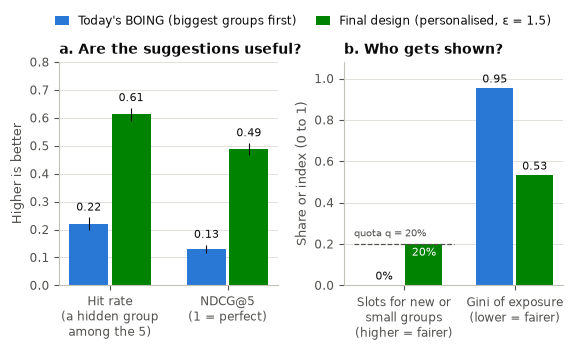

In [26]:
BEFORE_KEY, AFTER_KEY = 'popularity', 'final'
COLOURS = {BEFORE_KEY: br.colour('popularity'), AFTER_KEY: br.colour('reranked')}   # the final design is the proposed design, in its final settings
LABELS = {BEFORE_KEY: "Today's BOING (biggest groups first)", AFTER_KEY: f'Final design (personalised, ε = {FINAL.eps:g})'}
ci = {(k, m_): br.bootstrap_ci(per_user[k][m_]) for k in [BEFORE_KEY, AFTER_KEY] for m_ in ['hit_rate', 'ndcg@5']}
BAR = 0.36

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(br.WIDTH, 2.9), gridspec_kw={'wspace': 0.3})


def pair(ax, cats, fmt, err=None, inside=()):
    # Two bars per category: before (left) and after (right), each value written above its bar (inside it, in white, for the
    # categories in `inside`, where a reference line runs just above the bar)
    x = np.arange(len(cats))
    for i, key in enumerate([BEFORE_KEY, AFTER_KEY]):
        xs = x + (i - 0.5) * BAR
        v = np.array([T(key, c_) for c_ in cats])
        ax.bar(xs, v, BAR * 0.92, color=COLOURS[key], label=LABELS[key], zorder=2)    # 0.92: a thin gap between the bars
        tops = v.copy()
        if err is not None:
            lo, hi = np.array([err(key, c_) for c_ in cats]).T
            ax.vlines(xs, lo, hi, color=br.INK, linewidth=0.8, zorder=3)
            tops = hi
        for xi, ti, vi, c_ in zip(xs, tops, v, cats):
            if c_ in inside and vi > 0.1:
                ax.text(xi, vi - 0.015, fmt(c_, vi), ha='center', va='top', fontsize=8, color='white')
            else:
                ax.text(xi, ti + 0.015, fmt(c_, vi), ha='center', va='bottom', fontsize=8, color=br.INK)
    ax.set_xticks(x)
    ax.grid(axis='y')


pair(ax1, ['hit_rate', 'ndcg@5'], lambda c_, v: f'{v:.2f}', err=lambda k, c_: ci[(k, c_)])
ax1.set_xticklabels(['Hit rate\n(a hidden group\namong the 5)', 'NDCG@5\n(1 = perfect)'])
ax1.set_ylim(0, 0.8)
ax1.set_ylabel('Higher is better')
ax1.set_title('a. Are the suggestions useful?')
pair(ax2, ['newcomer_share', 'gini'], lambda c_, v: f'{100 * v:.0f}%' if c_ == 'newcomer_share' else f'{v:.2f}', inside=['newcomer_share'])
ax2.set_xticklabels(['Slots for new or\nsmall groups\n(higher = fairer)', 'Gini of exposure\n(lower = fairer)'])
ax2.hlines(FINAL.q, -0.45, 0.45, color=br.MUTED, linewidth=0.9, linestyles='dashed', zorder=4)    # the quota, over its own bars only
ax2.text(-0.45, FINAL.q + 0.025, f'quota q = {FINAL.q:.0%}', fontsize=7.5, color=br.MUTED, ha='left', va='bottom')
ax2.set_ylim(0, 1.08)
ax2.set_ylabel('Share or index (0 to 1)')
ax2.set_title('b. Who gets shown?')
handles, labels_ = ax1.get_legend_handles_labels()
fig.legend(handles, labels_, loc='upper center', ncol=2, bbox_to_anchor=(0.5, 1.08), handlelength=1.2, columnspacing=1.6)
br.save_fig(fig, 'final_before_after.png')
plt.show()

## 11 · The test cases for BOING's JavaScript port

`br.make_test_cases(FINAL)` rewrites `testcases/` with the final dials: 13 cases. Cases 01 to 11 use a small world (100 members, 20 groups) and
change one thing each; case 12 is a larger world (300 members, 150 groups) where no rule has to be relaxed; case 13 turns the privacy noise on
there, with the draws given as data (`noise.csv`) so that a port can add exactly the same numbers. Elsewhere the noise is off so every number is
exact; the clipping (m = 3) stays, since a port can redo its hash exactly. Each case is then rerun from its own files (`br.verify_test_cases`),
and `testcases/README.md` says what each case checks, the file format, and how a port passes. (Notebook 10 writes the same cases with notebook
06's settings: run this notebook after it.)

In [27]:
start = time.time()
case_index = br.make_test_cases(FINAL)
verify = br.verify_test_cases()
(br.TESTCASES / 'README.md').write_text(br.test_cases_readme(case_index, FINAL), encoding='utf-8')
cases = case_index.join(verify[['matches_expected', 'same_serve_order']])
print(f'{len(cases)} cases in {(time.time() - start) / 60:.1f} minutes. What each one checks:')
for case, row in cases.iterrows():
    print(f'  {case}: {row.checks}')
cases[['members', 'groups', 'served', 'rows', 'relaxed', 'intent_holds', 'hard_rule_violations', 'matches_expected', 'same_serve_order', 'taste_gap']]

13 cases in 0.6 minutes. What each one checks:
  01_ordinary_member: An ordinary member: user 1 (in Spanish for beginners, Spanish evening chat and Python project club, with public friends) gets 5 suggestions, each with its main true reason from a fixed template (R6).
  02_cold_start_member: Cold start: user 1 is in one group only (Spanish for beginners) and has no friends; they still get 5 suggestions, and every reason that names a group names that one (R6).
  03_brand_new_group: A brand-new group: Spanish for travellers (group 17) was created 2 days ago and has 2 members; in user 1's list it takes the newcomer slot (rank 5, forced), with the reason "A new group: ..." (R4; this case keeps q >= 0.2, c >= 10% and no clipping).
  04_hidden_by_moderators: Hidden by moderators: French evening chat (group 3), user 1's first suggestion when it is visible, is hidden; it must never appear in anyone's list (R8).
  05_blocked_friend: Blocks: user 1 blocked user 6, and user 4 blocked user 1; both

,members,groups,served,rows,relaxed,intent_holds,hard_rule_violations,matches_expected,same_serve_order,taste_gap
case,,,,,,,,,,
01_ordinary_member,100,20,100,500,108,True,0,True,True,0.009813
02_cold_start_member,100,20,100,500,106,True,0,True,True,0.013052
03_brand_new_group,100,20,100,500,0,True,0,True,True,0.016772
04_hidden_by_moderators,100,20,100,500,159,True,0,True,True,0.009813
05_blocked_friend,100,20,100,500,107,True,0,True,True,0.009813
06_private_friend,100,20,100,500,107,True,0,True,True,0.009813
07_not_interested,100,20,100,500,108,True,0,True,True,0.009813
08_accounts_that_do_not_count,108,20,104,520,114,True,0,True,True,0.009813
09_almost_everything_joined,100,20,100,498,102,True,0,True,True,0.019606


## 12 · The final configuration file

`results/final_config.json` holds every setting of the final design, where each was chosen, the checks of section 2, what the privacy guarantee
covers, and the headline test numbers. BOING's port reads its `config`. The reasoning in plain words, dial by dial, is in
`results/final_choices.md`, written for the report's Discussion.

In [28]:
headline = lambda key: {c_: T(key, c_) for c_ in ['hit_rate', 'ndcg@5', 'ndcg@5 low', 'ndcg@5 high', 'ndcg@5 sd', 'newcomer_share',
                                                     'newcomer_share (members who count)',
                                                     'gini', 'coverage', 'topics_per_list', *QUOTA_COLS,
                                                     'lists with 3+ of one hidden topic']}
small_world = case_index[case_index.groups == len(br.CASE_GROUPS)]
n_small, n_disc_small = int(small_world.served.min()), len(br.discover_groups(br.load_visible(br.TESTCASES / small_world.index[0]).groups))
cap_small = max(1, math.floor(FINAL.c * K * n_small + 1e-9))
cap_relaxed = K * n_small - n_disc_small * cap_small     # times the small world's cap must be relaxed per case (as testcases/README.md says)
final_config = {
    'design': 'The final design of the BOING group recommender (ECSE 557, Group 14), notebook 11, after the two reviews of 1 November',
    'config': asdict(FINAL),
    'in BOING': {
        'default for every member (R1)': 'personalisation off: this config with personal = false (same statistics and re-ranking, no profile)',
        'when a member switches personalisation on': 'this config',
        'seed': 'in BOING the clipping hash and the noise must draw from a secret seed; noise_seed here only makes the experiments repeatable',
        'statistics': 'group sizes, pair counts and the AI model are recomputed from the allowed data in one batch job; each release of the '
                      'noisy statistics spends epsilon again (basic composition), so release them rarely (for example once a week) or split '
                      'epsilon across releases',
        'list': '5 suggestions, each with its reason from a fixed template; with the noise on, a "shared members" reason states no count '
                '(the noisy count is often far from the truth); without noise, "About" marks a clipped count'},
    'privacy guarantee': {'covers': scope['covered'], 'odds bound e^eps': math.exp(FINAL.eps), 'does not cover': scope['not covered'],
                          'measured': {k: scope[k] for k in ['sensitivity', 'friends', 'activity', 'shared cap']}},
    'dials': {d: {'value': getattr(FINAL, d), 'what it does': br.CONFIG_MEANING[d], 'chosen in': WHERE[d][0],
                  'file': f'results/{WHERE[d][1]}', 'value chosen there': WHERE[d][2]} for d in WHERE},
    'changed when the dials were combined': {
        'weights': {'from': list(rounds[0]['weights']), 'to': list(CHOSEN['weights']),
                    'why': "notebook 06's protocol, re-run under the final noisy statistics: another mix beat notebook 06's beyond the noise, "
                           "so the choices ran again with it (rounds), until the weights held"},
        'size_share': {'from': e3_rec['size_share'], 'to': FINAL.size_share,
                       'why': "stage 1 of E3's rule (notebook 08's grid), applied on the practice quiz to the design with every other dial on: with "
                              "'small' judged from a member count, the noisy sizes matter less and more of the budget goes to the pair counts"},
        'eps': {'from': e3_rec['eps'], 'to': FINAL.eps,
                'why': "stage 2: the smallest epsilon whose 95% range over five practice quizzes (20 fresh noise draws on each) keeps 90% of the "
                       "accuracy and of the newcomer slots"}},
    'changed after the reviews': {
        'small_from': {'from': BEFORE.small_from, 'to': FINAL.small_from,
                       'why': "first review: the quota held only on the clipped, noisy counts, so 'small' came from the count Discover shows; "
                              "second review: that count includes accounts R9 ignores, so cheap fake accounts could push rival small groups over "
                              "the line and lift another group; now only the accounts R9 counts are counted"},
        'r9_scope': {'from': BEFORE.r9_scope, 'to': FINAL.r9_scope, 'why': 'fake accounts that post and like moved the default list'},
        'eps': {'from': BEFORE.eps, 'to': FINAL.eps,
                'why': 'the first choice rested on a coarse grid and 5 draws, inside the noise; the second (epsilon 1) passed the rule only on '
                       'one practice quiz with the draws that also picked the weights; the rule now runs on five quizzes with fresh draws'},
        'weights': {'from': [BEFORE.alpha, BEFORE.beta, BEFORE.gamma, BEFORE.delta], 'to': list(CHOSEN['weights']),
                    'why': 'notebook 06 chose them without noise; under the final statistics another mix is better'},
        'size_share': {'from': BEFORE.size_share, 'to': FINAL.size_share, 'why': 'stage 1 of the rule, with "small" from a member count'},
        'clusters': {'from': BEFORE.clusters, 'to': FINAL.clusters, 'why': 'chosen on five practice quizzes (member-chosen topics)'},
        'count_under_noise': {'from': BEFORE.count_under_noise, 'to': FINAL.count_under_noise,
                              'why': 'with the noise on, few stated counts were close to the truth (section 3)'}},
    'checks on the practice quiz': {
        "E2's budget: share of the hybrid's NDCG@5 kept without privacy": budget_share,
        "R9's NDCG@5 cost": {'cost': r9_quiz.mean(), 'low': r9_quiz_low, 'high': r9_quiz_high},
        '"small": the recommender\'s own counts, the count Discover shows, the members who count': small_quiz.to_dict('index'),
        'rounds': round_table.to_dict('index'),
        'topic clusters': {'chosen': K_CHOSEN, 'the rule on each quiz alone': last['clusters_each_quiz'],
                           'table': 'results/final_topic_clusters.csv'},
        "E3's rule, re-applied": {'stage 1 (notebook 08 grid, quiz 0, 5 draws)': STAGE1,
                                  'stage 2 (5 quizzes x 20 fresh draws; range over the quizzes)': fine.to_dict('index'),
                                  'chosen': {k_: v_ for k_, v_ in CHOSEN.items() if k_ != 'weights'}, 'bar': KEEP,
                                  'reference ndcg@5': ref['ndcg@5'], 'reference newcomer_share': ref['newcomer_share']},
        'privacy for the recent activity': {'chosen': ACT_CHOSEN, 'table': 'results/final_activity_privacy.csv'},
        "the hybrid's weights under the final statistics": {'chosen mix rank': chosen_rank, 'best mix': list(best_w),
                                                            'best minus chosen': {'mean': gap_mean, 'low': gap_low, 'high': gap_high},
                                                            'keep the chosen mix': bool(KEEP_WEIGHTS)},
    },
    'test (1,406 members)': {ROWS[k]: headline(k) for k in ['popularity', 'hybrid', 'exact', 'final', 'eps05', 'eps2', 'eps5', 'before', 'off']},
    'known issues': [
        'epsilon holds for one release of the group sizes and pair counts; the friends signal, the member counts behind "small", the recent '
        'activity and the shared cap c are outside it (section 8)',
        f"{R('final', 'share naming groups that share nobody'):.0%} of 'shared members' reasons (noise on) name two groups that truly share no "
        f"member ({R('final', 'share naming groups that share nobody, lowest draw'):.0%} to "
        f"{R('final', 'share naming groups that share nobody, highest draw'):.0%} across draws); so the reason states no count",
        f"the topic cap acts on text clusters: {T('final', 'lists with 3+ of one hidden topic'):.0%} of the final lists still hold 3 or more groups "
        "of one hidden topic",
        f"fake accounts that wait 30 days and reach level {FINAL.L} (attacker D) still push a group up, at most to the cap c "
        f"({max(1, math.floor(FINAL.c * K * len(tested) + 1e-9))} of {K * len(tested)} slots), and can push rival small groups over the "
        f"'small' line: {sabotage['final, attacker D: fake accounts']} of them take {sabotage['group']} from "
        f"{sabotage['final, attacker D: lists before']} lists to {sabotage['final, attacker D: lists after']} and lift another group by "
        f"{sabotage['final, attacker D: largest gain of another group']}",
        f"'small' counts only the members who count under R9: by the count Discover shows, "
        f"{T('final', 'lists below the quota (count Discover shows)'):.0f} lists on average hold no group under 10 members",
        'at launch nearly every account is young: with burst_w = 0 there is little to learn from until accounts are 30 days old',
        f'c must stay above 1 / (groups on Discover), or the cap cannot be met: the small test world has only {n_disc_small} groups on '
        f'Discover, so a {FINAL.c:.0%} cap must be relaxed about {cap_relaxed} times per case there, and the quota and topic cap with it '
        f'(testcases/README.md); cases 12 and 13 relax nothing'],
    'files': {'reasoning': 'results/final_choices.md', 'headline table': 'results/final_table.csv', 'every number': 'results/summary.json',
              'test cases': 'testcases/README.md'},
}
(br.RESULTS / 'final_config.json').write_text(json.dumps(jsonable(final_config), indent=2, ensure_ascii=False), encoding='utf-8')
print(json.dumps(jsonable(final_config['config']), indent=1))

{
 "alpha": 0.2,
 "beta": 0.2,
 "gamma": 0.3,
 "delta": 0.3,
 "k": 10,
 "topic_weight": 0.0,
 "personal": true,
 "off_new_w": 0.5,
 "q": 0.2,
 "c": 0.05,
 "n": 2,
 "lam": 0.8,
 "clusters": 8,
 "L": 3,
 "burst_w": 0.0,
 "young_days": 30,
 "eps": 1.5,
 "m": 3,
 "size_share": 0.1,
 "noise_seed": null,
 "seed": 0,
 "small_from": "r9",
 "r9_scope": "all",
 "act_eps": null,
 "count_under_noise": false
}


## 13 · Every number the report quotes, in one place

`results/summary.json` lists every number the final report will quote: a key, the value, and the file (with the row and column, or the path in
the JSON) it comes from. Each value is read back from its results file here, so the summary cannot drift from them. `results/SUMMARY.md` is the
same in readable form, plus every figure with what it shows and a suggested caption.

In [29]:
summary = {}
SLUG = {v['label']: k for k, v in br.METHODS.items()}       # method label -> short key


def put(key, value, source, where=''):
    assert key not in summary, f'duplicate key {key}'
    summary[key] = {'value': jsonable(value), 'source': source if '/' in source else f'results/{source}', 'where': where}


def from_csv(file, prefix, rows=None, cols=None, slug=None, index_col=0):
    t = pd.read_csv(br.RESULTS / file, index_col=index_col)
    for r in (t.index if rows is None else rows):
        for c_ in (t.columns if cols is None else cols):
            if pd.notna(t.loc[r, c_]) and not isinstance(t.loc[r, c_], str):     # an empty cell or a text is not a number to quote
                put(f'{prefix}.{(slug or {}).get(r, r)}.{c_}', t.loc[r, c_], file, f'row "{r}", column "{c_}"')


def from_json(file, prefix, path=(), keys=None, k_label=None):
    # k_label names the plain-number keys (in E4: the number of fake accounts), so that "L = 3 + burst 0" with 10 fakes
    # becomes "L = 3 + burst 0.k=10" and cannot be misread as a burst weight of 0.10
    d = read_json(file)
    for p in path:
        d = d[p]
    for k in (d if keys is None else keys):
        v = d[k]
        name_ = f'{k_label}={k}' if k_label and str(k).isdigit() else k
        if isinstance(v, dict):
            from_json(file, f'{prefix}.{name_}', tuple(path) + (k,), k_label=k_label)
        elif v is not None and not isinstance(v, (str, list)):         # texts and lists are not numbers to quote
            put(f'{prefix}.{name_}', v, file, ' > '.join(map(str, tuple(path) + (k,))))


# The chosen design
for d in WHERE:
    if getattr(FINAL, d) is not None:
        put(f'final.config.{d}', getattr(FINAL, d), 'final_config.json', f'config > {d}')
# T4 to T9
from_csv('t9_validation.csv', 't9.quiz', cols=['ndcg@5'])
from_json('topic_clusters_match.json', 't9.clusters', keys=['purity', 'normalized_mutual_info', 'adjusted_rand_index'])
put('t6.hybrid_quiz.ndcg@5', hyb['ndcg@5'], 'hybrid_validation.csv', 'row 1 (the chosen weights), column "ndcg@5"')
# E1
from_csv('e1_methods.csv', 'e1', slug=SLUG, cols=['hit_rate', 'precision@5', 'recall@5', 'ndcg@5', 'newcomer_share', 'gini', 'coverage',
                                                 'largest_share', 'topics_per_list'])
from_csv('e1_methods_ci.csv', 'e1_ci', slug=SLUG, cols=['hit_rate low', 'hit_rate high', 'ndcg@5 low', 'ndcg@5 high'])
from_json('e1_price_of_fairness.json', 'e1.price_of_fairness')
from_csv('e1_reasons.csv', 'e1.reasons', cols=['Hybrid + fair re-ranking (share)', 'Personalisation off (share)'])
# E2
from_json('e2_recommendation.json', 'e2', keys=['recommended', 'budget', 'tolerance', 'validation', 'test', 'spearman ndcg@5 validation vs test',
                                                'c changes personalised lists (combinations of 60)'])
for dial in ['q', 'c', 'n', 'lam']:
    from_json('e2_recommendation.json', f'e2.dial.{dial}', ('dials (test; each against the recommended setting with only that dial switched off)', dial))
from_csv('e2_table.csv', 'e2.table', cols=['q', 'c', 'n', 'lam', 'ndcg@5', 'hit_rate', 'newcomer_share', 'gini', 'coverage', 'topics_per_list',
                                           'cost', 'cost low', 'cost high', 'relative cost'])
# E3
e3_curve = pd.read_csv(br.RESULTS / 'e3_privacy.csv')
for _, r in e3_curve.iterrows():
    tag = (f'eps{r.eps:g}.m{int(r.m)}' if r.design == 'with privacy noise' else f'clip.m{int(r.m)}' if r.design.startswith('clipping')
           else r.design.split(' (')[0].replace(' ', '_'))
    for c_ in ['ndcg@5', 'ndcg@5 sd', 'newcomer_share', 'hit_rate', 'accuracy kept', 'newcomer slots kept']:
        if pd.notna(r[c_]):
            put(f'e3.curve.{tag}.{c_}', r[c_], 'e3_privacy.csv', f'design "{r.design}", eps {r.eps}, m {r.m}, column "{c_}"')
from_json('e3_recommendation.json', 'e3', keys=['eps', 'm', 'size_share', 'odds_bound_e_to_eps', 'noise_scale_sizes', 'noise_scale_pairs',
                                                'memberships_kept_by_clipping', 'quiz', 'test', 'small_groups_found_by_noisy_sizes'])
from_json('e3_recommendation.json', 'e3.opt_in_25', ('opt_in_25%',))
from_json('e3_recommendation.json', 'e3.reasons', ('reasons',), keys=['test, no privacy', 'test, clipping only', 'test, chosen setting'])
# E4
from_json('e4_recommendation.json', 'e4', keys=['L', 'burst_w', 'young_days', 'cost_no_attack', 'young_network_183_days',
                                                'targets_robustness_median_gain', 'burst_weights_attacker_B_test'], k_label='k')
from_json('e4_recommendation.json', 'e4.target', ('target_group',), keys=['group_id', 'members', 'days_old'])
from_json('e4_recommendation.json', 'e4.test', ('test',), keys=['members_tested', 'bar_top_honest_new_group', 'target_exposure', 'places_per_fake_A'],
          k_label='k')
from_json('e4_recommendation.json', 'e4.quiz', ('practice_quiz',), keys=['ndcg@5_r9_off', 'ndcg@5_chosen', 'ndcg@5_cost'])
from_json('e4_recommendation.json', 'e4.posting', ('activity_attack',), keys=['default_lists_showing_target', 'no_attack_default_lists'], k_label='k')
# E5
from_csv('e5_newcomers.csv', 'e5', slug=SLUG)
from_json('e5_newcomers.json', 'e5.members', ('members',))
from_json('e5_newcomers.json', 'e5.cost_of_reranking', ('cost of re-ranking per kind of member (hybrid minus proposed, NDCG@5)',))
from_csv('e5_r9.csv', 'e5.r9')
# E6
from_json('e6_rules.json', 'e6.fidelity', ('explanation_fidelity',))
for run in read_json('e6_rules.json')['runs']:
    from_json('e6_rules.json', f'e6.runs.{run}', ('runs', run), keys=['members', 'suggestions', 'hard_violations'])
faults = read_json('e6_rules.json')['checker_catches_faults']
put('e6.faults.planted', len(faults), 'e6_rules.json', 'checker_catches_faults (count)')
put('e6.faults.caught', sum(f_['caught'] for f_ in faults.values()), 'e6_rules.json', 'checker_catches_faults > caught (count)')
put('e6.faults.checks_with_a_fault', len({f_['check'] for f_ in faults.values()}), 'e6_rules.json', 'checker_catches_faults > check (distinct)')
from_json('e6_rules.json', 'e6.found_and_fixed', ('found_and_fixed',))
from_json('e6_rules.json', 'e6.test_cases', ('test_cases',), keys=['cases', 'match_expected', 'intent_holds', 'hard_rule_violations'])
put('e6.all_hard_rules_hold', read_json('e6_rules.json')['all_hard_rules_hold'], 'e6_rules.json', 'all_hard_rules_hold')
# The final design (this notebook): the practice quiz
from_csv('final_rounds.csv', 'final.quiz.rounds', cols=['clusters', 'm', 'size_share', 'eps', 'accuracy kept low (eps)', 'rank of the mix',
                                                      'best minus the mix', 'best minus the mix, low', 'best minus the mix, high'])
from_csv('final_topic_clusters.csv', 'final.quiz.clusters', cols=['ndcg@5', "share of the hybrid's NDCG@5", 'lists with 3+ of one chosen topic'])
from_csv('final_validation.csv', 'final.quiz.grid', index_col=[0, 1, 2],
         rows=[(STAGE1['size_share'], e, STAGE1['m']) for e in EPS_GRID], cols=['ndcg@5', 'newcomer_share', 'accuracy kept', 'newcomer slots kept'],
         slug={(STAGE1['size_share'], e, STAGE1['m']): f"eps{e:g}_m{STAGE1['m']}" for e in EPS_GRID})
from_csv('final_eps_fine.csv', 'final.quiz.eps', slug={e: f'eps{e:g}' for e in FINE},
         cols=['ndcg@5', 'accuracy kept', 'accuracy kept low', 'accuracy kept high', 'newcomer slots kept', 'newcomer slots kept low',
               'quizzes passing alone', 'single releases below 90%'] + [f'accuracy kept, quiz {q_}' for q_ in QUIZ_SEEDS])
from_csv('final_activity_privacy.csv', 'final.quiz.activity', cols=['ndcg@5', 'accuracy kept', 'accuracy kept low', 'newcomer slots kept'])
put('final.quiz.budget_share', budget_share, 'final_config.json', "checks on the practice quiz > E2's budget")
put('final.quiz.r9_cost', r9_quiz.mean(), 'final_config.json', "checks on the practice quiz > R9's NDCG@5 cost > cost")
put('final.quiz.weights.chosen_rank', chosen_rank, 'final_weights.csv', 'rank of the chosen mix')
put('final.quiz.weights.best_minus_chosen', gap_mean, 'final_config.json', "checks on the practice quiz > the hybrid's weights > best minus chosen")
# The final design: the test
from_csv('final_table.csv', 'final.test', slug={v: k for k, v in ROWS.items()})
from_json('final_reachable.json', 'final.reachable')
from_csv('final_costs.csv', 'final.cost', cols=['ndcg@5 before', 'ndcg@5 after', 'cost', 'cost low', 'cost high', 'relative cost'],
         slug={s[0]: f'step{i + 1}' for i, s in enumerate(STEPS)})
from_csv('final_reasons.csv', 'final.reasons', slug={v: k for k, v in ROWS.items()},
         cols=['share shared_members', 'share friend', 'share new_group', 'share of reasons true', 'share true, personalised lists',
               'share true, default lists', 'share naming groups that share nobody', 'share naming groups that share nobody, lowest draw',
               'share naming groups that share nobody, highest draw', 'share of stated counts that are close',
               'share of noisy counts that would be close', 'quoted / true count (median)', 'share of "small group" reasons true',
               'share of "small group" reasons true (count Discover shows)'] + QUOTA_COLS)
promo_t = pd.read_csv(br.RESULTS / 'final_promotion.csv')
for _, r_ in promo_t.iterrows():
    for c_ in ['fake accounts', 'statistics unchanged', 'rivals: lists before', 'rivals: lists after', 'top gainer: gain', 'default lists changed']:
        put(f"final.promotion.{r_['rule'].split(' (')[0].replace(' ', '_')}.rivals{r_['rivals']}.{r_['attacker']}.{c_}", r_[c_],
            'final_promotion.csv', f'rule "{r_["rule"]}", rivals {r_["rivals"]}, attacker {r_["attacker"]}, column "{c_}"')
from_csv('final_newcomers.csv', 'final.newcomers', slug={v: k for k, v in ROWS.items()})
for file, prefix, cols_ in [('final_sybil.csv', 'final.sybil', ['target exposure', 'statistics unchanged (test)']),
                            ('final_sybil_posting.csv', 'final.sybil_posting', ['default lists showing the target', 'statistics unchanged (test)'])]:
    sy = pd.read_csv(br.RESULTS / file)
    for _, r in sy.iterrows():
        for c_ in cols_:
            put(f'{prefix}.{r.attacker[0]}.k{r.k}.{c_}', r[c_], file, f'attacker "{r.attacker}", k {r.k}, column "{c_}"')
put('final.sybil.bar', int(pd.read_csv(br.RESULTS / 'final_sybil.csv')['bar (top honest new group)'].iloc[0]), 'final_sybil.csv',
    'column "bar (top honest new group)"')
for run in rule_summary:
    from_json('final_rules.json', f'final.rules.{run}', (run,), keys=['members', 'suggestions', 'hard_violations', 'dial_checks_passed'])
put('final.rules.reasons_checked', reasons_checked, 'final_rules.json', 'sum of fidelity > shown, both runs')
put('final.rules.reasons_faithful', reasons_faithful, 'final_rules.json', 'sum of "faithful to the computed score" > true, both runs')
put('final.rules.reasons_true', reasons_true, 'final_rules.json', 'sum of "true to the raw data" > true, both runs')
put('final.rules.personal_shown', personal_shown, 'final_rules.json', 'sum of "true to the raw data, personalised lists" > shown, both runs')
put('final.rules.personal_true', personal_true, 'final_rules.json', 'sum of "true to the raw data, personalised lists" > true, both runs')
put('final.rules.default_shown', default_shown, 'final_rules.json', 'sum of "true to the raw data, default lists" > shown, both runs')
put('final.rules.default_true', default_true, 'final_rules.json', 'sum of "true to the raw data, default lists" > true, both runs')
from_json('final_privacy_scope.json', 'final.privacy_scope', keys=['sensitivity', 'friends', 'activity', 'shared cap'])
from_json('final_sabotage.json', 'final.sabotage')
ti = pd.read_csv(br.TESTCASES / 'index.csv', index_col=0)
put('final.testcases.cases', len(ti), 'testcases/index.csv', 'rows')
put('final.testcases.intent_holds', int(ti.intent_holds.sum()), 'testcases/index.csv', 'column "intent_holds" (count)')
put('final.testcases.hard_rule_violations', int(ti.hard_rule_violations.sum()), 'testcases/index.csv', 'column "hard_rule_violations" (sum)')

(br.RESULTS / 'summary.json').write_text(json.dumps({'about': 'Every number the final report quotes: key -> value, source file, where in it. '
                                                              'Made by notebook 11 from the results files.',
                                                     'numbers': summary}, indent=1, ensure_ascii=False), encoding='utf-8')
print(f'{len(summary)} numbers from {len({v["source"] for v in summary.values()})} files')

1820 numbers from 35 files


`results/SUMMARY.md`: first the key points of each step in plain words (the numbers the report leans on most), then every number grouped
by step, then every figure with what it shows and a suggested caption (the captions' numbers are read from the summary). If the report's three
drawings are missing, `report/figures.py` is run first. Last, `report/build/fill_docs.py` rebuilds `results/final_choices.md` and
`report/model-card.md` from their templates (`report/build/templates/`) with this run's numbers, and checks that `README.md` quotes them.

In [30]:
S = lambda key: summary[key]['value']
pct = lambda v, d=0: f'{100 * v:.{d}f}%'
FIGURES = {   # file -> (made by, what it shows, a suggested caption)
    'group_sizes.png': ('notebook 01', 'Group sizes in the synthetic community (training data).',
                        'Group sizes in the synthetic community: a few large groups and a long tail of small ones, as on real platforms.'),
    't4_hit_rate.png': ('notebook 03', "How often today's BOING (biggest groups first) puts a hidden group among a member's 5 suggestions, against random suggestions (T4).",
                        f"Today's ranking finds a hidden group for {pct(S('e1.popularity.hit_rate'))} of members, against {pct(S('e1.random.hit_rate'))} for random suggestions."),
    't5_exposure.png': ('notebook 03', "Where today's slots go (times each Discover group is shown) and the Lorenz curve of exposure (T5).",
                        f"Today's ranking shows only {S('e1.popularity.coverage'):.0f} groups and never a new or small one (Gini {S('e1.popularity.gini'):.2f}; random suggestions: {S('e1.random.gini'):.2f})."),
    't7_comparison.png': ('notebook 04', 'NDCG@5 and newcomer share for random, popularity, "also joined" and similar descriptions (first E1 table, T7).',
                          f'"Also joined" is four times as accurate as today\'s ranking (NDCG@5 {S("e1.also_joined.ndcg@5"):.3f} vs {S("e1.popularity.ndcg@5"):.3f}), but almost never shows a new or small group.'),
    't9_tastes.png': ('notebook 05', "For each learned taste of the AI model (both ends), the hidden topics of its 10 top groups (T9).",
                      'The AI model, never told the topics, learns tastes that each pick out a hidden topic: it profiles members by itself.'),
    'e1_methods.png': ('notebook 06', 'NDCG@5 and newcomer share for every method on the test (E1), with the quota q = 20% marked.',
                       f"Every method on the test set: the hybrid is the most accurate (NDCG@5 {S('e1.hybrid.ndcg@5'):.3f}); fair re-ranking raises the newcomer share from {pct(S('e1.hybrid.newcomer_share'), 1)} to {pct(S('e1.reranked.newcomer_share'))} for {S('e1.price_of_fairness.cost'):.3f} NDCG@5."),
    'e2_tradeoff.png': ('notebook 07', 'NDCG@5 against newcomer share for the 180 re-ranker settings, the Pareto front and the recommended setting (E2, test).',
                        f"What fair exposure costs: each extra newcomer slot costs more accuracy. The recommended setting (q = 20%, c = 5%, n = 2, λ = 0.8) costs {S('e2.test.cost vs hybrid'):.3f} NDCG@5 against the hybrid."),
    'e2_diversity.png': ('notebook 07', 'NDCG@5 and topics per list against the variety weight λ, for each topic cap n (E2, test).',
                         f"Variety is nearly free down to λ = 0.8: topics per list rise from {S('e2.dial.lam.topics_per_list off'):.2f} to {S('e2.dial.lam.topics_per_list on'):.2f} for {S('e2.dial.lam.cost'):.3f} NDCG@5."),
    'e3_privacy.png': ('notebook 08', 'NDCG@5 and newcomer share against the privacy budget ε, for caps m = 3, 5, 8 (E3, test, notebook 06\'s design).',
                       f"The privacy-utility curve: below ε = 1 noisy statistics do worse than none; m = 3 is the best cap at every ε. (The final design, with every rule on, uses ε = {FINAL.eps:g}: notebook 11.)"),
    'e4_sybil.png': ('notebook 09', 'Members shown the target group against the number of fake accounts, for four attackers and six R9 settings (E4, test).',
                     f"With R9 off, 100 fake accounts push a new group into {S('e4.test.target_exposure.fresh.R9 off.k=100')} of 1,406 lists; with L = 3 and a 30-day wait, attackers A to C gain nothing, while accounts that wait a month and level up (D) still do."),
    'e5_newcomers.png': ('notebook 10', 'NDCG@5 by kind of member, and how often new and older small groups are shown and found (E5).',
                         f"New members get far better suggestions than today's ranking at every level of history; the fair re-ranking gives new groups {pct(S('e5.reranked.share new groups'), 1)} and older small groups {pct(S('e5.reranked.share older small groups'), 1)} of the slots."),
    'final_before_after.png': ('notebook 11', "Hit rate and NDCG@5 (left), newcomer share and Gini of exposure (right): today's BOING against the final design (test).",
                               f"Before and after on the test set: the final design (ε = {FINAL.eps:g}) finds a hidden group for {pct(S('final.test.final.hit_rate'))} of members (today {pct(S('final.test.popularity.hit_rate'))}) and gives {pct(S('final.test.final.newcomer_share'))} of the slots to new or small groups (today {pct(S('final.test.popularity.newcomer_share'))}); its Gini of exposure falls from {S('final.test.popularity.gini'):.2f} to {S('final.test.final.gini'):.2f}. Dashed: the 20% quota, met by the members who count."),
    'values_hierarchy.png': ('report/figures.py', 'The values hierarchy: values, norms, design rules (report Figure 1; no data).',
                             'Values hierarchy of the recommender (after van de Poel, 2013): each value is specified as norms, and each norm becomes a testable design rule.'),
    'pipeline.png': ('report/figures.py', 'How a suggestion is made, and the rule each step enforces (report Figure 2; no data).',
                     'How a suggestion is made, and the rules each step enforces. Only the scoring step is learned.'),
    'groups_screen_sketch.png': ('report/figures.py', 'Sketch of the new Groups page for user 1 (report Figure 3).',
                                 "Sketch of the new Groups page: the default list (left) and the personalised list with reasons (right)."),
}
missing = [f for f in FIGURES if not (br.FIGS / f).exists()]
if any(FIGURES[f][0] == 'report/figures.py' for f in missing):           # the report's drawings: no data, made by a script
    subprocess.run([sys.executable, str(br.ROOT / 'report' / 'figures.py')], check=True, cwd=str(br.ROOT))
    missing = [f for f in FIGURES if not (br.FIGS / f).exists()]
if missing:
    print('Figures not found (run the notebook named for each, then this cell again):', missing)


def show(v):
    if isinstance(v, bool):
        return 'yes' if v else 'no'
    if isinstance(v, float):
        return f'{v:.4g}'
    return str(v)


SECTIONS = [('final.config', 'The final design: every dial'),
            ('final.', 'The final design (notebook 11): the checks on the practice quiz, then the test'), ('t', 'Steps T4 to T9'),
            ('e1', 'E1: which method works best'), ('e2', 'E2: what fair exposure and variety cost'), ('e3', 'E3: what privacy costs'),
            ('e4', 'E4: fake accounts'), ('e5', 'E5: new members and new groups'), ('e6', 'E6: do the hard rules hold')]
lines = ['# Summary of results', '',
         'Every number the final report quotes, with the file it comes from (made by notebook 11 from `results/`; the same numbers are in '
         '`results/summary.json`). Synthetic community only: 2,000 fake members and 150 groups; the test set is 1,406 members.', '',
         f'The final design: `br.FINAL_CONFIG` = {", ".join(f"{d} = {show(getattr(FINAL, d))}" for d in WHERE)}. '
         'Personalisation is off by default (R1). The reasoning for each dial is in `results/final_choices.md`.', '',
         f'**What the privacy guarantee covers:** {scope["covered"]}. **Not covered:** ' + '; '.join(scope['not covered']) + '.', '']
fine_key = lambda e, col: f'final.quiz.eps.eps{e:g}.{col}'
KEY_POINTS = {   # section -> [(what, in plain words; key in summary.json)]: the numbers the report leans on most
'The final design (test, 1,406 members; rows with noise: mean of 10 draws)': [
    ("Hit rate, today's BOING (test)", 'final.test.popularity.hit_rate'),
    ('Hit rate, final design', 'final.test.final.hit_rate'),
    ("NDCG@5, today's BOING", 'final.test.popularity.ndcg@5'),
    ('NDCG@5, final design (mean of 10 noise draws)', 'final.test.final.ndcg@5'),
    ('NDCG@5, final design, 95% range (low)', 'final.test.final.ndcg@5 low'),
    ('NDCG@5, final design, 95% range (high)', 'final.test.final.ndcg@5 high'),
    ('NDCG@5, the hybrid without any rule', 'final.test.hybrid.ndcg@5'),
    ('NDCG@5, the final design before the review (epsilon 5)', 'final.test.before.ndcg@5'),
    ("Share of slots for new or small groups, today's BOING", 'final.test.popularity.newcomer_share'),
    ('Share of slots for new or small groups, final design (count Discover shows)', 'final.test.final.newcomer_share'),
    ('Share of slots for new or small groups, final design (members who count)', 'final.test.final.newcomer_share (members who count)'),
    ('Share of slots for new or small groups, before the review', 'final.test.before.newcomer_share'),
    ('Lists with no new or small group, final design, by the members who count (of 1,406)',
     'final.test.final.lists below the quota (members who count)'),
    ('The same, by the count Discover shows (mean of 10 draws)', 'final.test.final.lists below the quota (count Discover shows)'),
    ('Lists with no new or small group (count Discover shows), before the first review',
     'final.test.before.lists below the quota (count Discover shows)'),
    ("Gini of exposure, today's BOING", 'final.test.popularity.gini'),
    ('Gini of exposure, final design', 'final.test.final.gini'),
    ('Lists with 3+ groups of one hidden topic, final design', 'final.test.final.lists with 3+ of one hidden topic'),
    ('Cost of fair exposure and variety (NDCG@5)', 'final.cost.step2.cost'),
    ('Cost of judging "small" from the count Discover shows, with the final clusters (NDCG@5)', 'final.cost.step3.cost'),
    ('Cost of the final weights without noise (NDCG@5)', 'final.cost.step4.cost'),
    ('Cost of fake-account resistance (NDCG@5)', 'final.cost.step5.cost'),
    (f'Cost of privacy, epsilon = {FINAL.eps:g} (NDCG@5)', 'final.cost.step6.cost'),
    ('Cost of every rule together (NDCG@5)', 'final.cost.step7.cost'),
    (f'Practice quizzes, epsilon = {FINAL.eps:g}: accuracy kept (5 quizzes x 20 fresh draws)', fine_key(FINAL.eps, 'accuracy kept')),
    (f'Practice quizzes, epsilon = {FINAL.eps:g}: accuracy kept, 95% range over the quizzes (low)', fine_key(FINAL.eps, 'accuracy kept low')),
    (f'Practice quizzes, epsilon = {FINAL.eps:g}: single releases keeping less than 90%', fine_key(FINAL.eps, 'single releases below 90%')),
    (f'Practice quizzes, epsilon = {max(e for e in FINE if e < FINAL.eps):g}: accuracy kept', fine_key(max(e for e in FINE if e < FINAL.eps), 'accuracy kept')),
    (f'Practice quizzes, epsilon = {max(e for e in FINE if e < FINAL.eps):g}: accuracy kept, 95% range (high)',
     fine_key(max(e for e in FINE if e < FINAL.eps), 'accuracy kept high')),
    (f'Practice quizzes, epsilon = {max(e for e in FINE if e < FINAL.eps):g}: quizzes where the first version\'s rule passes (of 5)',
     fine_key(max(e for e in FINE if e < FINAL.eps), 'quizzes passing alone')),
    (f'Practice quizzes, epsilon = {max(e for e in FINE if e < FINAL.eps):g}: single releases keeping less than 90%',
     fine_key(max(e for e in FINE if e < FINAL.eps), 'single releases below 90%')),
    ("Round 1 (notebook 06's weights): epsilon chosen", 'final.quiz.rounds.1.eps'),
    ("Round 1: how much the best mix beats notebook 06's (NDCG@5, under noise)", 'final.quiz.rounds.1.best minus the mix'),
    ('NDCG@5, final design without privacy', 'final.test.exact.ndcg@5'),
    ('NDCG@5, the final design at epsilon = 2', 'final.test.eps2.ndcg@5'),
    ('Default list (personalisation off): NDCG@5', 'final.test.off.ndcg@5'),
    ('Reasons checked (both lists, all members)', 'final.rules.reasons_checked'),
    ('Reasons faithful to the computed score', 'final.rules.reasons_faithful'),
    ('Reasons on personalised lists (both runs)', 'final.rules.personal_shown'),
    ('Of them, true to the raw data', 'final.rules.personal_true'),
    ('Reasons on default lists (both runs)', 'final.rules.default_shown'),
    ('Of them, true to the raw data', 'final.rules.default_true'),
    ('"Shared members" reasons naming groups that share nobody, final design (mean of 10 draws)', 'final.reasons.final.share naming groups that share nobody'),
    ('The same, lowest draw', 'final.reasons.final.share naming groups that share nobody, lowest draw'),
    ('The same, highest draw', 'final.reasons.final.share naming groups that share nobody, highest draw'),
    ('Noisy counts that would be close to the truth if stated (final design)', 'final.reasons.final.share of noisy counts that would be close'),
    ('Hard-rule violations, final design (all members)', 'final.rules.Final design, all members.hard_violations'),
    ('Shared cap: other members whose list changed when one member left, mean of 30 trials', 'final.privacy_scope.shared cap.other members whose list changed (default + personalised), mean'),
    ('Lists showing the target with 100 patient fake accounts (D)', 'final.sybil.D.k100.target exposure'),
    ('First fix ("small" from the count Discover shows): lists another group gains when new accounts (A) push one rival over the line',
     'final.sabotage.first fix, attacker A: largest gain of another group'),
    ('Final: new or low-level accounts (A to C) pushing rivals change no statistic', 'final.sabotage.final, attackers A to C: statistics unchanged'),
    ('Final: lists another group gains when patient accounts (D) push one rival over the line',
     'final.sabotage.final, attacker D: largest gain of another group'),
    ('Default lists showing an old group pushed by 100 posting fakes (B: young, levelled up)', 'final.sybil_posting.B.k100.default lists showing the target'),
    ('Best possible hit rate (hidden groups out of reach of any method)', 'final.reachable.best possible hit rate'),
    ('Test cases for the port, all matching', 'final.testcases.cases'),
],
'E1: which method works best (test, notebook 06)': [
    ('NDCG@5, random suggestions', 'e1.random.ndcg@5'),
    ("NDCG@5, today's BOING (biggest groups first)", 'e1.popularity.ndcg@5'),
    ('NDCG@5, "also joined"', 'e1.also_joined.ndcg@5'),
    ('NDCG@5, similar descriptions', 'e1.descriptions.ndcg@5'),
    ('NDCG@5, the AI model (hidden tastes)', 'e1.hidden_tastes.ndcg@5'),
    ('NDCG@5, the hybrid', 'e1.hybrid.ndcg@5'),
    ('NDCG@5, hybrid + fair re-ranking (notebook 06 dials)', 'e1.reranked.ndcg@5'),
    ('Share of slots for new or small groups, the hybrid', 'e1.hybrid.newcomer_share'),
    ('Share of slots for new or small groups, hybrid + fair re-ranking', 'e1.reranked.newcomer_share'),
    ('Price of fairness: NDCG@5 the re-ranking costs', 'e1.price_of_fairness.cost'),
    ('Price of fairness, 95% range (low)', 'e1.price_of_fairness.cost low'),
    ('Price of fairness, 95% range (high)', 'e1.price_of_fairness.cost high'),
    ('NDCG@5, personalisation off', 'e1.off.ndcg@5'),
],
'E2: what fair exposure and variety cost (notebook 07)': [
    ('Chosen q: share of each list for new or small groups', 'e2.recommended.q'),
    ('Chosen c: most slots one group may take (share of all)', 'e2.recommended.c'),
    ('Chosen n: groups of one topic cluster per list', 'e2.recommended.n'),
    ('Chosen λ: variety weight (1 = no variety term)', 'e2.recommended.lam'),
    ("Practice quiz: share of the hybrid's NDCG@5 kept (budget 95%)", 'e2.validation.share of the hybrid'),
    ('Test NDCG@5 with the chosen dials', 'e2.test.ndcg@5'),
    ('Test share of slots for new or small groups', 'e2.test.newcomer_share'),
    ('Cost against the hybrid (NDCG@5)', 'e2.test.cost vs hybrid'),
    ('Cost of the quota q alone (NDCG@5)', 'e2.dial.q.cost'),
    ('Cost of the topic cap n alone (NDCG@5)', 'e2.dial.n.cost'),
    ('Cost of variety λ alone (NDCG@5)', 'e2.dial.lam.cost'),
    ('Topics per list without variety (λ = 1)', 'e2.dial.lam.topics_per_list off'),
    ('Topics per list with λ = 0.8', 'e2.dial.lam.topics_per_list on'),
    ('NDCG@5 with a second newcomer slot (q = 40%)', 'e2.table.More quota (q = 40%).ndcg@5'),
    ('Default list: groups shown without the cap c', 'e2.dial.c.coverage off'),
    ('Default list: groups shown with c = 5%', 'e2.dial.c.coverage on'),
    ('Default list: most-shown group\'s share of slots, no cap', 'e2.dial.c.largest_share off'),
    ('Default list: most-shown group\'s share of slots, c = 5%', 'e2.dial.c.largest_share on'),
    ('Rank correlation of NDCG@5, practice quiz vs test (180 settings)', 'e2.spearman ndcg@5 validation vs test'),
],
"E3: what privacy costs (test, notebook 06's design, m = 3; noise rows: mean of 10 draws)": [
    ('NDCG@5, no privacy', 'e3.curve.no_privacy.ndcg@5'),
    ('NDCG@5, ε = 0.1', 'e3.curve.eps0.1.m3.ndcg@5'),
    ('NDCG@5, ε = 0.5', 'e3.curve.eps0.5.m3.ndcg@5'),
    ('NDCG@5, ε = 1', 'e3.curve.eps1.m3.ndcg@5'),
    ('NDCG@5, ε = 2', 'e3.curve.eps2.m3.ndcg@5'),
    ('NDCG@5, ε = 5', 'e3.curve.eps5.m3.ndcg@5'),
    ('NDCG@5, clipping only (ε = ∞)', 'e3.curve.clip.m3.ndcg@5'),
    ('NDCG@5, no statistics about other members at all', 'e3.curve.no_statistics_about_others.ndcg@5'),
    ("E3's choice for notebook 06's design: ε", 'e3.eps'),
    ("E3's choice: m (groups each member counts for)", 'e3.m'),
    ('Share of memberships kept by clipping to 3 groups', 'e3.memberships_kept_by_clipping'),
    ('Test cost of ε = 2 (NDCG@5)', 'e3.test.cost'),
    ('"Shared members" reasons naming groups that share nobody, ε = 2', 'e3.reasons.test, chosen setting.shares nobody'),
    ('25% opt in, ε = 2: NDCG@5 of those who opt in when everyone counts', 'e3.opt_in_25.everyone counts, epsilon = 2, m = 3.ndcg@5 (opted in)'),
    ('25% opt in, ε = 2: the same when only opted-in members count', 'e3.opt_in_25.only opted-in members count, epsilon = 2, m = 3.ndcg@5 (opted in)'),
],
"E4: fake accounts (test, notebook 06's other dials; k = number of fake accounts)": [
    ('Lists showing the target, no attack, R9 off', 'e4.test.target_exposure.fresh.R9 off.k=0'),
    ('Lists showing the target, 100 fakes, R9 off', 'e4.test.target_exposure.fresh.R9 off.k=100'),
    ('Lists showing the target, 200 fakes, R9 off', 'e4.test.target_exposure.fresh.R9 off.k=200'),
    ('Lists showing the target, 100 new or low-level fakes (A), L = 3 and a 30-day wait', 'e4.test.target_exposure.fresh.L = 3 + burst 0.k=100'),
    ('Lists showing the target, 100 patient fakes (D), L = 3 and a 30-day wait', 'e4.test.target_exposure.both.L = 3 + burst 0.k=100'),
    ('Bar: lists showing the most-shown honest new group', 'e4.test.bar_top_honest_new_group'),
    ('Places gained per fake account (A, 10 fakes, R9 off)', 'e4.test.places_per_fake_A.R9 off.k=10'),
    ('Median lists gained by the 21 small new groups as targets, R9 off', 'e4.targets_robustness_median_gain.R9 off'),
    ('The same, L = 3 and a 30-day wait', 'e4.targets_robustness_median_gain.L = 3 + burst 0'),
    ('Default lists showing an old group, 20 posting fakes (B), R9 on joins only', 'e4.posting.default_lists_showing_target.L = 3 + burst 0, joins only.levelled.k=20'),
    ('The same, R9 on joins, posts, likes and friends', 'e4.posting.default_lists_showing_target.L = 3 + burst 0, joins, posts, likes and friends.levelled.k=20'),
    ('NDCG@5 with no attack, R9 off', 'e4.cost_no_attack.ndcg@5_tested_r9_off'),
    ('NDCG@5 with no attack, L = 3 and a 30-day wait', 'e4.cost_no_attack.ndcg@5_tested_chosen'),
    ('Honest memberships that wait 30 days before they count', 'e4.cost_no_attack.honest_memberships_turned_down'),
    ('Honest memberships in all', 'e4.cost_no_attack.honest_memberships'),
],
"E5: new members and new groups (notebook 06's design)": [
    ('NDCG@5, proposed design, members with 3 or more groups (test)', 'e5.reranked.ndcg@5 3+ groups (test)'),
    ('NDCG@5, proposed design, members with 2 groups (test)', 'e5.reranked.ndcg@5 2 groups (test)'),
    ('NDCG@5, proposed design, members with 1 group (newcomer quiz)', 'e5.reranked.ndcg@5 1 group (quiz)'),
    ('NDCG@5, proposed design, members with no group yet (newcomer quiz)', 'e5.reranked.ndcg@5 no group yet (quiz)'),
    ('NDCG@5, proposed design, new members (newcomer quiz)', 'e5.reranked.ndcg@5 new members (quiz)'),
    ("NDCG@5, today's BOING, new members (newcomer quiz)", 'e5.popularity.ndcg@5 new members (quiz)'),
    ('Cost of the re-ranking for members with 1 group (NDCG@5)', 'e5.cost_of_reranking.1 group.cost'),
    ('The same, relative', 'e5.cost_of_reranking.1 group.relative cost'),
    ('Share of slots for new groups, proposed design', 'e5.reranked.share new groups'),
    ('Share of slots for older small groups, proposed design', 'e5.reranked.share older small groups'),
    ('Hidden memberships in new or small groups found, proposed design (of 42)', 'e5.reranked.found in new or small groups'),
    ('The same, the hybrid', 'e5.hybrid.found in new or small groups'),
],
'E6: do the hard rules hold (notebook 10)': [
    ('Hard-rule violations, proposed design, all members', 'e6.runs.Proposed design, all members.hard_violations'),
    ('Hard-rule violations, personalisation off, all members', 'e6.runs.Personalisation off, all members.hard_violations'),
    ('Reasons checked', 'e6.fidelity.reasons'),
    ('Reasons faithful to the computed score', 'e6.fidelity.true'),
    ('Faults planted on purpose', 'e6.faults.planted'),
    ('Faults caught', 'e6.faults.caught'),
    ('Checks with a planted fault of their own (of 20)', 'e6.faults.checks_with_a_fault'),
    ('Wrong reasons the checker found before the fix (young accounts down-weighted)', 'e6.found_and_fixed.wrong reasons before the fix'),
    ('Test cases matching their answers', 'e6.test_cases.match_expected'),
],
}
missing_keys = [key for rows in KEY_POINTS.values() for _, key in rows if key not in summary]
assert not missing_keys, f'key points not in summary.json: {missing_keys}'
lines += ['Contents: the key points by step (below), then every number by step, then every figure with a suggested caption.', '']
for title, rows in KEY_POINTS.items():
    lines += [f'## Key points: {title}', '', '| What | Value | Key in summary.json |', '|---|---|---|']
    lines += [f'| {what} | {show(S(key))} | `{key}` |' for what, key in rows]
    lines.append('')
SECTIONS = [(prefix, f'Every number: {title}') for prefix, title in SECTIONS]
done = set()
for prefix, title in SECTIONS:
    keys = [k for k in summary if k.startswith(prefix) and k not in done]
    if not keys:
        continue
    lines += [f'## {title}', '', '| Key | Value | Source |', '|---|---|---|']
    for k in keys:
        lines.append(f"| `{k}` | {show(summary[k]['value'])} | `{summary[k]['source']}`: {summary[k]['where']} |")
        done.add(k)
    lines.append('')
assert done == set(summary), 'a number is in no section'
lines += ['## Figures', '', 'All in `figures/`, 200 dpi PNG, 6.5 in wide. The same colour means the same method in every figure.', '',
          '| File | Made by | What it shows | Suggested caption |', '|---|---|---|---|']
lines += [f'| `{f}` | {by} | {what} | {cap} |' for f, (by, what, cap) in FIGURES.items()]
(br.RESULTS / 'SUMMARY.md').write_text('\n'.join(lines) + '\n', encoding='utf-8')
print(f'SUMMARY.md: {len(summary)} numbers in {len(SECTIONS)} sections, {len(FIGURES)} figures')
# The two documents written for the report (results/final_choices.md and report/model-card.md), rebuilt from this run's results by
# report/build/fill_docs.py: no number in them is typed by hand. It also checks that README.md quotes this run's headline numbers.
docs_run = subprocess.run([sys.executable, str(br.ROOT / 'report' / 'build' / 'fill_docs.py')], cwd=str(br.ROOT), capture_output=True,
                          text=True, encoding='utf-8')
print(docs_run.stdout.strip(), docs_run.stderr.strip()[-3000:])

SUMMARY.md: 1820 numbers in 9 sections, 15 figures


wrote results\final_choices.md
wrote report\model-card.md
README.md quotes this run's headline numbers. 


## 14 · Checks

In [31]:
TEXT = {
 "eps_chosen": "1.5",
 "odds_chosen": "4.5",
 "clusters_chosen": "8",
 "clusters_each": "15, none, 10, 25, 5",
 "pile_chosen": "58%",
 "pile_15": "55%",
 "budget_15": "94.9%",
 "stage1_share": "10%",
 "epsc_acc": "92.8%",
 "epsc_acc_lo": "91.9%",
 "epsc_acc_hi": "93.8%",
 "epsc_new": "103%",
 "epsc_single": "8%",
 "eps_below": "1",
 "eps_below_acc": "89.7%",
 "eps_below_lo": "88.7%",
 "eps_below_hi": "90.7%",
 "eps_below_alone": "0",
 "eps_below_single": "59%",
 "r1_eps": "2",
 "r1_clusters": "8",
 "w_best": "0.2, 0.2, 0.3, 0.3",
 "w_gap": "0.0121",
 "w_gap_lo": "0.0062",
 "w_gap_hi": "0.0180",
 "pop_hit": "22%",
 "pop_ndcg": "0.131",
 "pop_gini": "0.95",
 "final_hit": "61%",
 "final_ndcg": "0.488",
 "final_sd": "0.008",
 "final_newc": "19.9%",
 "final_newc_r9": "20.8%",
 "final_gini": "0.53",
 "final_cov": "127",
 "exact_ndcg": "0.515",
 "eps05_ndcg": "0.436",
 "eps2_ndcg": "0.493",
 "eps5_ndcg": "0.497",
 "before_ndcg": "0.510",
 "cost_weights": "0.0020",
 "hybrid_ndcg": "0.541",
 "before_below": "470",
 "before_newc": "15.8%",
 "final_below": "0",
 "final_below_shown": "55",
 "hidden_pile_final": "47%",
 "hidden_pile_hybrid": "67%",
 "hidden_pile_exact": "68%",
 "cost_rerank": "0.015",
 "cost_public": "0.0048",
 "cost_r9": "0.0043",
 "cost_r9_low": "-0.0026",
 "cost_r9_high": "0.0116",
 "cost_r10": "0.026",
 "cost_all": "0.053",
 "cost_all_rel": "9.7%",
 "act_best_kept": "54%",
 "cap_leak_mean": "0.2",
 "cap_leak_max": "5",
 "reasons_checked": "19,830",
 "true_personal": "97.3%",
 "true_default": "100%",
 "shared_false_final": "41%",
 "shared_false_eps5": "19%",
 "shared_false_lo": "31%",
 "shared_false_hi": "52%",
 "would_close": "29%",
 "before_close": "38%",
 "clip_close": "43%",
 "small_true_shown": "94%",
 "one_group": "0.398",
 "no_group": "0.340",
 "new_members": "0.343",
 "found_nc": "12.5",
 "share_new_final": "7.2%",
 "share_small_final": "12.7%",
 "off_ndcg": "0.058",
 "off_newc": "44%",
 "cap_slots": "351",
 "members_all": "1,983",
 "faults": "26",
 "sab_group": "Violin club",
 "sab_fakes": "9",
 "sab_before_first": "130",
 "sab_after_first": "15",
 "promo_first_gain": "11",
 "sab_fakes_d": "9",
 "sab_before_final": "126",
 "sab_after_d": "17",
 "promo_d_gain": "9",
 "promo_d4_fakes": "24",
 "promo_d4_lost": "315",
 "promo_d4_gain": "40",
 "default_changed": "0"
}

f2, f3, f4 = (lambda v: f'{v:.2f}'), (lambda v: f'{v:.3f}'), (lambda v: f'{v:.4f}')
p0, p1, p2 = (lambda v: f'{100 * v:.0f}%'), (lambda v: f'{100 * v:.1f}%'), (lambda v: f'{100 * v:.2f}%')
CT = lambda name_: next(i for i, s in enumerate(STEPS) if s[0].startswith(name_))         # a step of the cost table, by the start of its name
E_BELOW, E_NEXT = max(e for e in FINE if e < FINAL.eps), min(e for e in FINE if e > FINAL.eps)   # the epsilons tried next to the chosen one
NOW = {   # each number of TEXT, recomputed from this run
    'eps_chosen': f'{FINAL.eps:g}', 'odds_chosen': f'{math.exp(FINAL.eps):.1f}', 'clusters_chosen': str(FINAL.clusters),
    'clusters_each': ', '.join(str(last['clusters_each_quiz'][q_] or 'none') for q_ in QUIZ_SEEDS),
    'pile_chosen': p0(cluster_table.loc[str(FINAL.clusters), 'lists with 3+ of one chosen topic']),
    'pile_15': p0(cluster_table.loc['15', 'lists with 3+ of one chosen topic']),
    'budget_15': p1(cluster_table.loc['15', "share of the hybrid's NDCG@5"]),
    'stage1_share': p0(STAGE1['size_share']),
    'epsc_acc': p1(F(FINAL.eps, 'accuracy kept')), 'epsc_acc_lo': p1(F(FINAL.eps, 'accuracy kept low')),
    'epsc_acc_hi': p1(F(FINAL.eps, 'accuracy kept high')), 'epsc_new': p0(F(FINAL.eps, 'newcomer slots kept')),
    'epsc_single': p0(F(FINAL.eps, 'single releases below 90%')),
    'eps_below': f'{E_BELOW:g}', 'eps_below_acc': p1(F(E_BELOW, 'accuracy kept')), 'eps_below_lo': p1(F(E_BELOW, 'accuracy kept low')),
    'eps_below_hi': p1(F(E_BELOW, 'accuracy kept high')), 'eps_below_alone': str(int(F(E_BELOW, 'quizzes passing alone'))),
    'eps_below_single': p0(F(E_BELOW, 'single releases below 90%')),
    'r1_eps': f"{rounds[0]['eps']:g}", 'r1_clusters': str(rounds[0]['clusters']), 'w_best': ', '.join(f'{x:g}' for x in rounds[0]['best']),
    'w_gap': f4(rounds[0]['gap'][0]), 'w_gap_lo': f4(rounds[0]['gap'][1]), 'w_gap_hi': f4(rounds[0]['gap'][2]),
    'pop_hit': p0(T('popularity', 'hit_rate')), 'pop_ndcg': f3(T('popularity', 'ndcg@5')), 'pop_gini': f2(T('popularity', 'gini')),
    'final_hit': p0(T('final', 'hit_rate')), 'final_ndcg': f3(T('final', 'ndcg@5')), 'final_sd': f3(T('final', 'ndcg@5 sd')),
    'final_newc': p1(T('final', 'newcomer_share')), 'final_newc_r9': p1(T('final', 'newcomer_share (members who count)')),
    'final_gini': f2(T('final', 'gini')), 'final_cov': f'{T("final", "coverage"):.0f}',
    'exact_ndcg': f3(T('exact', 'ndcg@5')), 'eps05_ndcg': f3(T('eps05', 'ndcg@5')), 'eps2_ndcg': f3(T('eps2', 'ndcg@5')),
    'eps5_ndcg': f3(T('eps5', 'ndcg@5')), 'before_ndcg': f3(T('before', 'ndcg@5')), 'cost_weights': f4(C(CT('The weights'))),
    'hybrid_ndcg': f3(T('hybrid', 'ndcg@5')),
    'before_below': f"{T('before', 'lists below the quota (count Discover shows)'):.0f}", 'before_newc': p1(T('before', 'newcomer_share')),
    'final_below': f"{T('final', 'lists below the quota (members who count)'):.0f}",
    'final_below_shown': f"{T('final', 'lists below the quota (count Discover shows)'):.0f}",
    'hidden_pile_final': p0(T('final', 'lists with 3+ of one hidden topic')), 'hidden_pile_hybrid': p0(T('hybrid', 'lists with 3+ of one hidden topic')),
    'hidden_pile_exact': p0(T('exact', 'lists with 3+ of one hidden topic')),
    'cost_rerank': f3(C(CT('Fair exposure'))), 'cost_public': f4(C(CT('"Small"'))),
    'cost_r9': f4(C(CT('Fake-account'))), 'cost_r9_low': f4(C(CT('Fake-account'), 'cost low')), 'cost_r9_high': f4(C(CT('Fake-account'), 'cost high')),
    'cost_r10': f3(C(CT('Privacy'))), 'cost_all': f3(C(CT('Every rule'))), 'cost_all_rel': p1(C(CT('Every rule'), 'relative cost')),
    'act_best_kept': p0(act_table['accuracy kept'].iloc[1:].max()),
    'cap_leak_mean': f"{scope['shared cap']['other members whose list changed (default + personalised), mean']:.1f}",
    'cap_leak_max': str(scope['shared cap']['the same, most in one trial']),
    'reasons_checked': f'{reasons_checked:,}', 'true_personal': p1(personal_true / personal_shown), 'true_default': p0(default_true / default_shown),
    'shared_false_final': p0(R('final', 'share naming groups that share nobody')), 'shared_false_eps5': p0(R('eps5', 'share naming groups that share nobody')),
    'shared_false_lo': p0(R('final', 'share naming groups that share nobody, lowest draw')),
    'shared_false_hi': p0(R('final', 'share naming groups that share nobody, highest draw')),
    'would_close': p0(R('final', 'share of noisy counts that would be close')), 'before_close': p0(R('before', 'share of stated counts that are close')),
    'clip_close': p0(R('clip', 'share of stated counts that are close')),
    'small_true_shown': p0(R('final', 'share of "small group" reasons true (count Discover shows)')),
    'one_group': f3(N('final', 'ndcg@5 1 group (quiz)')), 'no_group': f3(N('final', 'ndcg@5 no group yet (quiz)')),
    'new_members': f3(N('final', 'ndcg@5 new members (quiz)')), 'found_nc': f'{N("final", "found in new or small groups"):.1f}',
    'share_new_final': p1(N('final', 'share new groups')), 'share_small_final': p1(N('final', 'share older small groups')),
    'off_ndcg': f3(T('off', 'ndcg@5')), 'off_newc': p0(T('off', 'newcomer_share')),
    'cap_slots': str(max(1, math.floor(FINAL.c * K * len(tested) + 1e-9))), 'members_all': f'{len(everyone):,}',
    'faults': str(S('e6.faults.planted')),
    'sab_group': sabotage['group'], 'sab_fakes': str(sabotage['first fix, attacker A: fake accounts']),
    'sab_before_first': str(sabotage['first fix, attacker A: lists before']), 'sab_after_first': str(sabotage['first fix, attacker A: lists after']),
    'promo_first_gain': str(sabotage['first fix, attacker A: largest gain of another group']),
    'sab_fakes_d': str(sabotage['final, attacker D: fake accounts']), 'sab_before_final': str(sabotage['final, attacker D: lists before']),
    'sab_after_d': str(sabotage['final, attacker D: lists after']), 'promo_d_gain': str(sabotage['final, attacker D: largest gain of another group']),
    'promo_d4_fakes': str(sabotage['final, attacker D, 4 rivals: fake accounts']),
    'promo_d4_lost': str(sabotage['final, attacker D, 4 rivals: lists the rivals lose']),
    'promo_d4_gain': str(sabotage['final, attacker D, 4 rivals: largest gain of another group']),
    'default_changed': str(sabotage['default lists changed, any attack']),
}
text_differs = {k: (TEXT.get(k), NOW[k]) for k in NOW if TEXT.get(k) != NOW[k]}

e1 = pd.read_csv(br.RESULTS / 'e1_methods.csv', index_col=0)
e1_same = all(abs(round(T(k, m_), 3) - e1.loc[br.label(m), m_]) < 1e-9
              for k, m in [('popularity', 'popularity'), ('also_joined', 'also_joined'), ('hidden_tastes', 'hidden_tastes'), ('hybrid', 'hybrid')]
              for m_ in ['hit_rate', 'precision@5', 'recall@5', 'ndcg@5', 'newcomer_share', 'gini', 'coverage', 'largest_share', 'topics_per_list'])
again = br.recommend(tested, vis, FINAL, clusters=clusters)
checks = {
    'The recommender never sees a hidden column or the test file (only load_visible() is handed to it)':
        not ({'interests', 'is_fake'} & set(vis.users.columns)) and 'topic' not in vis.groups.columns and not hasattr(vis, 'test')
        and all(set(getattr(vis, f).columns) <= set(br.ALLOWED_COLUMNS[f]) for f in vars(vis)),
    'Every dial but epsilon and the budget split is its experiment\'s choice (or this notebook\'s, by its rule)': moved == ['eps', 'size_share'],
    'The rounds of section 2 end on FINAL_CONFIG\'s values: the weights, the clusters, epsilon, m, the split; "small" from the members who count; '
    'no activity noise; no noisy count in reasons':
        FINAL.small_from == 'r9' and not FINAL.count_under_noise and budget_share >= 0.95 and ACT_CHOSEN is None and FINAL.act_eps is None
        and CHOSEN == {'weights': (FINAL.alpha, FINAL.beta, FINAL.gamma, FINAL.delta), 'clusters': FINAL.clusters, 'eps': FINAL.eps,
                       'size_share': FINAL.size_share, 'm': FINAL.m},
    'The chosen epsilon passes with its whole 95% range (five quizzes, fresh draws) above 90%, and the next smaller one tried fails':
        bool(fine.loc[FINAL.eps, 'passes']) and not fine.loc[fine.index < FINAL.eps, 'passes'].any() and (fine.index < FINAL.eps).any()
        and int(fine.loc[FINAL.eps, 'quizzes']) == len(QUIZ_SEEDS) and set(fine_runs.draw) == set(STAGE2_DRAWS)
        and not set(STAGE2_DRAWS) & set(QUIZ_DRAWS),
    'The hybrid\'s weights hold under the final statistics (no mix beats them beyond the noise), and the fast scoring is exact in every round':
        bool(KEEP_WEIGHTS) and all(r_['exact_shortcut'] for r_ in rounds),
    'E2\'s budget holds for the final design without privacy (at least 95% of the hybrid on the quiz)': budget_share >= 0.95,
    'The E2 design matches notebook 07 (validation and test NDCG@5)':
        round(quiz_ref['E2 design (fair re-ranking)'][0]['ndcg@5'], 4) == e2_rec['validation']['ndcg@5']
        and round(T('e2', 'ndcg@5'), 4) == e2_rec['test']['ndcg@5'],
    'Popularity, "also joined", the AI model and the hybrid equal E1\'s table': e1_same,
    'The final design before the review gives the first version\'s numbers (NDCG@5 0.510, newcomer share 15.8%)':
        f3(T('before', 'ndcg@5')) == '0.510' and p1(T('before', 'newcomer_share')) == '15.8%',
    'No rule had to be relaxed in any run (test and quiz)': sum(relaxed.values()) == 0
        and all(r_['grid_runs'].relaxed.sum() == 0 and r_['fine_runs'].relaxed.sum() == 0 for r_ in rounds),
    'Each row with noise is the mean of 10 draws, and the personalised lists differ between draws':
        all(table.loc[ROWS[k], 'runs'] == len(DRAWS) for k in NOISY) and all(table.loc[ROWS[k], 'ndcg@5 sd'] > 0 for k in ['final', 'eps05', 'eps2', 'eps5']),
    'The quota holds by the final design\'s own definition (the members who count): no final list is without a new or small group (test, and '
    'every stage-2 run at the chosen epsilon), and every "small" reason is true by it':
        T('final', 'lists below the quota (members who count)') == 0
        and fine_runs.loc[fine_runs.eps == FINAL.eps, 'lists below the quota (members who count)'].max() == 0
        and R('final', 'share of "small group" reasons true') == 1.0,
    'Fake accounts of A, B and C (100 or 200, joining, or also posting and liking) change no statistic, noise included':
        sybil.loc[[a['label'] for k, a in ATTACKERS.items() if k != 'both'], ['statistics unchanged (test)', 'statistics unchanged (practice quiz)']].all().all()
        and sybil_posting.loc[[a['label'] for k, a in ATTACKERS.items() if k != 'both'], 'statistics unchanged (test)'].all(),
    'A, B and C pushing 1, 2 or 4 rival small groups over the line change no statistic under the final rule; under the first fix they lifted '
    'another group (the flaw the second review found); D still can':
        sabotage['final, attackers A to C: statistics unchanged'] and sabotage['first fix, attacker A: largest gain of another group'] > 0
        and not P(FIN, 1, 'D', 'statistics unchanged'),
    'With the noise on, no final reason states a count; without noise every reason is true':
        np.isnan(R('final', 'share of stated counts that are close')) and R('exact', 'share of reasons true') == 1.0
        and default_true == default_shown,
    'Hard rules: 0 violations with personalisation on and off, and every dial check passes':
        all(s['hard_violations'] == 0 and s['dial_checks_passed'] and sum(s['relaxed'].values()) == 0 for s in rule_summary.values()),
    'Every reason is faithful to the computed score (the checker rebuilt the noisy counts itself)': reasons_faithful == reasons_checked > 0,
    'The noise assumption holds: removing one member changes the clipped counts by at most m and m(m-1)/2':
        scope['sensitivity']['largest change, sizes'] <= br.dp_sensitivity(FINAL.m)[0]
        and scope['sensitivity']['largest change, pairs'] <= br.dp_sensitivity(FINAL.m)[1],
    'Test cases: 13, each matches its expected.csv from its own files, in the same serve order, shows what it is meant to, 0 violations':
        bool(cases.matches_expected.all() and cases.same_serve_order.all() and cases.intent_holds.all()
             and (cases.hard_rule_violations == 0).all() and len(cases) == 13),
    'The shared-cap trials change no statistic (so any change in other lists comes from the cap)': scope['shared cap']['statistics unchanged in every trial'],
    'Test cases 12 and 13 relax no rule, and case 13 carries its noise draws': int(cases.loc[['12_larger_world_no_relaxing', '13_noise_on'], 'relaxed'].sum()) == 0
        and (br.TESTCASES / '13_noise_on' / 'noise.csv').exists(),
    'The test cases\' README lists every case': all(c_ in (br.TESTCASES / 'README.md').read_text(encoding='utf-8') for c_ in cases.index),
    'Reproducible: the final design gives exactly the same suggestions twice': again.equals(test_recs['final'][0]),
    'Every number in summary.json comes from a results file that exists':
        all((br.ROOT / v['source']).exists() for v in summary.values()),
    'The figures were saved (this notebook\'s, and the report\'s drawings)': (br.FIGS / 'final_before_after.png').exists() and not missing,
    'The numbers written in this notebook\'s text match this run': not text_differs,
    'final_choices.md and model-card.md were rebuilt from this run\'s results, and README.md quotes this run\'s headline numbers':
        docs_run.returncode == 0,
}
check_table = pd.DataFrame({'passes': checks})
print(f'{int(check_table.passes.sum())} of {len(check_table)} checks pass.')
if text_differs:
    print('Text numbers that differ (written, now):', text_differs)
    print('NOW =', json.dumps(NOW, ensure_ascii=False))
display(check_table)
assert check_table.passes.all(), 'a check failed'

27 of 27 checks pass.


,passes
The recommender never sees a hidden column or the test file (only load_visible() is handed to it),True
"Every dial but epsilon and the budget split is its experiment's choice (or this notebook's, by its rule)",True
"The rounds of section 2 end on FINAL_CONFIG's values: the weights, the clusters, epsilon, m, the split; ""small"" from the members who count; no activity noise; no noisy count in reasons",True
"The chosen epsilon passes with its whole 95% range (five quizzes, fresh draws) above 90%, and the next smaller one tried fails",True
"The hybrid's weights hold under the final statistics (no mix beats them beyond the noise), and the fast scoring is exact in every round",True
E2's budget holds for the final design without privacy (at least 95% of the hybrid on the quiz),True
The E2 design matches notebook 07 (validation and test NDCG@5),True
"Popularity, ""also joined"", the AI model and the hybrid equal E1's table",True
"The final design before the review gives the first version's numbers (NDCG@5 0.510, newcomer share 15.8%)",True
No rule had to be relaxed in any run (test and quiz),True


## What we learned

- **The final design** (`br.FINAL_CONFIG`) scores groups with the hybrid of four parts ("also joined" 0.2, similar descriptions 0.2, friends
  0.3, the AI model 0.3), then re-ranks each list of 5 so that at least one slot goes to a new or small group (q = 20%; "small" = fewer than 10
  members who count under R9), no group takes more than 5% of all slots (c), at most 2 groups share a topic cluster (n; 8
  clusters of the descriptions) and similar groups are spread out (λ = 0.8). Only accounts at level 3 or more count, and an account's joins,
  posts and likes count only once it is 30 days old (R9). Each member counts for at most 3 groups, and the group sizes and pair counts get noise
  for **ε = 1.5** (R10). With the noise on, a reason names a group without a noisy count. With personalisation off, BOING's default,
  every member gets the same fair list with no profile (R1).
- **What the two reviews changed.** (1) "Small" no longer comes from the recommender's clipped, noisy counts (before: 470 of 1,406 lists
  held no group that is new or small by the count Discover shows), nor from the count Discover shows (cheap fake accounts could push rivals over
  the line), but from the members who count: no list is without a new or small group by that count. (2) R9 also filters posts, likes, friends
  and the "small" count. (3) The dials were chosen again, in rounds, each by a rule written before the run; ε by the same rule as before, but on
  five practice quizzes with fresh noise draws: **ε = 1.5** (ε = 1 passed only on one quiz, with the draws that also picked the
  weights). (4) The privacy claim says exactly what the noise covers (section 8). (5) Reasons are checked for being true, numbers included.
- **Before and after (test, 1,406 members).** Today's BOING finds a hidden group for 22% of members (NDCG@5 0.131) and never shows
  a new or small group (Gini of exposure 0.95). The final design finds one for **61%** (NDCG@5 **0.488**, sd 0.008
  over 10 noise draws), gives **19.9%** of the slots to new or small groups, shows 127 different groups, and its Gini falls to
  0.53. Without privacy noise it would score 0.515; with ε = 0.5, 0.436; with ε = 2, 0.493; with ε = 5, 0.497.
  The design before the first review scored 0.510 at ε = 5.
- **What each value costs** (NDCG@5, member by member): fair exposure and variety 0.015; judging "small" from the count Discover shows
  (and the re-chosen topic clusters) 0.0048; the weights for noisy statistics 0.0020 without noise; fake-account resistance
  0.0043 (95% range -0.0026 to 0.0116); privacy at ε = 1.5 0.026. All rules together cost **0.053**
  (9.7% of the hybrid's 0.541).
- **What the privacy guarantee covers.** ε holds for one release of the group sizes and pair counts (the counts behind "also joined" and the AI
  model). It does not cover: the friends signal (public friends' memberships, which their public profiles show), the member counts behind
  "small", the recent activity behind the default list (making it private too keeps at best 54% of the default list's accuracy, so
  no budget passed the rule), and the shared cap c (removing the memberships of one of the 30 members who do not count and hold the most
  memberships changed 0.2 other members' lists on average, at most 5).
- **Faithful is not the same as true.** All 19,830 reasons are faithful to the score the recommender computed. Read against the raw
  data, 97.3% of the reasons on personalised lists are true, and 100% on the default list. The false ones are "shared
  members" reasons whose noisy overlaps point at groups that share nobody (41% of those reasons at ε = 1.5,
  31% to 52% across draws; 19% at ε = 5). Their noisy counts were close to the truth only
  29% of the time, so the reasons no longer state them.
- **The topic cap is weak.** It caps public *text* clusters, which match the hidden topics poorly: without privacy noise 68% of
  the lists hold 3 or more groups of one hidden topic (the hybrid with no re-ranking: 67%); the final design's 47%
  is lower mostly because the noise scatters the lists. No number of text clusters does much better on the practice quizzes; clusters learned
  from the AI model's tastes would, but cost more accuracy than E2's budget allows.
- **Newcomers:** members with one group get NDCG@5 0.398, members with no group yet 0.340, new members 0.343 (today's
  BOING: 0.13 to 0.16). New groups get 7.2% of the slots and older small groups 12.7%; 12.5 of the 42 hidden
  test memberships in new or small groups are found (today: 0). The default list scores 0.058 and gives 44% of its slots to new or
  small groups.
- **Fake accounts:** 200 accounts younger than 30 days or below level 3 (attackers A, B and C), joining, posting and liking, or pushing up to 4
  rival small groups over the "small" line, leave every statistic and every list exactly as they were. Accounts that wait a month and level up
  (D) still push a group up, at most to the global cap (351 lists), and 9 of them can push a rival small group over the line
  (Violin club: 126 lists to 17; another group gains 9): R9's known limit.
- **The hard rules hold:** 0 violations for all 1,983 members, with personalisation on and off; 26 planted faults (notebook 10)
  show each check can fire. `testcases/` holds 13 cases, including a larger world where no rule is relaxed and one with the noise draws as data.
- Files: `results/final_config.json`, `results/final_choices.md`, `results/final_table.csv` (the headline table), `final_runs.csv`,
  `final_costs.csv`, `final_reasons.csv`, `final_newcomers.csv`, `final_sybil.csv`, `final_sybil_posting.csv`, `final_promotion.csv`,
  `final_rules.json`, `final_rounds.csv`, `final_validation.csv`, `final_eps_fine.csv`, `final_eps_runs.csv`, `final_weights.csv`,
  `final_topic_clusters.csv` (the final round; round 1's in `final_round1_*.csv`), `final_activity_privacy.csv`, `final_privacy_scope.json`,
  `final_reachable.csv`, `final_sabotage.json`, `final_user1.csv`, `results/summary.json` and `results/SUMMARY.md`,
  `figures/final_before_after.png`, `testcases/`, and `report/model-card.md`.